# vti-01 — Measure

`metadata.hera.policy` — scientific record: append new cells; never edit or
delete executed ones. (Who *executes* a measure cell is set by the session
mode — see the brief.)

Confirm each `# <-- verify` (rig: addresses) and `# <-- validate` (device:
operating limits, wiring) line at bring-up. Cells marked **PATTERN** /
**PROPOSAL** carry `<PLACEHOLDER>` values — review before running.

## Setup

In [1]:
import os
import time

import numpy as np
import scipy.constants as cst

import qcodes
from qcodes import validators
from qcodes.instrument_drivers.stanford_research import SR830
from qcodes.instrument_drivers.tektronix.Keithley_2400 import Keithley_2400

import sweep
from sweep import interruptible_sleep
from gui.qt_progress import QtProgress
sweep.set_progress(QtProgress())

from hera.analysis import GateCalibration, field_invB
from sharpelab_nb.closeout import read_state
from sharpelab_nb.constants import VTI
from sharpelab_nb.keithley import assert_keithley_state, normalize_keithley_state
from sharpelab_nb.thermometry import assert_thermometry_live, temperature_from_logfiles

from drivers.FastBi1K5 import FastBi1K5
from drivers.Lakeshore_335 import Lakeshore_335
from drivers.SRS_DC205 import SRS_DC205

In [2]:
main_dir = os.getcwd()
sweep.set_basedir(os.path.join(main_dir, "data"))
main_dir

'C:\\Users\\DGG\\VTI_local_data\\zack\\20260818-vti-01'

# Connect Instruments

## Magnet

In [3]:
magnet = FastBi1K5('magnet', '192.168.0.10')  # <-- verify address
magnet.status()

Connected to: Fast-Bi-1K5 Magnet Controller
---------- Magnet Status ----------
Field:               : 0.006 Tesla
Current:             : 0.044 A
Voltage:             : 0.001 V
Output Enabled       : True
Persistent Switch On : True
Loop Mode            : CC
Update Mode          : NORMAL
-----------------------------------


## Lakeshore

In [4]:
# heater: LS335 control only (setpoints / ranges / heater power). The lakeshore
# worker (VTI Monitor launcher) is the sole GPIB master on the LS335; per-point
# temperature is read from its logfiles, never over GPIB. fp() these params.
heater = Lakeshore_335('l335_3', 'GPIB0::10::INSTR')

# Liveness gate, hard: rig card cadence 5 s, guard >= 2-3 periods; the legacy
# worker writes ~30 s and a dead one leaves a plausible frozen T on the page.
assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"], max_age=15, max_period=12)
assert_thermometry_live("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"], max_age=15, max_period=12)

T_sample = temperature_from_logfiles("T_sample", VTI.temp_logfile_candidates["T_sample"])
T_vaporizer = temperature_from_logfiles("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"])

print(f"Sample:    {T_sample()} K")
print(f"Vaporizer: {T_vaporizer()} K")

Connected to: LSCI 335 (serial:LSA2FM7/#######, firmware:1.4) in 0.10s
T_sample: VTI_sample.txt live — age 4s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 4s, period 5s
Sample:    1.177 K
Vaporizer: 0.975 K


## Lock-ins

In [5]:
sr0 = SR830('sr0', "GPIB0::22::INSTR")  # <-- verify — current channel (Ithaco preamp output)
sr1 = SR830('sr1', "GPIB0::14::INSTR")  # <-- verify — also the AC drive source
sr2 = SR830('sr2', "GPIB0::19::INSTR")  # <-- verify
sr3 = SR830('sr3', "GPIB0::18::INSTR")  # <-- verify

Connected to: Stanford_Research_Systems SR830 (serial:s/n45620, firmware:ver1.07) in 0.09s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.p

Connected to: Stanford_Research_Systems SR830 (serial:s/n83412, firmware:ver1.07) in 0.10s
Connected to: Stanford_Research_Systems SR830 (serial:s/n41639, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n93552, firmware:ver1.07) in 0.10s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(


## Keithleys

In [6]:
k_2400_tg = Keithley_2400('k_2400_tg', 'GPIB0::1::INSTR')  # <-- verify address — top-gate Keithley
k_2400_tg.volt.step = 0.005   # driver-side ramp pacing — software only, dies with the kernel
# Read-first: verify mode/ranges/NPLC/averaging/0 V against the expected table.
# Writes nothing; raises with the deltas on any mismatch (resolve before handoff).
# assert_keithley_state(k_2400_tg)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:1225634, firmware:C30   Mar 17 2006 09:29:29/A02  /K/J) in 0.03s


In [7]:
k_2400_bg = Keithley_2400('k_2400_bg', 'GPIB0::24::INSTR')  # <-- verify address — back-gate Keithley
k_2400_bg.volt.step = 0.005   # driver-side ramp pacing — software only, dies with the kernel
# Read-first: verify mode/ranges/NPLC/averaging/0 V against the expected table.
# Writes nothing; raises with the deltas on any mismatch (resolve before handoff).
# assert_keithley_state(k_2400_bg)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:0734554, firmware:C17   Jul 16 1999 15:20:40/A02  /G/F) in 0.02s


## DC205 (Si gate)

In [8]:
dc205 = SRS_DC205("dc205", "ASRL7::INSTR")  # <-- verify address — Si-gate DC205
# Si window is ±50 V ⇒ DC205 must be on its ±100 V range (RNGE 2). Range
# changes require output OFF (front panel) — surface a mismatch, don't force it.
print(f"range code: {dc205.voltage_range()} (need 2 = ±100 V)")
print(f"output on:  {dc205.output()}")
dc205.ramp_rate = 0.5  # V/s — Si dielectric pacing; consent-gated    # <-- validate

Connected to: Stanford_Research_Systems DC205 (serial:s/n20500514, firmware:ver1.80) in 0.03s
range code: 2 (need 2 = ±100 V)
output on:  1


In [9]:
# slot: gate-bindings — role aliases (k_tg/k_bg/k_si) from the device card's
# Gate stack section (which instrument drives which gate). Each value
# `# <-- validate`.

# Gate role aliases (recipes use k_tg / k_bg / k_si):
k_tg = k_2400_tg   # top gate  <- Keithley 2400 (fast axis k_tg.volt)   # <-- validate
k_bg = k_2400_bg   # back gate <- Keithley 2400                          # <-- validate
# Si gate <- the driver's ramped parameter: set ramps at dc205.ramp_rate,
# get reads back VOLT?. Data column 'dc205_smart_voltage'. No current readback.
k_si = dc205.smart_voltage   # <-- validate

# SAFETIES

Run immediately after instrument bring-up, before any sweep.

In [10]:
# slot: gate-validators — operating limits from the device card's gate-
# operating-limits table; commit EXACTLY the card numbers. Each value
# `# <-- validate`. Instrument-level fences go on the RAW instruments
# (k_2400_tg / k_2400_bg / dc205); direct calls bypass the role-alias wrapper.
TG_MIN, TG_MAX = -0.8, +0.8    # top gate (k_2400_tg), V     # <-- validate
BG_MIN, BG_MAX = -5.0, +5.0    # back gate (k_2400_bg), V    # <-- validate
SI_MIN, SI_MAX = -20.0, +20.0  # Si gate (dc205), V          # <-- validate
k_2400_tg.volt.vals = validators.Numbers(TG_MIN, TG_MAX)
k_2400_bg.volt.vals = validators.Numbers(BG_MIN, BG_MAX)
dc205.smart_voltage.vals = validators.Numbers(SI_MIN, SI_MAX)  # k_si sets go through this
dc205.voltage.vals = validators.Numbers(SI_MIN, SI_MAX)  # instrument-level: ramp_voltage sets via dc205.voltage, so this fences ramps too

# Limit lists for sanitize_tg_bg()
tg_lims, bg_lims = [TG_MIN, TG_MAX], [BG_MIN, BG_MAX]

# Session field cap — machine-enforced: magnet.field is a qcodes Parameter,
# so this validator rejects any magnet.field(target) with |B| > B_SESSION_CAP
# before any hardware traffic (and the non-blocking start_field_ramp re-checks
# it too). (Driver max_field_T = 14.0 remains as backstop.)
B_SESSION_CAP = 10.0  # Tesla    # <-- validate (session cap from card/brief)
magnet.field.vals = validators.Numbers(-B_SESSION_CAP, B_SESSION_CAP)

# Temperature setpoint cap — session cap from the card (also the typo guard
# vs sample_setpoint(3000)). The real safe T/B envelope is a rig-card item.
T_SESSION_CAP = 100.0  # K    # <-- validate (session cap from card/brief)
heater.sample_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)
heater.vaporizer_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)

# Helpers

In [11]:
def spoints(a, b, c):
    return np.linspace(a, b, c)


def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)

In [12]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 14.9e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 21.4e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

# Measurement config

In [13]:
# slot: meas-config — sr0_gain + channel/contact assignments from the device
# card's Measurement setup (current channel + gain, provided contact
# configuration). Each value `# <-- validate`. Always set 'comments' per run —
# structured, current, no inherited text. Lock-in state (amplitude, freq,
# sens, tau) is NOT recorded here — sweep snapshots followed instruments
# live at each run start; bias_channel tells hera-watch where the drive is.
meas_config = {
    "source": "T_SD",  # drive injection contact    # <-- validate
    "sr0": "drain current on B_SD",  # <-- validate
    "sr0_gain": -1e6,  # ithaco gain    # <-- validate
    "sr1": "B_SD-L4",  # <-- validate
    "sr2": "L4-L1",  # <-- validate
    "sr3": "L3-L2",  # <-- validate
    "bias_resistor": 10e6,  # card: 10 MOhm  # <-- validate (changed from 100e6 to match device card)
    "bias_channel": "sr1",  # drive lock-in; I_bias = its live amplitude / bias_resistor (auto-snapshotted)    # <-- validate
    "sample_temperature:": T_sample(),  # file-based (worker logfile), not in instrument snapshots; key verbatim (trailing ':') to match this cooldown's metadata
    "Si (V)": dc205.voltage(),  # not snapshotted unless followed — re-run this cell after moving Si
    "comments": "<SET PER RUN>",
}

## Contacts — hardwired (no mux this cooldown)

No QSwitch/ContactMux in the loop: contact roles are fixed at the breakout.
The map below is documentation from the device card's provided contact
configuration; changing a pair is operator work at the breakout, not software.

In [14]:
# slot: contact-map — hardwired role -> contact map from the device card's
# provided contact configuration. Documentation only (no mux to drive);
# each value `# <-- validate`.
WIRING = {  # <-- validate (from card provided contact configuration)
    "source": "T_SD", "drain": "B_SD",
    "sr1+": "B_SD", "sr1-": "L4",
    "sr2+": "L4", "sr2-": "L1",
    "sr3+": "L3", "sr3-": "L2",
}

# State capture

Restorable acquisition + gate state, read at bring-up. Feeds
`close_out(restore=state0)` at session end. Field is the close-out
decision — never captured for blind restore.

In [15]:
# Restorable state only — field is the close-out decision, never restored blind.
state0 = read_state(
    drive_V=sr1.amplitude, drive_Hz=sr1.frequency,
    sr0_sens=sr0.sensitivity, sr0_tau=sr0.time_constant, sr0_slope=sr0.filter_slope,
    sr1_sens=sr1.sensitivity, sr1_tau=sr1.time_constant, sr1_slope=sr1.filter_slope,
    sr2_sens=sr2.sensitivity, sr2_tau=sr2.time_constant, sr2_slope=sr2.filter_slope,
    sr3_sens=sr3.sensitivity, sr3_tau=sr3.time_constant, sr3_slope=sr3.filter_slope,
    tg_nplci=k_2400_tg.nplci, bg_nplci=k_2400_bg.nplci,
    V_tg=k_2400_tg.volt, V_bg=k_2400_bg.volt,
    V_si=dc205.smart_voltage,
)

drive_V : 0.004
drive_Hz : 13.777
sr0_sens : 0.1
sr0_tau : 0.3
sr0_slope : 24
sr1_sens : 0.001
sr1_tau : 0.1
sr1_slope : 24
sr2_sens : 0.0001
sr2_tau : 0.1
sr2_slope : 24
sr3_sens : 0.005
sr3_tau : 0.1
sr3_slope : 24
tg_nplci : 1.0
bg_nplci : 1.0
V_tg : -0.0009226504
V_bg : 0.0
V_si : 0.0


# Close-out

Authored at session end per `hera/recipes/utils/session-closeout.md`
(+ rig variant) — the ask comes from the session brief; the field endpoint
is an explicit decision. `state0` above feeds `restore=`.

# HERA — session start (2026-08-18)

## HERA — kernel-binding probe + VERIFY (session start)

> **23:15** · Read-only: kernel probe + [VERIFY] checklist; verdict line gates the E1 grant · **ETA ~23:17** (≈2 min)

Gates A and B read green from the notebook: setup exec'd in this kernel with sane readbacks (magnet 0.006 T, output enabled, PS heater on; T_sample 1.177 K, logfiles live; DC205 range 2 / output on / 0 V), and SAFETIES [exec 10] commits exactly the device-card numbers (TG ±0.8 V, BG ±5.0 V, Si ±20 V, B cap 10.0 T, T cap 100 K).

Two cells below, both read-only. First the kernel-binding probe (namespace check, no instrument I/O); then VERIFY — the brief's checklist verbatim: magnet zero, live validators vs card, thermometry liveness + base T, heaters off, He level (AMI 1700, read-only connect; the budget judgment is yours — I only fail on a dead/empty read), contact config vs card, DC205 state incl. ramp_rate = 0.5 V/s. Verdict is the printed last line; the grant keys on VERIFY: ALL GREEN. On your "go for autonomy" I execute the probe, then VERIFY, and engage E1 only on the green verdict.

In [16]:
# E1 kernel-binding probe — read-only namespace check, no instrument I/O.
# Confirms the nb-collab execute path is bound to the operator's
# instrument-carrying kernel (brief [VERIFY], kernel-binding item).
_need = ["magnet", "heater", "sr0", "sr1", "sr2", "sr3",
         "k_2400_tg", "k_2400_bg", "dc205", "k_tg", "k_bg", "k_si",
         "T_sample", "T_vaporizer", "cal", "meas_config", "WIRING", "state0",
         "tg_lims", "bg_lims", "B_SESSION_CAP", "T_SESSION_CAP"]
_missing = [n for n in _need if n not in globals()]
print("cwd:", os.getcwd())
print("qcodes instruments:", sorted(qcodes.Instrument._all_instruments))
print("missing names:", _missing)
print("KERNEL-BINDING:", "OK" if not _missing else f"FAIL {_missing}")


cwd: C:\Users\DGG\VTI_local_data\zack\20260818-vti-01
qcodes instruments: ['dc205', 'k_2400_bg', 'k_2400_tg', 'l335_3', 'magnet', 'sr0', 'sr1', 'sr2', 'sr3']
missing names: []
KERNEL-BINDING: OK


In [17]:
# VERIFY — session-start checklist (session brief, [VERIFY] section).
# Read-only by construction: every access is a get/read; no setpoints, no
# ranges, no outputs are written. The grant keys on the printed verdict line:
#   VERIFY: ALL GREEN   |   VERIFY: FAIL <items>
_checks = []

def _check(name, ok, detail):
    _checks.append((name, bool(ok)))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: {detail}")

# --- 1. Magnet at 0 T (measured readback, both paths) ---
try:
    _B = magnet.field()
    _Bs = magnet._status()["field"]
    print(_B, _Bs)  # brief-specified read, verbatim
    _check("magnet_zero", abs(_B) < 0.02 and abs(_Bs) < 0.02,
           f"field()={_B:+.4f} T, _status()={_Bs:+.4f} T (require |B| < 0.02 T)")
except Exception as e:
    _check("magnet_zero", False, f"read failed: {e!r}")

# --- 2. SAFETIES committed == device-card operating limits (live validators) ---
def _rng(p):
    return (p.vals._min_value, p.vals._max_value)

try:
    _expected = {
        "k_2400_tg.volt": (-0.8, 0.8),
        "k_2400_bg.volt": (-5.0, 5.0),
        "dc205.smart_voltage": (-20.0, 20.0),
        "dc205.voltage": (-20.0, 20.0),
        "magnet.field": (-10.0, 10.0),
        "heater.sample_setpoint": (0.0, 100.0),
        "heater.vaporizer_setpoint": (0.0, 100.0),
    }
    _actual = {
        "k_2400_tg.volt": _rng(k_2400_tg.volt),
        "k_2400_bg.volt": _rng(k_2400_bg.volt),
        "dc205.smart_voltage": _rng(dc205.smart_voltage),
        "dc205.voltage": _rng(dc205.voltage),
        "magnet.field": _rng(magnet.field),
        "heater.sample_setpoint": _rng(heater.sample_setpoint),
        "heater.vaporizer_setpoint": _rng(heater.vaporizer_setpoint),
    }
    _bad = {k: (_actual[k], _expected[k]) for k in _expected if _actual[k] != _expected[k]}
    _check("safeties_committed", not _bad,
           "all 7 validators match the device card" if not _bad
           else f"(actual, expected) mismatches: {_bad}")
except Exception as e:
    _check("safeties_committed", False, f"validator read failed: {e!r}")

# --- 3. Thermometry live + base T holding; vaporizer tracking base ---
try:
    assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"], max_age=15, max_period=12)
    assert_thermometry_live("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"], max_age=15, max_period=12)
    _Ts, _Tv = T_sample(), T_vaporizer()
    _check("base_T", 1.1 <= _Ts <= 1.4, f"T_sample={_Ts:.3f} K (base band 1.2-1.3 K, accept 1.1-1.4)")
    _check("vaporizer_tracks_base", _Tv < 1.6, f"T_vaporizer={_Tv:.3f} K (require < 1.6 K)")
except Exception as e:
    _check("base_T", False, f"thermometry liveness/read failed: {e!r}")

# --- 4. Heaters off (both ranges 0) ---
try:
    _hr1, _hr2 = heater.sample_range(), heater.vaporizer_range()
    _check("heaters_off", _hr1 == 0 and _hr2 == 0,
           f"sample_range={_hr1}, vaporizer_range={_hr2} (require 0, 0)")
except Exception as e:
    _check("heaters_off", False, f"range read failed: {e!r}")

# --- 5. He level (budget number surfaced to the operator) ---
try:
    from drivers.AMI_1700 import AMI_1700
    try:
        _ami = qcodes.Instrument.find_instrument("ami_he")
    except Exception:
        _ami = AMI_1700("ami_he", "TCPIP0::192.168.0.100::7180::SOCKET")
    _he = _ami.He_level()
    _check("he_level_read", _he > 1.0, f"He level = {_he:.2f} in "
           "(budget call is the operator's - number surfaced in the notify)")
except Exception as e:
    _check("he_level_read", False, f"He level read failed: {e!r}")

# --- 6. Contacts hardwired per device card (documentation dicts vs card) ---
try:
    _wiring_exp = {"source": "T_SD", "drain": "B_SD",
                   "sr1+": "B_SD", "sr1-": "L4",
                   "sr2+": "L4", "sr2-": "L1",
                   "sr3+": "L3", "sr3-": "L2"}
    _cfg_ok = (meas_config["sr0_gain"] == -1e6
               and meas_config["bias_resistor"] == 10e6
               and meas_config["bias_channel"] == "sr1")
    _check("contacts_per_card", WIRING == _wiring_exp and _cfg_ok,
           "WIRING + meas_config match the provided contact configuration"
           if (WIRING == _wiring_exp and _cfg_ok)
           else f"WIRING={WIRING}, gain={meas_config['sr0_gain']}, "
                f"Rbias={meas_config['bias_resistor']}, bias_ch={meas_config['bias_channel']}")
except Exception as e:
    _check("contacts_per_card", False, f"config compare failed: {e!r}")

# --- 7. DC205 (Si gate): +/-100 V range (RNGE 2), output on, 0 V, sanctioned ramp rate ---
try:
    _rc, _out, _vsi = dc205.voltage_range(), dc205.output(), dc205.voltage()
    _rr = dc205.ramp_rate
    _check("dc205_state", _rc == 2 and _out == 1 and abs(_vsi) < 0.005 and _rr == 0.5,
           f"range={_rc} (need 2), output={_out} (need 1), V={_vsi:+.4f} (need ~0), "
           f"ramp_rate={_rr} V/s (need 0.5)")
except Exception as e:
    _check("dc205_state", False, f"DC205 read failed: {e!r}")

# --- Verdict (machine-readable; the grant keys on this line) ---
_fails = [n for n, ok in _checks if not ok]
print()
if _fails:
    print(f"VERIFY: FAIL {','.join(_fails)}")
else:
    print("VERIFY: ALL GREEN")


0.006009356164383561 0.006010054794520547
[PASS] magnet_zero: field()=+0.0060 T, _status()=+0.0060 T (require |B| < 0.02 T)
[PASS] safeties_committed: all 7 validators match the device card
T_sample: VTI_sample.txt live — age 1s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 1s, period 5s
[PASS] base_T: T_sample=1.177 K (base band 1.2-1.3 K, accept 1.1-1.4)
[PASS] vaporizer_tracks_base: T_vaporizer=0.975 K (require < 1.6 K)
[PASS] heaters_off: sample_range=0, vaporizer_range=0 (require 0, 0)
[PASS] he_level_read: He level = 15.82 in (budget call is the operator's - number surfaced in the notify)
[PASS] contacts_per_card: WIRING + meas_config match the provided contact configuration
[PASS] dc205_state: range=2 (need 2), output=1 (need 1), V=+0.0000 (need ~0), ramp_rate=0.5 V/s (need 0.5)

VERIFY: ALL GREEN


## HERA — Gate C: gate-current-sanity-check (E1 auto)

> **23:19** · gate-current-sanity-check: 4 legs (TG 0->+0.8,-0.8; BG 0->+5,-5), 251 pts @ delay 1s, nplci 10, rangei 1e-9, drive 10mV~1nA, Si=0, B=0 · **ETA ~23:59** (≈40 min)

First-session branch: no designated references, so gate C is the cooldown liveness + gross-safety pass per the recipe — each gate swept 0 -> each card limit (TG ±0.8 V, BG ±5.0 V), other gate and Si parked at 0, gate currents at pA readback (nplci=10, rangei=1e-9), all four lock-ins watched. Sense drive set to 10 mV = ~1 nA through the 10 MOhm bias resistor. Safe = currents ride the capacitive charging slope in pA; alive = lock-in X nonzero and smoothly varying, per-channel. Cell B (below) resets nplci after a clean pass — I run it only if all legs look safe.

Preconditions open the cell (B~0, base T, gates at 0). Checkpoints: first-rows read on leg 1 via hera-watch, then per-leg digests; verdict lands in the ana notebook. Auto-executing under the E1 grant.

preconditions: B=+0.0060 T (expect ~0), T_sample=1.177 K (expect ~1.2-1.3), Vtg=-0.0009, Vbg=+0.0000, Vsi=+0.0000 (expect all ~0)
rangei before: 1.05e-06 1.05e-06


2026-08-18 23:19:21,832 [INFO] Ramping k_2400_tg_volt: -0.0009286319 -> 0


2026-08-18 23:19:22,346 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-08-18 23:19:22,370 [INFO] Starting sweep with ID 0


2026-08-18 23:19:22,371 [INFO] Minimum duration 0h 4m 11s


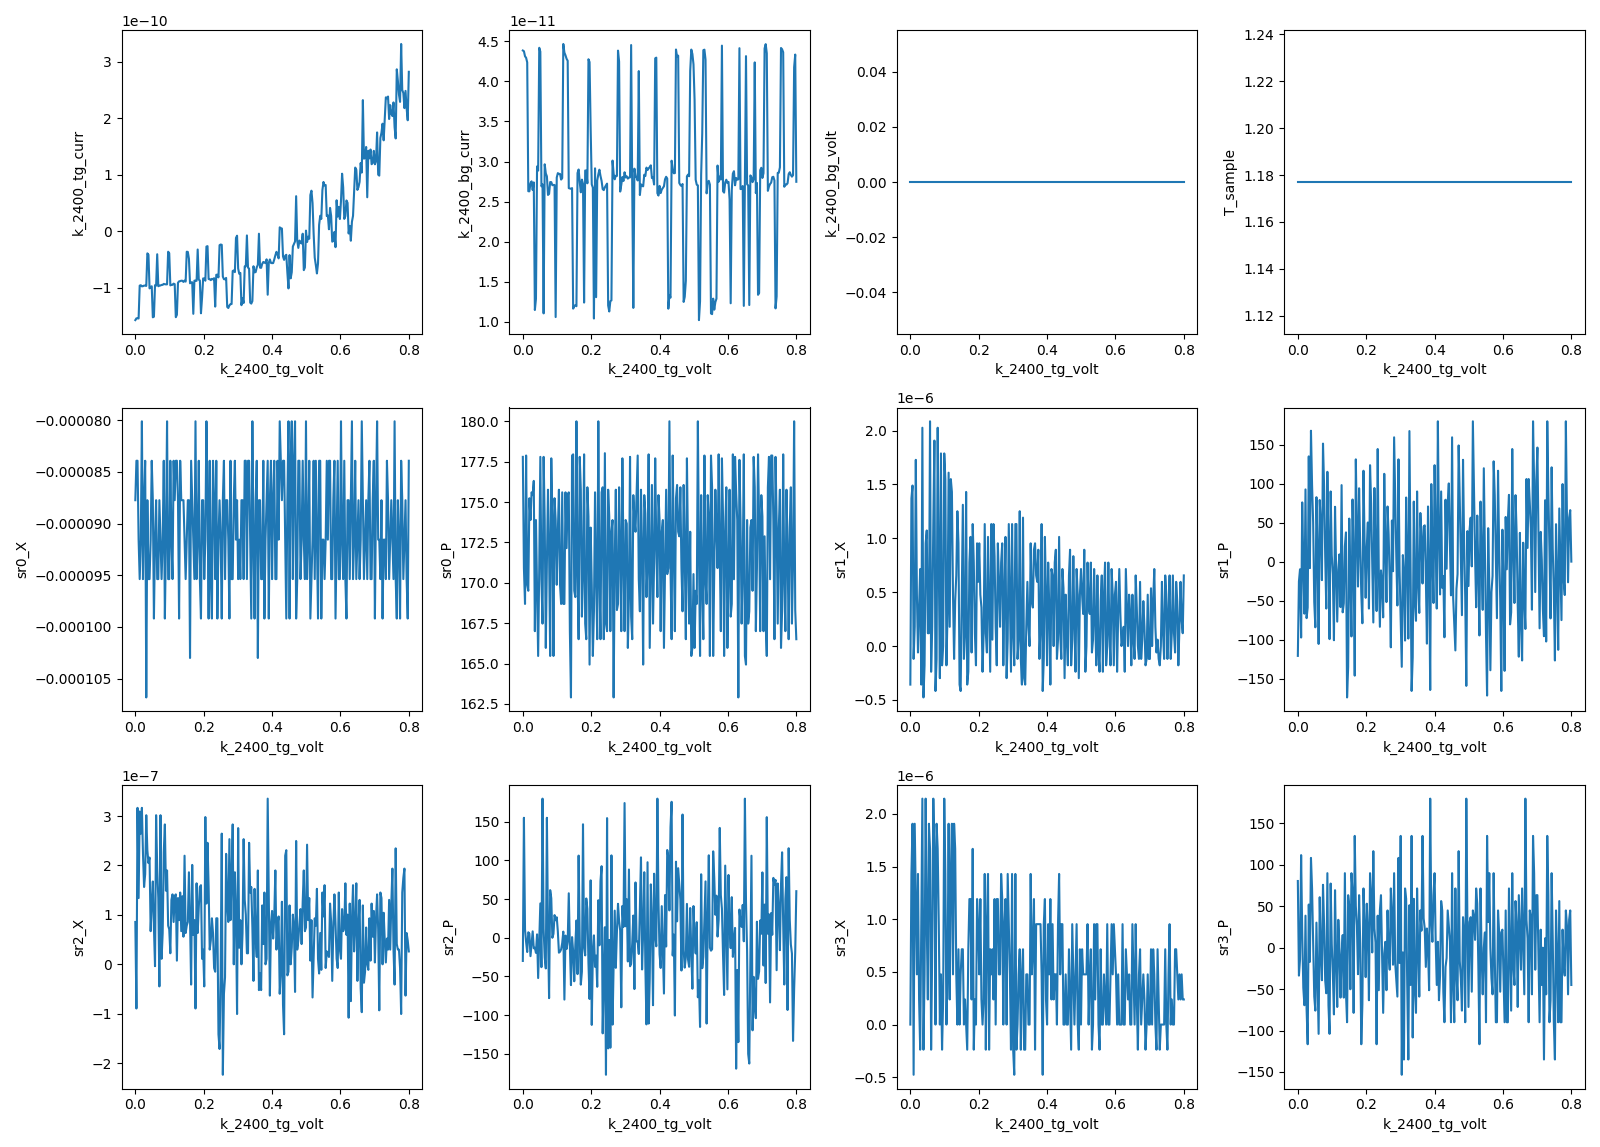

2026-08-18 23:28:39,184 [INFO] Completed in 0h 9m 15s


2026-08-18 23:28:39,185 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260818-vti-01\data\0\data.tsv.gz


2026-08-18 23:28:39,867 [INFO] Ramping k_2400_tg_volt: 0.7991936 -> 0


leg done: k_2400_tg 0 -> +0.8 V


2026-08-18 23:28:41,592 [INFO] Ramping k_2400_tg_volt: -0.000928023 -> 0


2026-08-18 23:28:42,108 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-08-18 23:28:42,134 [INFO] Starting sweep with ID 1


2026-08-18 23:28:42,134 [INFO] Minimum duration 0h 4m 11s


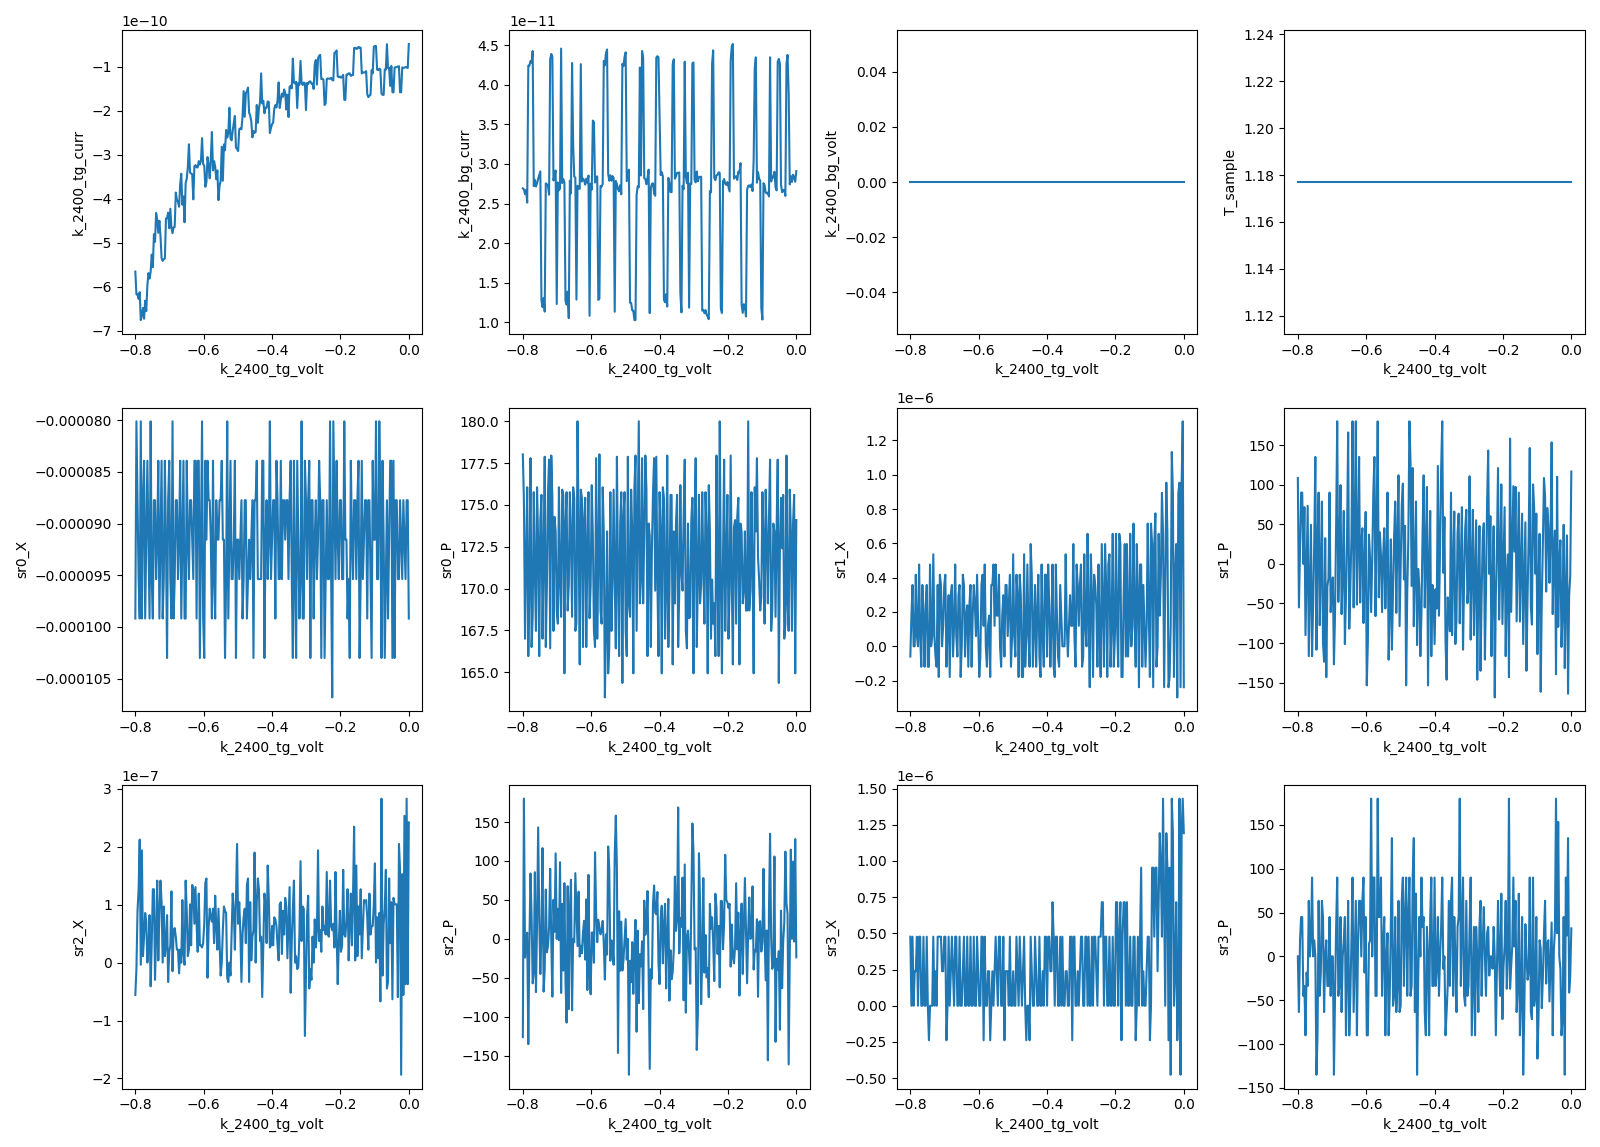

2026-08-18 23:37:59,433 [INFO] Completed in 0h 9m 16s


2026-08-18 23:37:59,433 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260818-vti-01\data\1\data.tsv.gz


2026-08-18 23:38:00,115 [INFO] Ramping k_2400_tg_volt: -0.7986079 -> 0


leg done: k_2400_tg 0 -> -0.8 V


2026-08-18 23:38:01,860 [INFO] Ramping k_2400_tg_volt: 0.001538845 -> 0


2026-08-18 23:38:02,370 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-08-18 23:38:02,393 [INFO] Starting sweep with ID 2


2026-08-18 23:38:02,394 [INFO] Minimum duration 0h 4m 11s


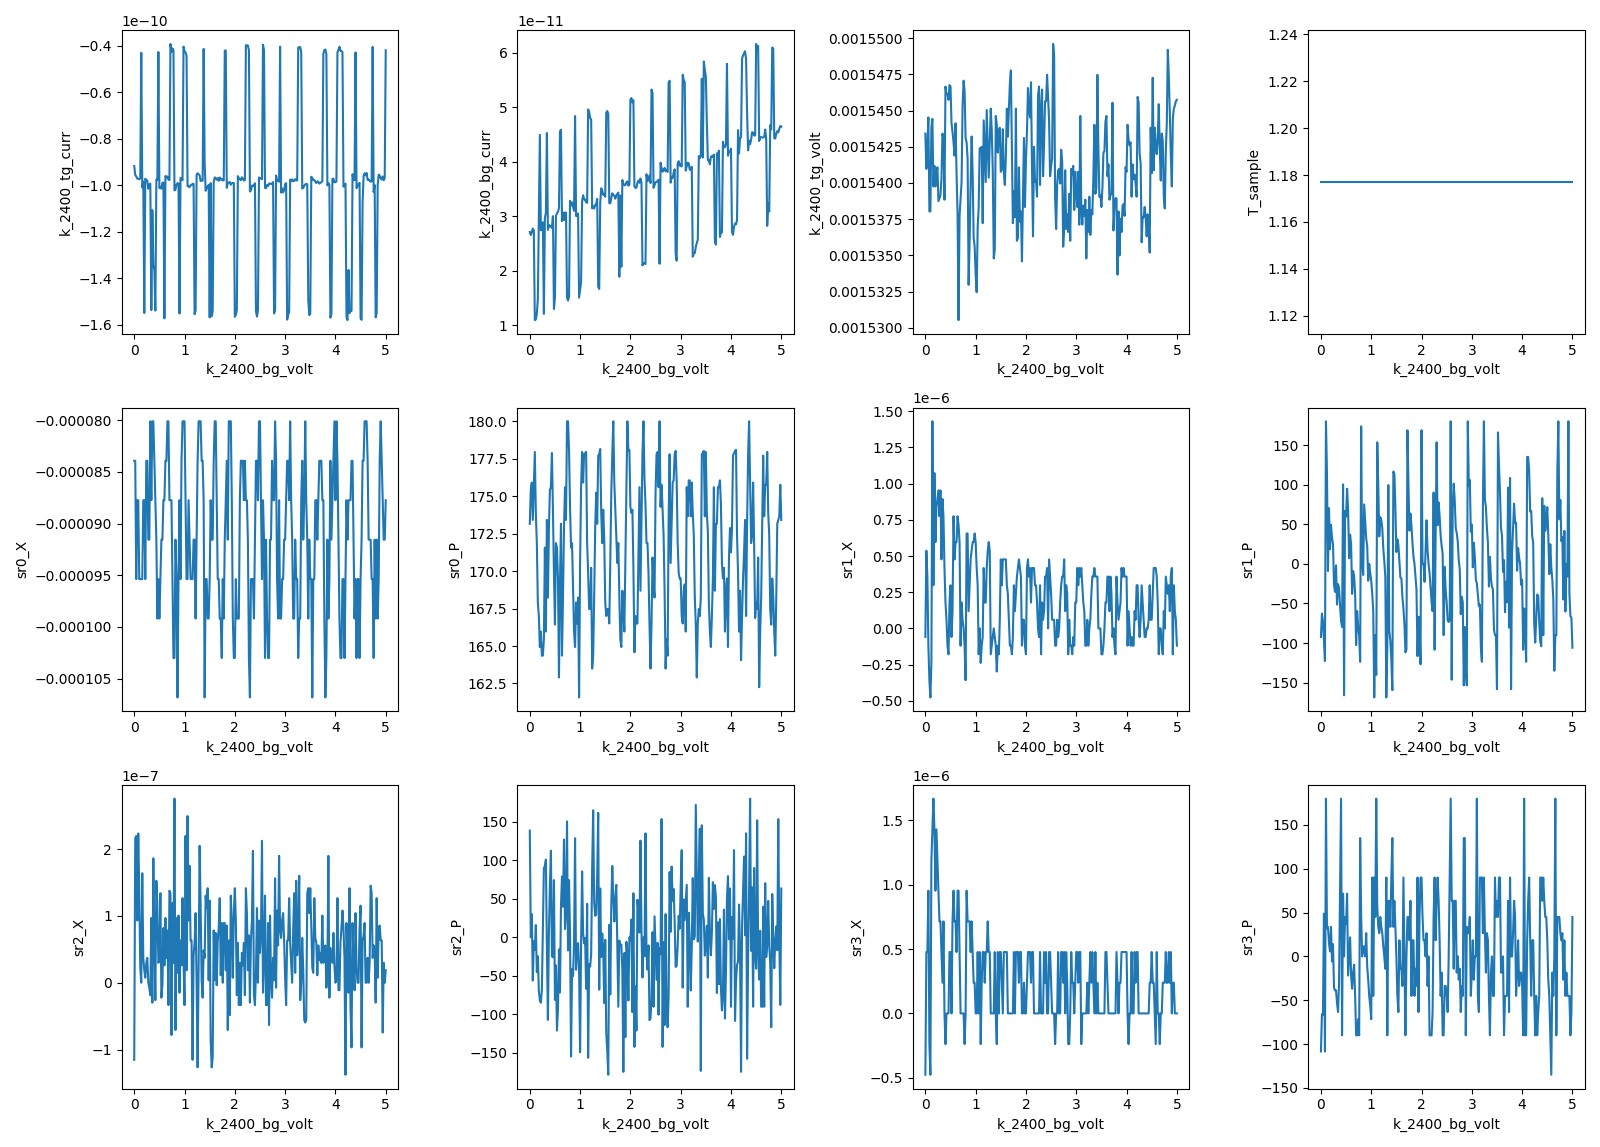

2026-08-18 23:48:09,024 [INFO] Completed in 0h 10m 5s


2026-08-18 23:48:09,025 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260818-vti-01\data\2\data.tsv.gz


2026-08-18 23:48:09,538 [INFO] Ramping k_2400_bg_volt: 5.0 -> 0


leg done: k_2400_bg 0 -> +5 V


2026-08-18 23:48:16,593 [INFO] Ramping k_2400_tg_volt: 0.001539859 -> 0


2026-08-18 23:48:17,114 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-08-18 23:48:17,132 [INFO] Starting sweep with ID 3


2026-08-18 23:48:17,133 [INFO] Minimum duration 0h 4m 11s


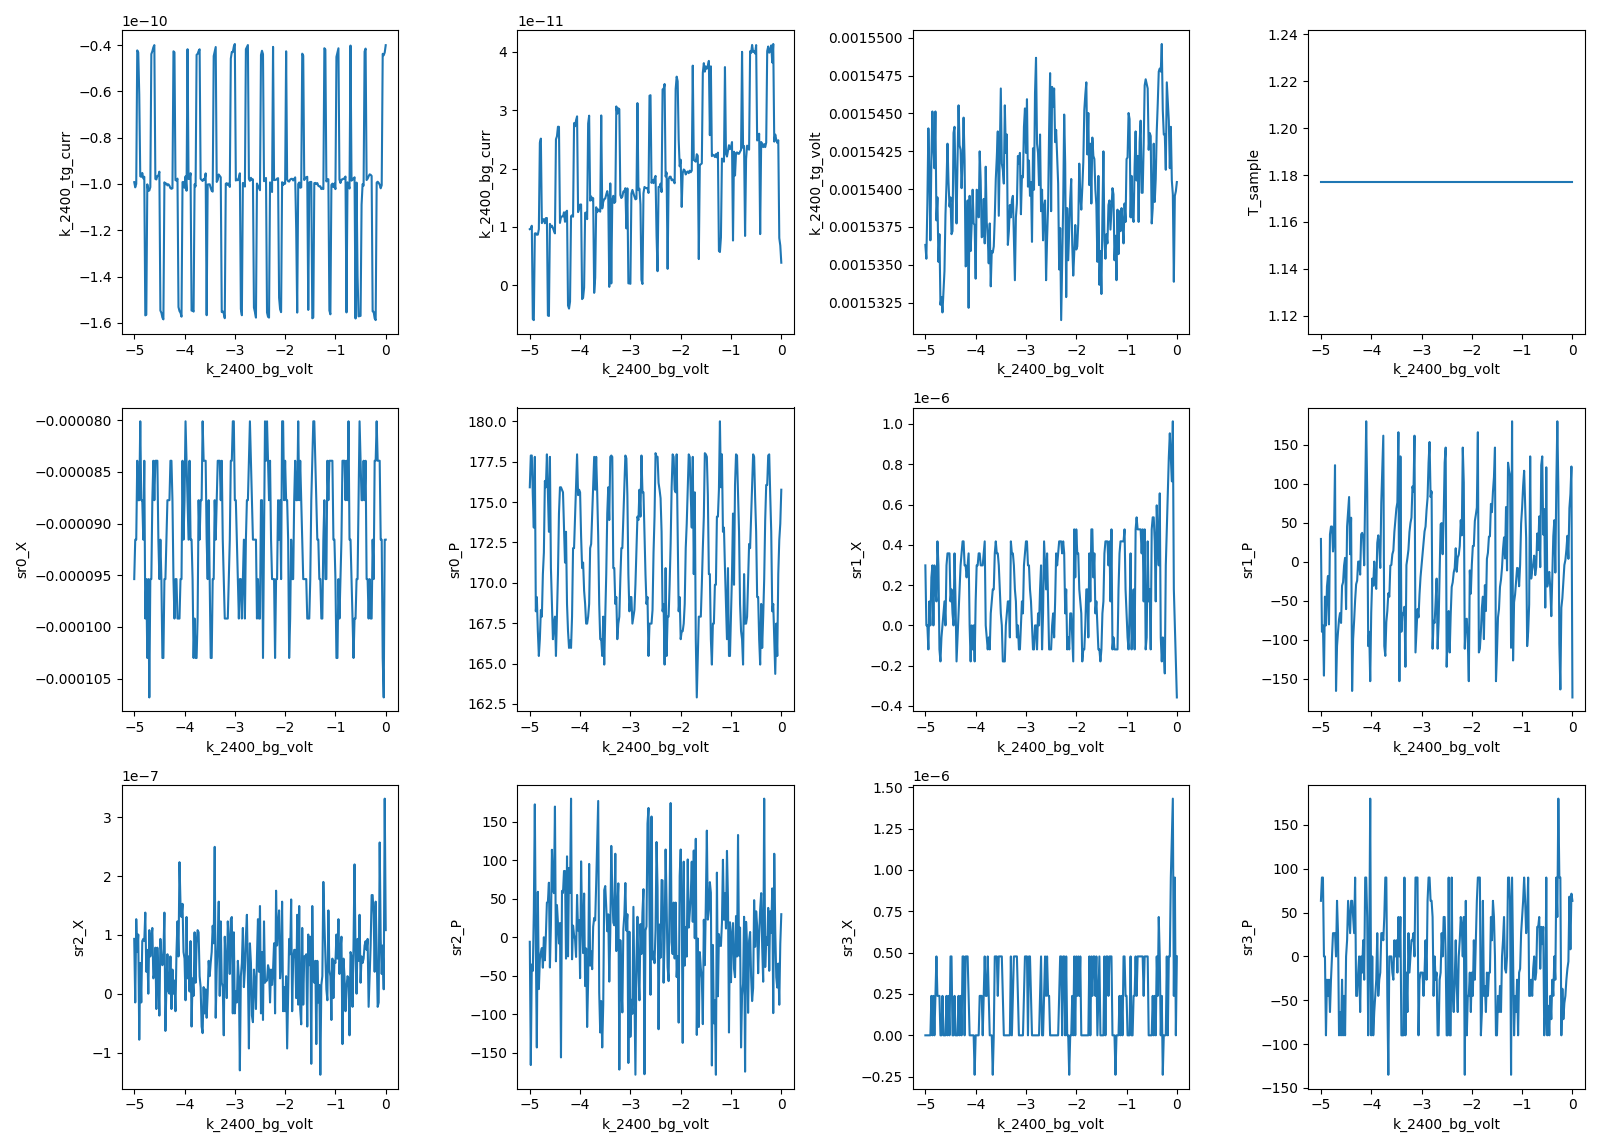

2026-08-18 23:58:23,976 [INFO] Completed in 0h 10m 5s


2026-08-18 23:58:23,977 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260818-vti-01\data\3\data.tsv.gz


2026-08-18 23:58:24,479 [INFO] Ramping k_2400_bg_volt: -5.0 -> 0


leg done: k_2400_bg 0 -> -5 V
Cell A complete — all 4 legs run, gates parked at 0.


In [18]:
# === Gate C — gate-current-sanity-check: Cell A (all 4 legs) ===
# Sweep each gate 0 -> each card limit, other gate parked at 0, Si parked at 0.
# Watch: lock-in X nonzero & varying = alive; gate curr in pA on charging slope = safe.

# --- preconditions (state this cell assumes but does not set) ---
_B = magnet.field()
_T = T_sample()
_vtg, _vbg, _vsi = k_tg.volt(), k_bg.volt(), dc205.voltage()
print(f"preconditions: B={_B:+.4f} T (expect ~0), T_sample={_T:.3f} K (expect ~1.2-1.3), "
      f"Vtg={_vtg:+.4f}, Vbg={_vbg:+.4f}, Vsi={_vsi:+.4f} (expect all ~0)")
assert abs(_B) < 0.02, f"B={_B:+.4f} T not ~0 — stop"
assert _T < 1.5, f"T_sample={_T:.3f} K not at base — stop"
assert abs(_vtg) < 0.01 and abs(_vbg) < 0.01 and abs(_vsi) < 0.01, "gates not parked at 0 — stop"

# pA-floor gate-current readback (Cell B resets nplci to 1; rangei 1e-9 stays —
# the right default for leakage monitoring; 1.05 nA full scale)
print("rangei before:", k_tg.rangei(), k_bg.rangei())
k_tg.nplci(10); k_bg.nplci(10)
k_tg.rangei(1e-9); k_bg.rangei(1e-9)

# liveness drive ~1 nA: 10 mV across the 10 MOhm bias resistor (don't inherit residual amp)
sr1.amplitude(0.010)

legs = [
    (k_tg, TG_MAX), (k_tg, TG_MIN),   # 0 -> +/-0.8 V
    (k_bg, BG_MAX), (k_bg, BG_MIN),   # 0 -> +/-5.0 V
]
n_pts, delay = 251, 1
lockins = [sr0, sr1, sr2, sr3]

for gate, v_endpoint in legs:
    other = k_bg if gate is k_tg else k_tg
    mc = {**meas_config,
          "sample_temperature:": T_sample(),
          "Si (V)": dc205.voltage(),
          "comments": (f"gate-current-sanity-check: {gate.name} 0 -> {v_endpoint:+g} V "
                       f"(card limit), {other.name} parked 0, Vsi=0, B~0, "
                       f"nplci=10 rangei=1e-9, drive 10 mV / 10 MOhm ~ 1 nA @ 13.777 Hz")}
    s = sweep.AsyncStation(mc)
    s.add_comment('gate-current-sanity-check')
    s.add_comment(f'gate: {gate.name}')
    s.add_comment(f'leg: 0 -> {v_endpoint:+g} V (card limit)')

    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)

    xp = gate.volt
    s.fp(other.volt)
    s.fp(gate.curr).fp(other.curr)
    s.fp(T_sample)
    s.plot(xp, k_tg.curr)
    s.plot(xp, k_bg.curr)
    s.plot(xp, other.volt)
    s.plot(xp, T_sample)
    for lia in lockins:
        s.fp(lia.X).fp(lia.P)
        s.plot(xp, lia.X)
        s.plot(xp, lia.P)

    try:
        s.sweep(gate.volt, np.linspace(0, v_endpoint, n_pts), delay=delay)
    finally:
        s.ramp(gate.volt, 0)
    print(f"leg done: {gate.name} 0 -> {v_endpoint:+g} V")

print("Cell A complete — all 4 legs run, gates parked at 0.")


In [19]:
# === Gate C — Cell B: reset gate-current nplci ===
# Run only after every leg looked safe. Undo Cell A's nplci bump; rangei stays
# at 1e-9 (pA-resolution leakage watch is the session default). Validators were
# committed in SAFETIES — print to confirm, nothing re-committed.
k_tg.nplci(1)
k_bg.nplci(1)
print("k_tg.volt validator:", k_tg.volt.vals)
print("k_bg.volt validator:", k_bg.volt.vals)
print("nplci:", k_tg.nplci(), k_bg.nplci(), "| rangei:", k_tg.rangei(), k_bg.rangei())


k_tg.volt validator: <Numbers -0.8<=v<=0.8>
k_bg.volt validator: <Numbers -5.0<=v<=5.0>
nplci: 1.0 1.0 | rangei: 1.05e-06 1.05e-06


## HERA — Si contact-doping survey (E1 auto; Si operator-allowlisted)

> **11:30** · silicon-backgate-survey (1D contact-doping): k\_si 0->+20 V, 101 pts @ 0.2 V, delay 1s, TG=BG=0, B~0, endpoint held · **ETA ~11:36** (≈6 min)

Operator rulings recorded: TG leakage accepted, full card range stays; Si gate allowlisted to card limits (±20 V). Gate C liveness was contact-limited (R_SD ≈ 109 MΩ, unmodulated by TG/BG — runs 0–3), so before any gatemap the contacts need Si doping. This is the 1D contact-doping reduction of silicon-backgate-survey (Flavor C shape): V_si 0 → +20 V at the DC205's 0.5 V/s, TG = BG = 0, watching drain current (sr0) recover toward the 1 nA drive, all Rxx channels, and TG/BG currents for any Si-coupling path. Endpoint is held at +20 V — the operating point gets picked from this data and approached without an extra SiO₂ re-traverse; if the electron side doesn't recover the contacts I'll come back through 0 to the hole side.

Checkpoints: first rows via hera-watch; abort if TG/BG currents turn up (Si has no current readback — the Keithleys are the only leak monitors).

preconditions: B=+0.0061 T (~0), T=1.179 K (base), Vtg=+0.0016, Vbg=+0.0000, Vsi=+0.0000 (all ~0)
2026-08-19 11:30:49,943 [INFO] Ramping k_2400_tg_volt: 0.001539048 -> 0


2026-08-19 11:30:50,020 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-08-19 11:30:50,041 [INFO] Starting sweep with ID 4


2026-08-19 11:30:50,042 [INFO] Minimum duration 0h 1m 41s


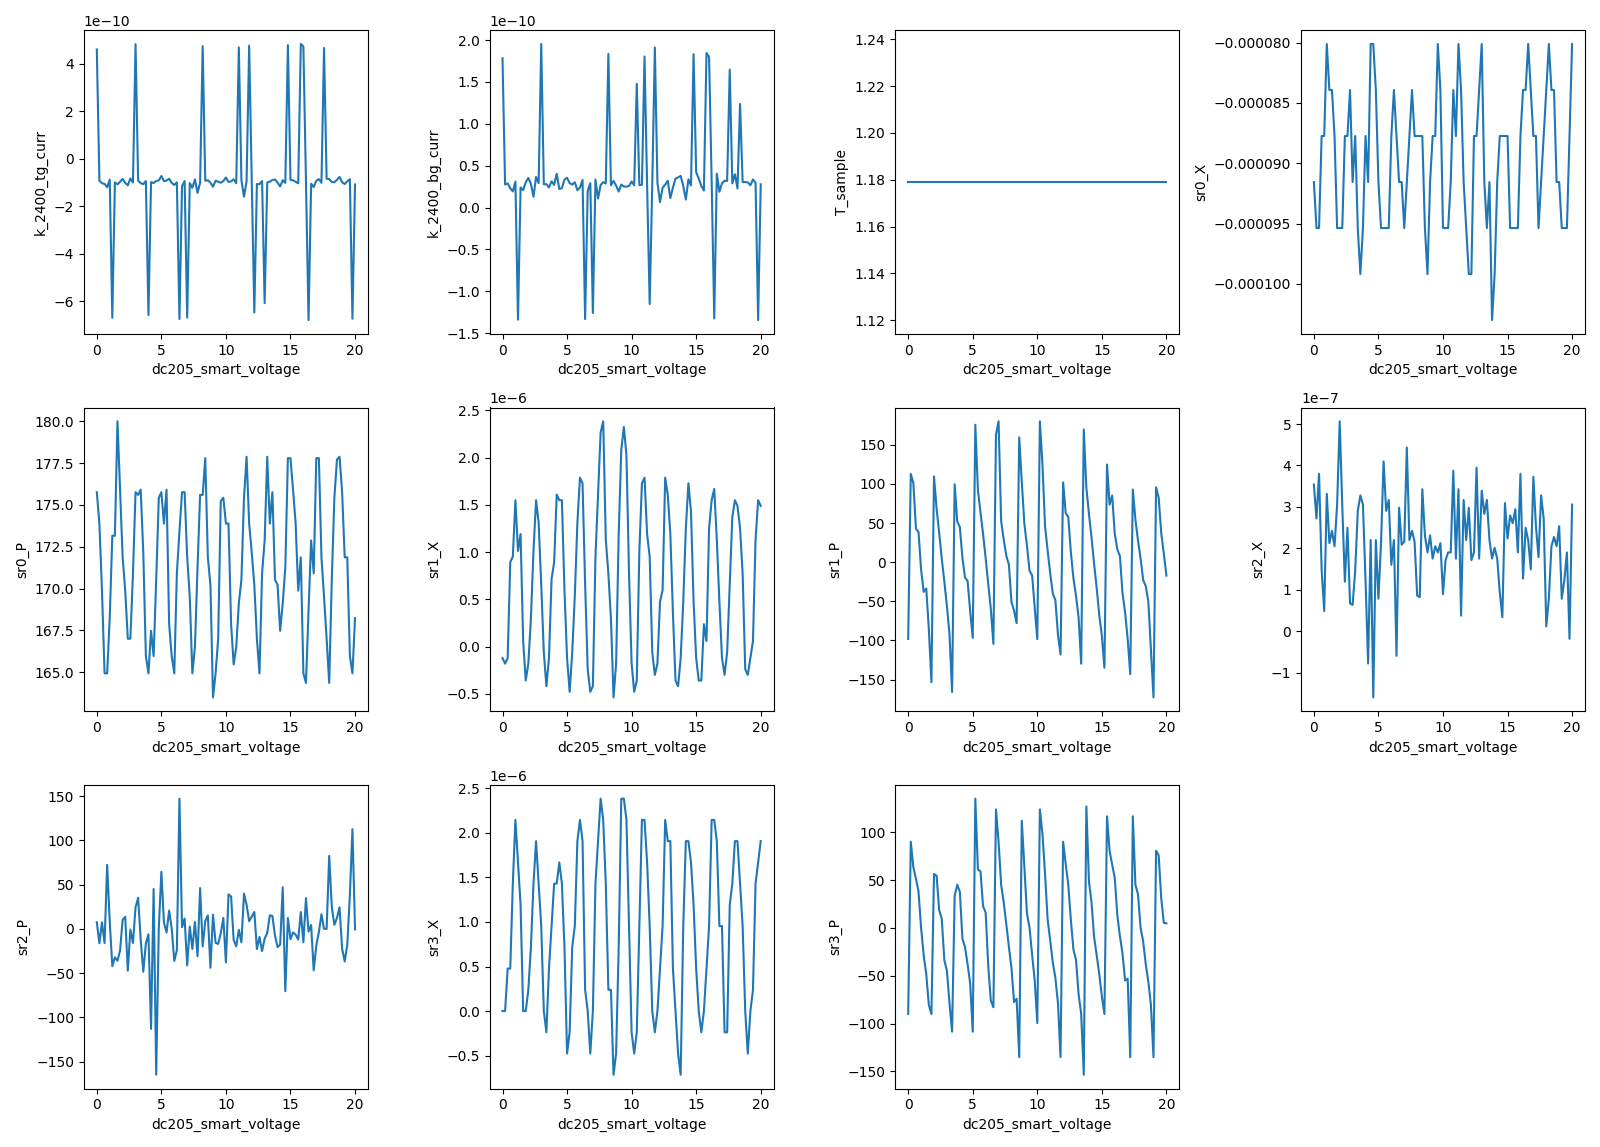

2026-08-19 11:33:26,974 [INFO] Completed in 0h 2m 36s


2026-08-19 11:33:26,974 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260818-vti-01\data\4\data.tsv.gz


V_si held at +20.00 V — operating point decided from the data


In [20]:
# === Si contact-doping survey: k_si 0 -> +20 V (operator-allowlisted 2026-08-19) ===
# Goal: recover the contacts (R_SD ~ 109 MOhm at Vsi=0). Graphite BG screens the
# channel, so Si gates the contact/lead regions only (device card). Watch drain
# current (sr0) come alive; endpoint HELD at +20 V until the operating point is
# picked from the data (no blind re-traverse of the SiO2).

# --- preconditions ---
_B, _T = magnet.field(), T_sample()
_vtg, _vbg, _vsi = k_tg.volt(), k_bg.volt(), dc205.voltage()
print(f"preconditions: B={_B:+.4f} T (~0), T={_T:.3f} K (base), "
      f"Vtg={_vtg:+.4f}, Vbg={_vbg:+.4f}, Vsi={_vsi:+.4f} (all ~0)")
assert abs(_B) < 0.02 and _T < 1.5, "B/T precondition failed — stop"
assert abs(_vtg) < 0.01 and abs(_vbg) < 0.01 and abs(_vsi) < 0.01, "gates not at 0 — stop"

mc = {**meas_config,
      "sample_temperature:": T_sample(),
      "Si (V)": dc205.voltage(),
      "comments": ("silicon-backgate-survey, 1D contact-doping flavor: k_si 0 -> +20 V "
                   "@ 0.5 V/s, TG=BG=0, B~0, drive 10 mV / 10 MOhm ~ 1 nA. Si gates "
                   "contacts only (graphite BG screens channel). Operator allowlisted "
                   "Si to card limits 2026-08-19.")}
s = sweep.AsyncStation(mc)
s.add_comment('silicon-backgate-survey')
s.add_comment('flavor: 1D k_si contact-doping; V_si 0 -> +20 V, TG=BG=0')

s.ramp(k_tg.volt, 0)
s.ramp(k_bg.volt, 0)

xp = dc205.smart_voltage
s.fp(k_tg.curr).fp(k_bg.curr)
s.fp(T_sample)
s.plot(xp, k_tg.curr)
s.plot(xp, k_bg.curr)
s.plot(xp, T_sample)
for lia in [sr0, sr1, sr2, sr3]:
    s.fp(lia.X).fp(lia.P)
    s.plot(xp, lia.X)
    s.plot(xp, lia.P)

try:
    s.sweep(dc205.smart_voltage, np.linspace(0, 20, 101), delay=1)
finally:
    print(f"V_si held at {dc205.voltage():+.2f} V — operating point decided from the data")


## HERA — Si contact-doping, hole side (E1 auto)

> **11:35** · silicon-backgate-survey hole side: k\_si +20 -> -20 V, 201 pts @ 0.2 V, delay 1s, TG=BG=0, endpoint held · **ETA ~11:43** (≈8 min)

Run 4 (0 → +20 V): drain pinned at ~88 pA the whole way — electron-side Si doping does not open the contacts. Phase check on disk: sr0 at ~172° ± 4° = in-phase resistive through the inverting Ithaco, so R_SD ≈ 109 MΩ is real, not capacitive pickup. If the contact metal p-dopes the leads, positive V_si builds p–n junctions and negative opens them — trying the hole side: +20 → −20 V through zero, endpoint held; the 0…+20 overlap doubles as a hysteresis check. Same monitors; TG/BG Keithleys carry the leak watch (medians, not the DC205-step transients).

preconditions: B=+0.0061 T (~0), T=1.179 K (base), Vtg=+0.0015, Vbg=+0.0000 (~0), Vsi=+20.00 (expect +20)
2026-08-19 11:35:20,453 [INFO] Ramping k_2400_tg_volt: 0.001541077 -> 0


2026-08-19 11:35:20,527 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-08-19 11:35:20,545 [INFO] Starting sweep with ID 5


2026-08-19 11:35:20,547 [INFO] Minimum duration 0h 3m 21s


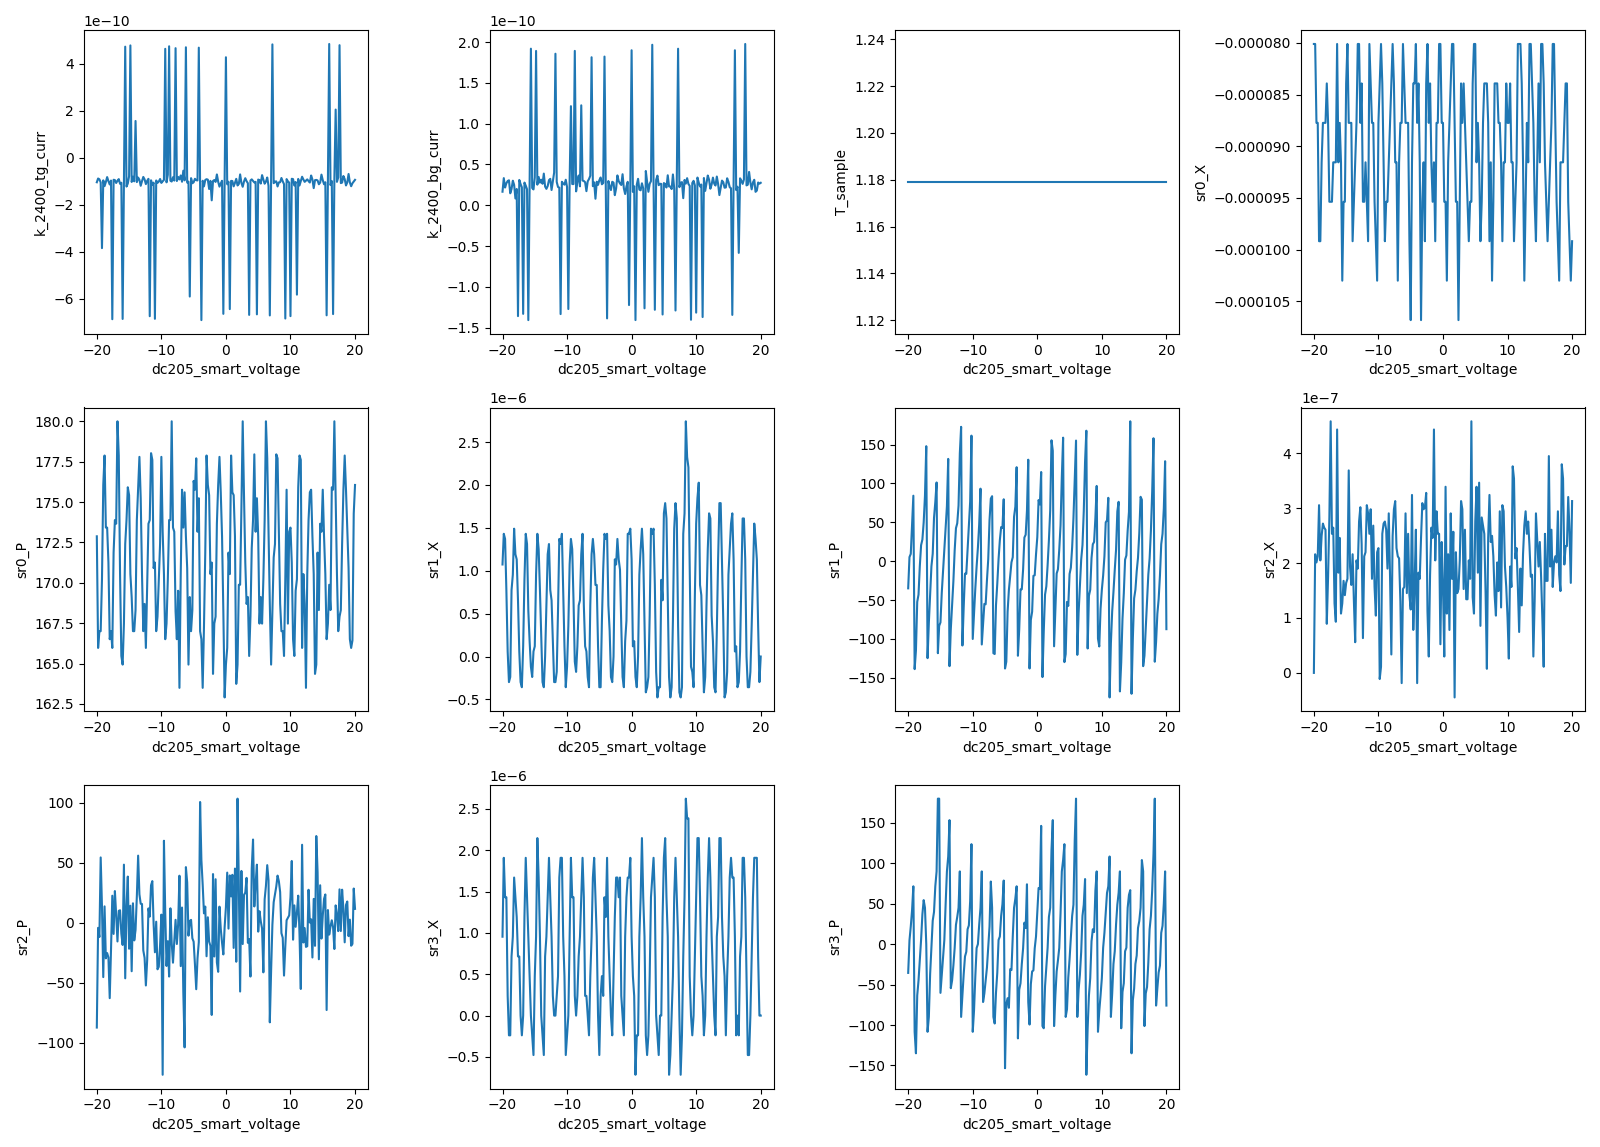

2026-08-19 11:40:32,744 [INFO] Completed in 0h 5m 11s


2026-08-19 11:40:32,744 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260818-vti-01\data\5\data.tsv.gz


V_si held at -20.00 V — operating point decided from the data


In [21]:
# === Si contact-doping survey, hole side: k_si +20 -> -20 V ===
# Electron side (run 4) flat: drain pinned ~88 pA to +20 V. sr0 phase ~172 deg
# (resistive through the inverting Ithaco) => real R_SD ~ 109 MOhm, not pickup.
# Sweep down through 0 to -20 V; overlap 0..+20 doubles as a hysteresis check.

# --- preconditions ---
_B, _T = magnet.field(), T_sample()
_vtg, _vbg, _vsi = k_tg.volt(), k_bg.volt(), dc205.voltage()
print(f"preconditions: B={_B:+.4f} T (~0), T={_T:.3f} K (base), "
      f"Vtg={_vtg:+.4f}, Vbg={_vbg:+.4f} (~0), Vsi={_vsi:+.2f} (expect +20)")
assert abs(_B) < 0.02 and _T < 1.5, "B/T precondition failed — stop"
assert abs(_vtg) < 0.01 and abs(_vbg) < 0.01, "TG/BG not at 0 — stop"
assert abs(_vsi - 20.0) < 0.1, f"Vsi={_vsi:+.2f}, expected +20 (held from run 4) — stop"

mc = {**meas_config,
      "sample_temperature:": T_sample(),
      "Si (V)": dc205.voltage(),
      "comments": ("silicon-backgate-survey, 1D contact-doping flavor, hole side: "
                   "k_si +20 -> -20 V @ 0.5 V/s, TG=BG=0, B~0, drive 10 mV / 10 MOhm. "
                   "Run 4 (0->+20) flat; downsweep overlap is the hysteresis check.")}
s = sweep.AsyncStation(mc)
s.add_comment('silicon-backgate-survey')
s.add_comment('flavor: 1D k_si contact-doping; V_si +20 -> -20 V, TG=BG=0')

s.ramp(k_tg.volt, 0)
s.ramp(k_bg.volt, 0)

xp = dc205.smart_voltage
s.fp(k_tg.curr).fp(k_bg.curr)
s.fp(T_sample)
s.plot(xp, k_tg.curr)
s.plot(xp, k_bg.curr)
s.plot(xp, T_sample)
for lia in [sr0, sr1, sr2, sr3]:
    s.fp(lia.X).fp(lia.P)
    s.plot(xp, lia.X)
    s.plot(xp, lia.P)

try:
    s.sweep(dc205.smart_voltage, np.linspace(20, -20, 201), delay=1)
finally:
    print(f"V_si held at {dc205.voltage():+.2f} V — operating point decided from the data")


## HERA — liveness discriminators (E1 auto, point reads, ~1 min)

> **11:42** · point reads: sr0 X/P + Rxx at f={6.8,13.8,27.8} Hz and A={10,50,100} mV; restore 13.777 Hz / 10 mV · **ETA ~11:44** (≈2 min)

Runs 4–5: drain pinned ~88 pA across Si ±20 V, TG ±0.8 V, BG ±5 V — flat against every gate. A real 109 MΩ device path should modulate somewhere in that space; total flatness points at a fixed parasitic S–D path (breakout/harness) with the device open or blocking. Two discriminators before flagging hardware: (1) frequency scaling at 6.8/13.8/27.8 Hz — capacitive path scales with f, resistive doesn't; (2) drive linearity 10/50/100 mV — nonlinearity would indicate barrier conduction. Read-only apart from sr1 freq/amplitude, both restored in-cell.

In [22]:
# === Liveness discriminators: is the 90 pA even device current? ===
# R_SD ~ 109 MOhm is flat vs TG (+/-0.8), BG (+/-5), Si (+/-20) — total gate-
# flatness suggests a fixed parasitic S-D path with the device open/blocking.
# Test 1: frequency scaling (capacitive path: |I| ~ f; resistive: flat).
# Test 2: drive-amplitude linearity + headroom for a high-drive BG look.
# All settings restored at the end; no run dir (point reads, printed).

_T = T_sample()
print(f"preconditions: T={_T:.3f} K, Vsi={dc205.voltage():+.2f} V (held -20), "
      f"Vtg={k_tg.volt():+.4f}, Vbg={k_bg.volt():+.4f}")
assert _T < 1.5

def _read(tag):
    x0, p0 = sr0.X(), sr0.P()
    print(f"{tag}: sr0 X={x0*1e6:+8.2f} uV P={p0:+7.1f} deg  -> |I|={abs(x0)/1e6*1e12:7.1f} pA | "
          f"sr1 X={sr1.X()*1e9:+8.1f} nV  sr2 X={sr2.X()*1e9:+8.1f} nV  sr3 X={sr3.X()*1e9:+8.1f} nV")

print("--- Test 1: frequency (10 mV drive) ---")
for f in [6.777, 13.777, 27.777]:
    sr1.frequency(f)
    interruptible_sleep(8)   # >= 10 tau of the slowest (sr0, 0.3 s) + margin at low f
    _read(f"f={f:6.3f} Hz")
sr1.frequency(13.777)

print("--- Test 2: amplitude linearity (13.777 Hz) ---")
for a in [0.010, 0.050, 0.100]:
    sr1.amplitude(a)
    interruptible_sleep(5)
    _read(f"A={a*1e3:5.1f} mV")
sr1.amplitude(0.010)
interruptible_sleep(3)
_read("restored 10 mV")
print("settings restored: f=13.777 Hz, A=10 mV")


preconditions: T=1.179 K, Vsi=-20.00 V (held -20), Vtg=+0.0015, Vbg=+0.0000
--- Test 1: frequency (10 mV drive) ---


f= 6.777 Hz: sr0 X=  -95.37 uV P= +173.9 deg  -> |I|=   95.4 pA | sr1 X=  +119.2 nV  sr2 X=  +465.7 nV  sr3 X=  +715.3 nV


f=13.777 Hz: sr0 X=  -91.55 uV P= +165.5 deg  -> |I|=   91.6 pA | sr1 X=  +834.5 nV  sr2 X=  +324.1 nV  sr3 X= +1430.5 nV


f=27.777 Hz: sr0 X=  -80.11 uV P= +159.4 deg  -> |I|=   80.1 pA | sr1 X=  +596.0 nV  sr2 X=  +163.9 nV  sr3 X=    +0.0 nV
--- Test 2: amplitude linearity (13.777 Hz) ---


A= 10.0 mV: sr0 X=  -91.55 uV P= +167.5 deg  -> |I|=   91.6 pA | sr1 X=  +774.9 nV  sr2 X=  +234.7 nV  sr3 X= +1192.1 nV


A= 50.0 mV: sr0 X= -492.10 uV P= +171.9 deg  -> |I|=  492.1 pA | sr1 X= +2443.8 nV  sr2 X=  +823.3 nV  sr3 X= +2622.6 nV


A=100.0 mV: sr0 X= -988.01 uV P= +172.1 deg  -> |I|=  988.0 pA | sr1 X= +5662.5 nV  sr2 X= +1613.1 nV  sr3 X= +6198.9 nV


restored 10 mV: sr0 X= -106.81 uV P= +169.0 deg  -> |I|=  106.8 pA | sr1 X=  +178.8 nV  sr2 X=  +365.1 nV  sr3 X=  +476.8 nV
settings restored: f=13.777 Hz, A=10 mV


## HERA — CNP scoping cut: 1D TG at V_bg = 0 (E1 auto)

> **11:45** · cnp scoping: k\_tg -0.8 -> +0.8 V, 321 pts @ 5 mV, delay 1s, Vbg=0, Vsi 0 (parked from -20), drive 100 mV, sens sr0 10mV / Rxx 1mV · **ETA ~11:55** (≈10 min)

Cheap-first before the gatemap: one 5 mV-step TG cut at V_bg = 0, V_si parked back to 0 (Si is inert on this device — runs 4–5). New campaign config for the contact reality: 100 mV drive (ohmic-verified in the discriminator cell), sr0 at 10 mV fs (10 nA absolute ceiling — cannot clip), Rxx channels at 1 mV fs (near-CNP rows may rail; the cnp recipe's robust-fit guard covers that), sr0 τ 0.1 s so dwell 1 s = 10τ. Rxx downstream = sr_X/(sr0 current) per point — the T_SD contact sets I, not the bias resistor, so hera-watch's nominal-I_bias R values will read ~10× high; I read ratios, not absolutes. Expect the CNP near V_tg ≈ 0: this cut answers whether the ridge resolves and at what R scale, and prices the map.

preconditions: B=+0.0060 T (~0), T=1.179 K (base), Vtg=+0.0015, Vbg=+0.0000 (~0), Vsi=-20.00 (-20, ramping to 0)


drive 100 mV @ 13.777 Hz; sens sr0=10mV sr1/2/3=1mV; tau sr0=0.1s
2026-08-19 11:46:55,532 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-08-19 11:46:55,619 [INFO] Ramping k_2400_tg_volt: 0.001552228 -> -0.8


2026-08-19 11:47:01,703 [INFO] Starting sweep with ID 6


2026-08-19 11:47:01,703 [INFO] Minimum duration 0h 5m 21s


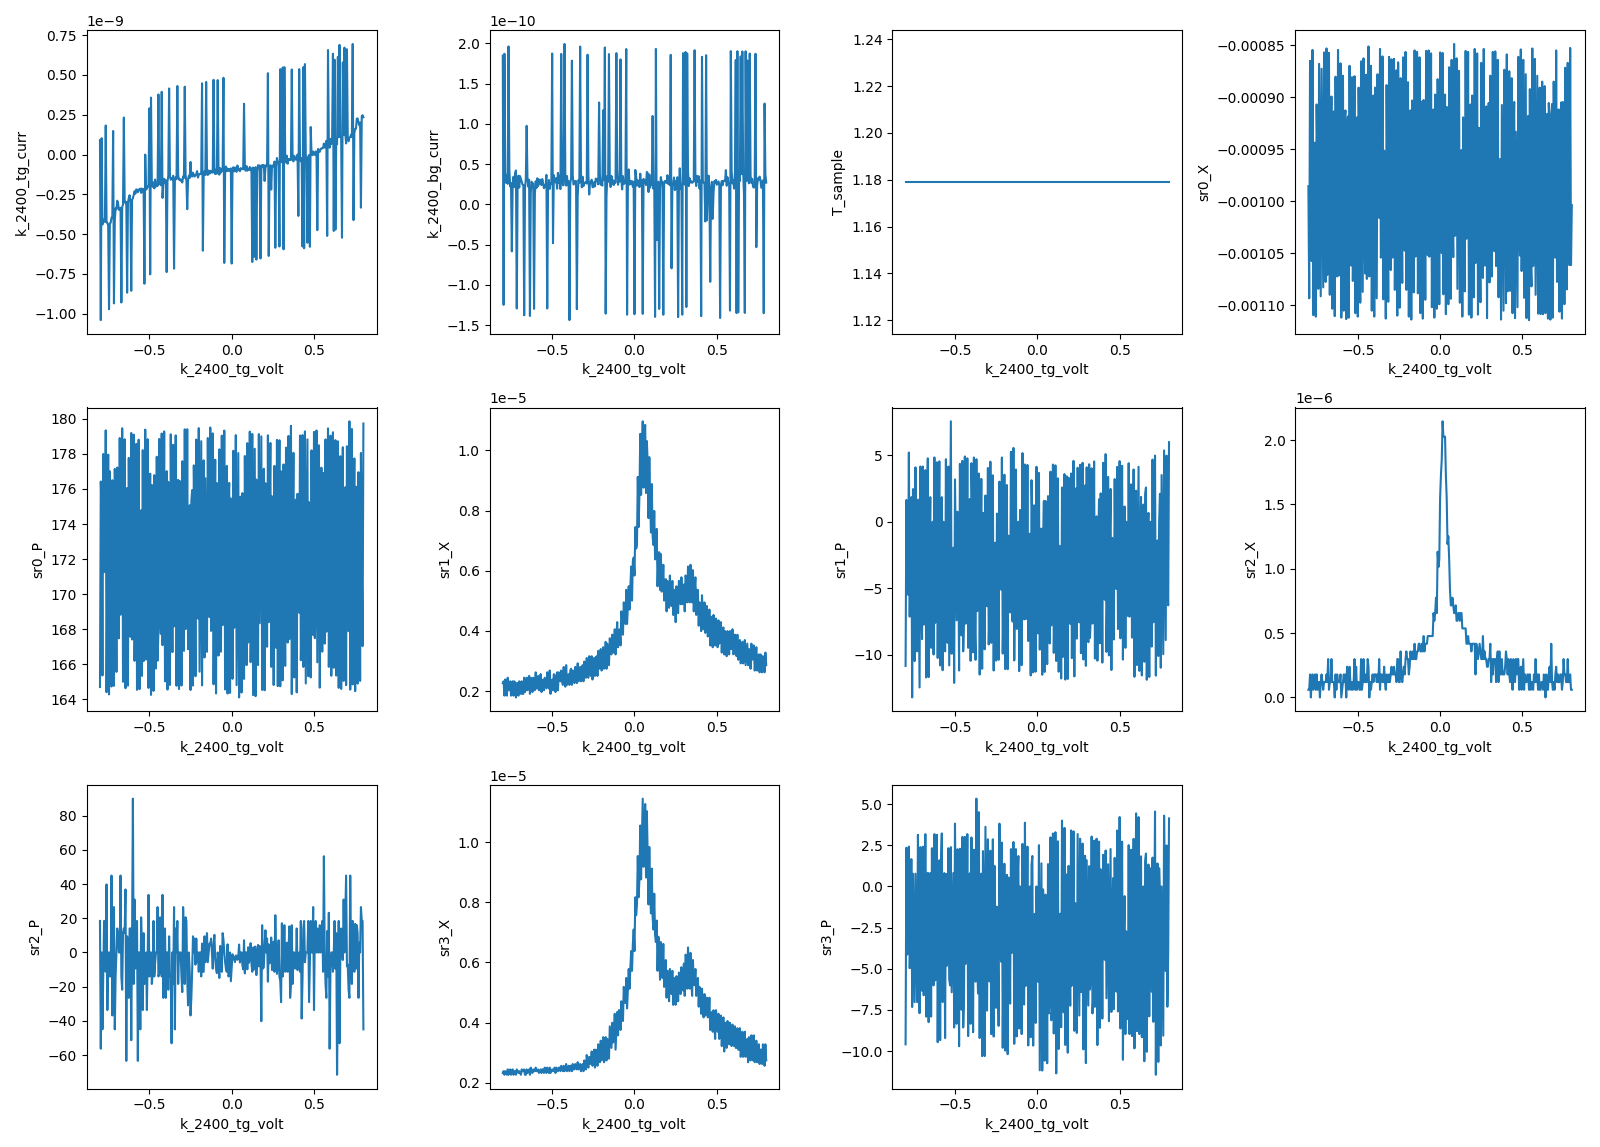

2026-08-19 11:53:00,050 [INFO] Completed in 0h 5m 57s


2026-08-19 11:53:00,051 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260818-vti-01\data\6\data.tsv.gz


2026-08-19 11:53:00,128 [INFO] Ramping k_2400_tg_volt: 0.7991988 -> 0


cut done; TG parked at 0


In [23]:
# === CNP scoping cut: 1D TG sweep at Vbg=0, 100 mV drive (E1 auto) ===
# Purpose: see the CNP cross-section + calibrate sensitivities before pricing
# the first gatemap. Per-point current normalization downstream: Rxx = sr_X /
# (sr0_X / sr0_gain) — the T_SD contact (~109 MOhm) sets the current, not the
# 10 MOhm bias resistor, so nominal I_bias is wrong; sr0 is the truth.

# --- preconditions ---
_B, _T = magnet.field(), T_sample()
print(f"preconditions: B={_B:+.4f} T (~0), T={_T:.3f} K (base), "
      f"Vtg={k_tg.volt():+.4f}, Vbg={k_bg.volt():+.4f} (~0), Vsi={dc205.voltage():+.2f} (-20, ramping to 0)")
assert abs(_B) < 0.02 and _T < 1.5, "B/T precondition failed — stop"
assert abs(k_bg.volt()) < 0.01, "BG not at 0 — stop"

# Si is inert on this device (runs 4-5): park at 0 (from held -20; ~40 s at 0.5 V/s)
dc205.smart_voltage(0.0)

# measurement config for the campaign's contact reality:
sr1.amplitude(0.100)       # 100 mV drive — ohmic-verified to here (discriminator cell)
sr0.sensitivity(0.01)      # 10 mV fs = 10 nA absolute ceiling (100 mV / 10 MOhm) — can never clip
sr0.time_constant(0.1)     # 0.3 -> 0.1 s; dwell 1 s = 10 tau (state0 holds the original)
sr1.sensitivity(0.001)     # Rxx channels: 1 mV fs; near-CNP rows may rail — the
sr2.sensitivity(0.001)     # cnp recipe's railed-row guard handles that; metallic-
sr3.sensitivity(0.001)     # region resolution is what matters for the ridge fit
print("drive 100 mV @ 13.777 Hz; sens sr0=10mV sr1/2/3=1mV; tau sr0=0.1s")

mc = {**meas_config,
      "sample_temperature:": T_sample(),
      "Si (V)": 0.0,
      "comments": ("cnp-and-dline-calibration scoping: 1D TG cut -0.8 -> +0.8 V at "
                   "Vbg=0, Vsi=0, B~0, drive 100 mV / 10 MOhm nominal (T_SD contact "
                   "~109 MOhm dominates; normalize by sr0 current per point). "
                   "Sens: sr0 10 mV, sr1/2/3 1 mV; tau sr0 0.1 s.")}
s = sweep.AsyncStation(mc)
s.add_comment('cnp-and-dline-calibration')
s.add_comment('scoping: 1D TG cut at Vbg=0; CNP visibility + sensitivity calibration')

s.ramp(k_bg.volt, 0)
s.ramp(k_tg.volt, -0.8)
interruptible_sleep(5)

xp = k_tg.volt
s.fp(k_tg.curr).fp(k_bg.curr)
s.fp(T_sample)
s.plot(xp, k_tg.curr)
s.plot(xp, k_bg.curr)
s.plot(xp, T_sample)
for lia in [sr0, sr1, sr2, sr3]:
    s.fp(lia.X).fp(lia.P)
    s.plot(xp, lia.X)
    s.plot(xp, lia.P)

try:
    s.sweep(k_tg.volt, np.linspace(-0.8, 0.8, 321), delay=1)
finally:
    s.ramp(k_tg.volt, 0)
print("cut done; TG parked at 0")


## HERA — first 0 T gatemap (E1 auto, ~3 h)

> **11:56** · gatemap: k\_tg -0.8..+0.8 (161 @ 10 mV, fast) x k\_bg -2.5..+2.5 (51 @ 0.1 V, slow), fast\_delay 1s, slow\_delay 3s, Vsi=0, drive 100 mV · **ETA ~14:56** (≈3h)

Investigation step 1: axis-aligned (V_tg, V_bg) map at V_si = 0, B ≈ 0 — the substrate for the CNP-line fit (c_bg/c_tg from the slope, per cnp-and-dline-calibration) and for picking clean hole/electron regions and the D = 0 line for the fan. TG fast, full ±0.8 V per operator ruling, 10 mV steps (~15 pts across the run-6 ridge); BG slow ±2.5 V, 0.1 V rows. **Coverage trade**: the geometry prior (slope ≈ −0.7) keeps the CNP inside the TG window only for |V_bg| ≲ 1.15 V (~23 fit rows); |V_bg| 2.5–5 V (high-D, unused by the D = 0 campaign) is excluded — full BG coverage would cost ~+2.8 h. Priced from run 6's measured 1.13 s/pt: 51 × (161·1.13 + 15) ≈ 2.8 h; headline ~3 h.

Expected on the monitors: TG current ±0.5 nA at row edges (accepted leak) plus AC-pickup transients at 100 mV drive — hera-watch LEAK flags at TG extremes are anticipated, abort criterion is the BG channel or TG median well beyond ~1 nA. Checkpoints: first rows, then interim reads ~every 45 min with a re-formed partial map.

preconditions: B=+0.0060 T (~0), T=1.179 K (base), Vtg=-0.0009, Vbg=+0.0000, Vsi=+0.00 (all ~0), drive=100 mV (expect 100)
2026-08-19 11:56:36,424 [INFO] Ramping k_2400_bg_volt: 0.0 -> -2.5


2026-08-19 11:56:39,716 [INFO] Ramping k_2400_tg_volt: -0.0009216358 -> -0.8


2026-08-19 11:56:45,763 [INFO] Starting megasweep with ID 7


2026-08-19 11:56:45,763 [INFO] Minimum duration 2h 19m 24s


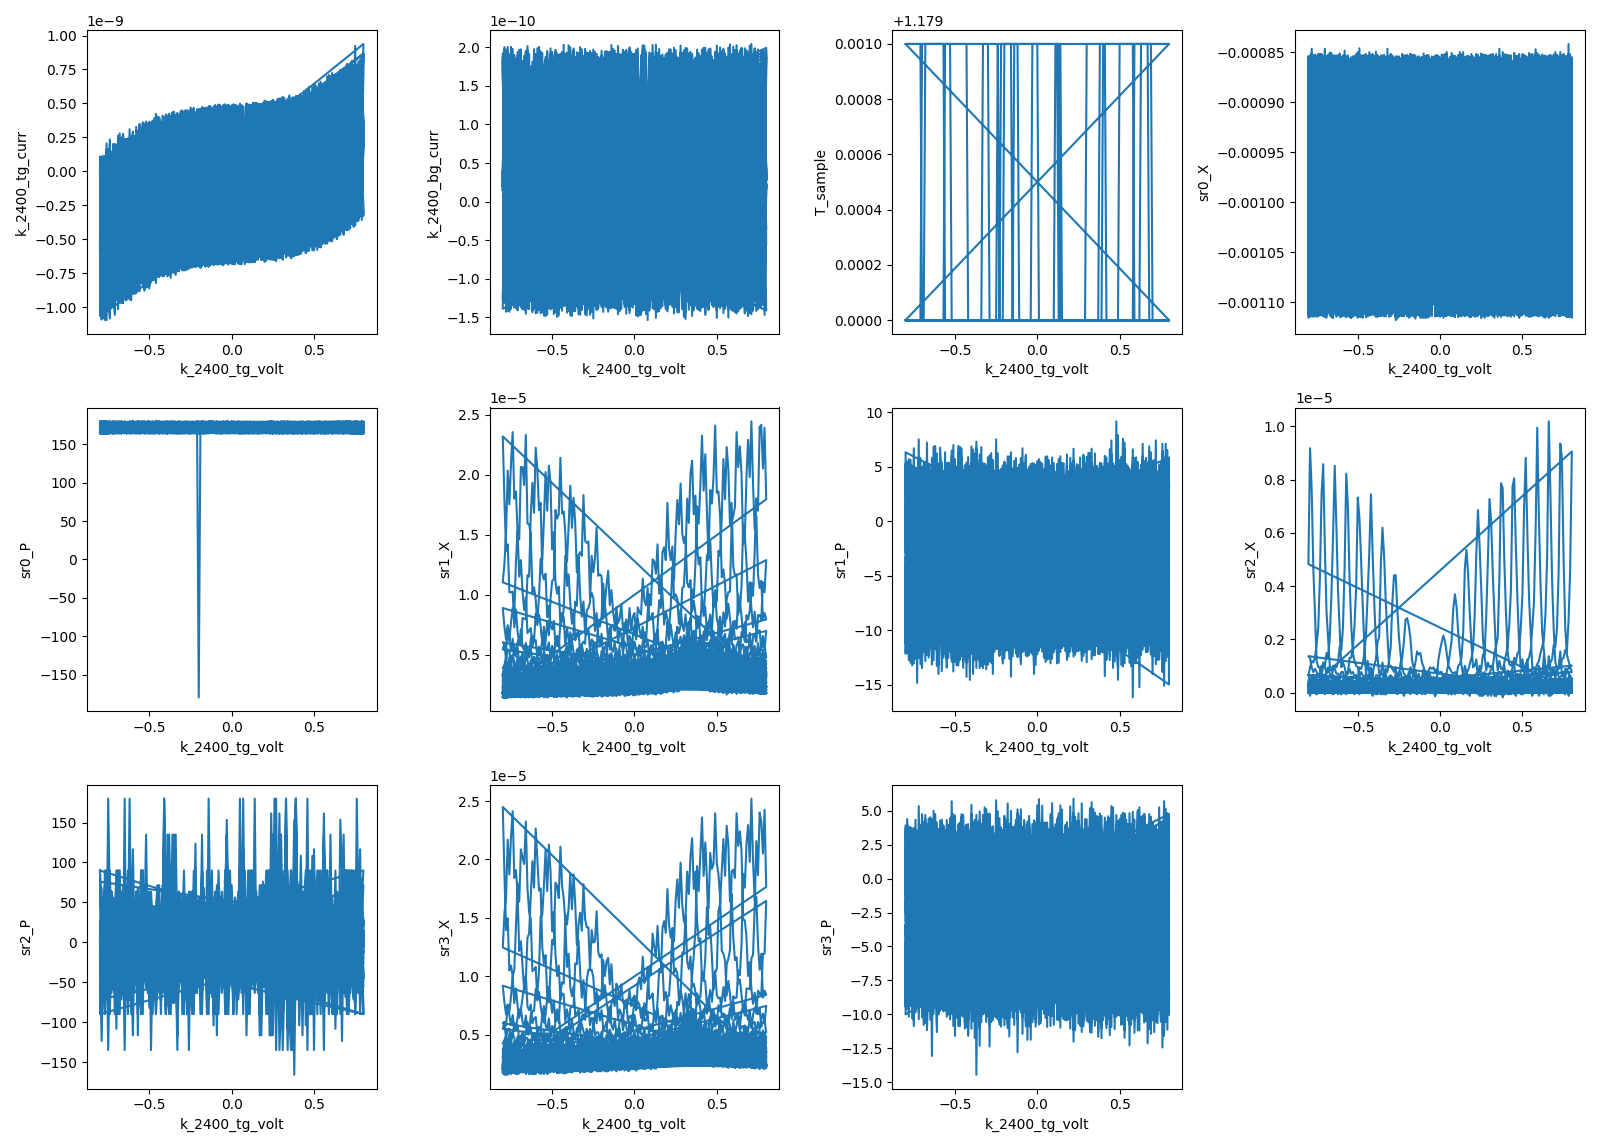

2026-08-19 14:34:40,772 [INFO] Completed in 2h 37m 52s


2026-08-19 14:34:40,772 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260818-vti-01\data\7\data.tsv.gz


2026-08-19 14:34:40,852 [INFO] Ramping k_2400_tg_volt: 0.7992102 -> 0


2026-08-19 14:34:41,951 [INFO] Ramping k_2400_bg_volt: 2.5 -> 0


gatemap done; gates parked at 0


In [24]:
# === First 0 T gatemap: TG fast (±0.8 V, 10 mV) × BG slow (±2.5 V, 0.1 V) ===
# Feeds cnp-and-dline-calibration (CNP-line fit -> c_bg/c_tg) and the
# investigation's step 1 (D=0 line, clean regions, contact-arm check).

# --- preconditions ---
_B, _T = magnet.field(), T_sample()
_amp = sr1.amplitude()
print(f"preconditions: B={_B:+.4f} T (~0), T={_T:.3f} K (base), "
      f"Vtg={k_tg.volt():+.4f}, Vbg={k_bg.volt():+.4f}, Vsi={dc205.voltage():+.2f} (all ~0), "
      f"drive={_amp*1e3:.0f} mV (expect 100)")
assert abs(_B) < 0.02 and _T < 1.5, "B/T precondition failed — stop"
assert abs(dc205.voltage()) < 0.05, "Si not at 0 — stop"
assert abs(_amp - 0.100) < 0.005, "drive not 100 mV — stop"

mc = {**meas_config,
      "sample_temperature:": T_sample(),
      "Si (V)": 0.0,
      "comments": ("gatemap: V_tg -0.8..+0.8 (161 pts, fast) x V_bg -2.5..+2.5 "
                   "(51 rows, slow), Vsi=0, B~0, T=1.18 K, drive 100 mV / 10 MOhm "
                   "nominal (T_SD contact ~109 MOhm dominates: I ~ 1 nA, normalize "
                   "Rxx by sr0 current per point). Sens sr0 10 mV, sr1/2/3 1 mV; "
                   "tau 0.1 s; TG leak (~0.5 nA at endpoints) operator-accepted.")}
s = sweep.AsyncStation(mc)
s.add_comment('gatemap')
s.add_comment('first map, Vsi = 0V; feeds cnp-and-dline-calibration')

s.ramp(k_bg.volt, -2.5)
s.ramp(k_tg.volt, -0.8)
interruptible_sleep(5)

xp = k_tg.volt
s.fp(k_tg.curr).fp(k_bg.curr)
s.fp(T_sample)
s.plot(xp, k_tg.curr)
s.plot(xp, k_bg.curr)
s.plot(xp, T_sample)
for lia in [sr0, sr1, sr2, sr3]:
    s.fp(lia.X).fp(lia.P)
    s.plot(xp, lia.X)
    s.plot(xp, lia.P)

try:
    s.megasweep(k_bg.volt, np.linspace(-2.5, 2.5, 51),
                k_tg.volt, np.linspace(-0.8, 0.8, 161),
                slow_delay=3, fast_delay=1)
finally:
    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)
print("gatemap done; gates parked at 0")


## HERA — calibration commit (run 7 → session (n, D) conversion)

> **14:39** · commit cal: c\_tg 1.7827e-3 (anchor), c\_bg 1.2874e-3 (ratio 0.7222), n\_off -0.059e12; d0\_line designer · **ETA ~14:40** (≈1 min)

cnp-and-dline-calibration write-back: ratio data-calibrated (c_bg/c_tg = 0.7222), scale geometry-anchored (QH lever-arm upgrade pending), n_offset −0.059×10¹² cm⁻². D = 0 designer (, clip-by-dropping) for the spot checks and fan. Contract in the device card and ana cells 17–20.

In [25]:
# === cnp-and-dline-calibration commit (run 7) — session (n, D) conversion ===
# Two-tier provenance: ratio DATA-CALIBRATED (c_bg/c_tg = 0.7222, run 7 CNP fit,
# sr1/sr3 spread 0.4%); absolute scale GEOMETRY PRIOR (c_tg anchored, 14.9 nm hBN)
# pending the quantum-Hall lever-arm upgrade. Full contract: device card +
# ana cells 17-20.
from sharpelab_nb.gates import calc_gate_voltages, calc_nD

c_tg_cal = 1.7827e-3        # F/m^2 — ANCHOR (geometry prior)
c_bg_cal = 1.2874e-3        # F/m^2 — ratio-calibrated (0.7222 x c_tg)
n_off_e12 = -0.0593         # 1e12 cm^-2 (display units for calc_gate_voltages)
cal = GateCalibration(c_tg_cal, c_bg_cal, n_offset=-5.934e14, D_offset=0.0)  # SI

def d0_line(ns_e12, tg_lim=0.8, bg_lim=5.0):
    """Paired (Vtg, Vbg, n) vectors along D=0, clipped by DROPPING (never clamp).
    ns_e12 in 1e12 cm^-2. Realized window: n in [-1.837, +1.720]e12."""
    ns_e12 = np.asarray(ns_e12, float)
    Vt, Vb = calc_gate_voltages(ns_e12, np.zeros_like(ns_e12),
                                c_tg_cal, c_bg_cal, n_offset=n_off_e12)
    Vt, Vb = np.asarray(Vt), np.asarray(Vb)
    keep = (np.abs(Vt) <= tg_lim) & (np.abs(Vb) <= bg_lim)
    return Vt[keep], Vb[keep], ns_e12[keep]

# sanity: roundtrip + window print
_vt, _vb, _nk = d0_line(np.linspace(-2.0, 2.0, 801))
_n, _D = calc_nD(_vt, _vb, c_tg_cal, c_bg_cal, n_offset=n_off_e12)
print(f"D=0 designer live: n {_nk.min():+.3f}..{_nk.max():+.3f} e12, "
      f"max|D| roundtrip {np.abs(np.asarray(_D)).max():.2e} V/nm, "
      f"Vtg {_vt.min():+.3f}..{_vt.max():+.3f}, Vbg {_vb.min():+.3f}..{_vb.max():+.3f}")


D=0 designer live: n -1.835..+1.720 e12, max|D| roundtrip 1.22e-17 V/nm, Vtg -0.798..+0.800, Vbg -1.105..+1.107


## HERA — SdH spot check, hole side (E1 auto, investigation step 3)

> **14:41** · sdh-spot-check hole: n=-1.8e12 D=0, B 0.8->9 T uniform-B dB=11mT (746 pts), delay 1s, sens sr1/sr3 200uV sr2 50uV, B holds at 9 T after · **ETA ~16:31** (≈1h50m)

First of the two spot checks (`sdh-spot-check`; the electron side follows, riding the field back down — never re-traverse). Design from the committed run-7 calibration: n = −1.8×10¹² cm⁻² at D = 0 (near the window edge, max periods), F_L = 18.6 T, Δ(1/B) = 1/(3·F_L) = 1.79×10⁻²/T; the VTI's blocking magnet takes the uniform-B branch: ΔB = Δ(1/B)·B_lo² = 11 mT with B_lo = 0.8 T just below the expected onset (1–2 T at T_e ≈ 8 K — heuristic, measured by this sweep). B_hi = 9 T inside the 10 T cap; δF = 1/(1/B_onset − 1/B_hi) ≈ 1.8 T for a 1.5 T onset — separates an ABA {f_ML, f_BL≈15–18 T} pair; a very slow tone's localization is onset-limited and will be reported as such. Sensitivities re-sized for the B axis with headroom over precision (QH peaks grow with B): sr1/sr3 200 µV (≈218 kΩ soft-clip at the ~1 nA contact-limited bias), sr2 50 µV. Dwell 1 s = 10τ. Rxx analysis normalizes by measured sr0 current per point; `r_full_scale` passed to `sdh_fft` so any soft-clip truncates rather than corrupts.

Wall-clock: 8.2 T measured traverse at ~0.092 T/min effective (rig card) ≈ 89 min + 6 min positioning ≈ **1 h 50 m realistic**. Checkpoints: first rows (onset region is the first thing on the page), mid-sweep FFT preview on the landed record.


preconditions: B=+0.0061 T (~0, map endpoint), T=1.179 K, drive=100 mV (100), Vsi=+0.00 (~0)
target: n=-1.8e12, D=0 -> Vtg=-0.7822, Vbg=-1.0832
sens: sr1/sr3 200 uV, sr2 50 uV, sr0 0.01 V; tau 0.1 s, delay 1 s (10 tau)
2026-08-19 14:42:13,701 [INFO] Ramping k_2400_tg_volt: -0.0009175807 -> -0.7822148613910923


2026-08-19 14:42:14,810 [INFO] Ramping k_2400_bg_volt: 0.0 -> -1.0831555331691007


2026-08-19 14:42:21,204 [INFO] Ramping magnet_field: 0.006087232876712328 -> 0.8


2026-08-19 14:48:14,371 [INFO] Starting sweep with ID 8


2026-08-19 14:48:14,372 [INFO] Minimum duration 0h 12m 26s


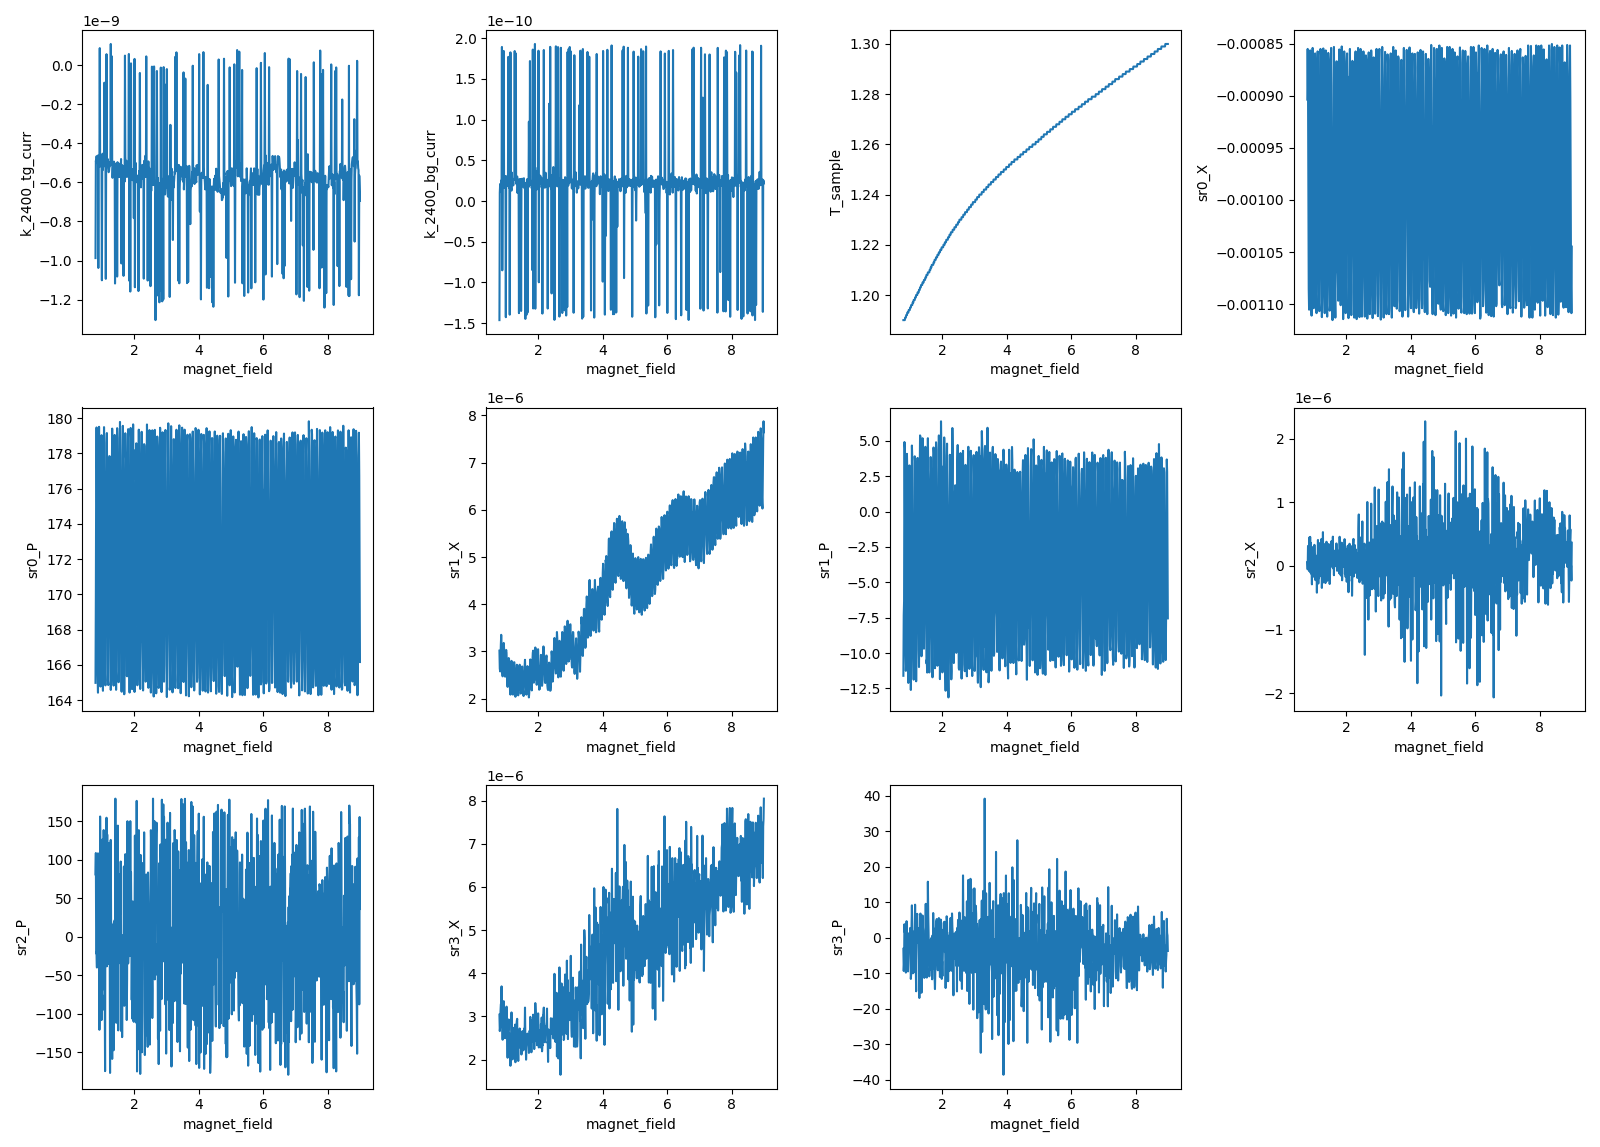

2026-08-19 16:39:14,658 [INFO] Completed in 1h 50m 59s


2026-08-19 16:39:14,659 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260818-vti-01\data\8\data.tsv.gz


hole spot check done; B holds at +9.008 T, gates at hole point


In [26]:
# === SdH spot check, hole side: n = -1.8e12, D = 0, B 0.8 -> 9 T (E1 auto) ===
# Design (investigation step 2/3): F_L = 18.6 T; Nyquist(1/3) d(1/B) = 1.79e-2 /T;
# blocking magnet => uniform-B, dB = d(1/B)*B_lo^2 = 11 mT @ B_lo = 0.8 T.
# Expected onset 1-2 T (T_e ~ 8 K); B_lo sits below it and reads it directly.

# --- preconditions ---
_B, _T, _amp = magnet.field(), T_sample(), sr1.amplitude()
print(f"preconditions: B={_B:+.4f} T (~0, map endpoint), T={_T:.3f} K, "
      f"drive={_amp*1e3:.0f} mV (100), Vsi={dc205.voltage():+.2f} (~0)")
assert abs(_B) < 0.05 and _T < 1.5, "B/T precondition failed — stop"
assert abs(_amp - 0.100) < 0.005 and abs(dc205.voltage()) < 0.05, "drive/Si precondition failed — stop"

# gate point from the committed calibration
n_h, D_h = -1.8, 0.0                      # 1e12 cm^-2, V/nm
Vtg_h, Vbg_h = calc_gate_voltages(n_h, D_h, c_tg_cal, c_bg_cal, n_offset=n_off_e12)
print(f"target: n={n_h}e12, D=0 -> Vtg={Vtg_h:+.4f}, Vbg={Vbg_h:+.4f}")
assert abs(Vtg_h) <= 0.8 and abs(Vbg_h) <= 5.0

# sensitivities for the field axis (headroom over precision — QH peaks grow with B):
# sr1/sr3 200 uV fs (~218 kOhm soft-clip at ~1 nA), sr2 50 uV (weak pair), sr0 10 mV.
sr1.sensitivity(200e-6); sr3.sensitivity(200e-6); sr2.sensitivity(50e-6)
print(f"sens: sr1/sr3 200 uV, sr2 50 uV, sr0 {sr0.sensitivity()} V; tau 0.1 s, delay 1 s (10 tau)")

B_vec = np.linspace(0.8, 9.0, 746)        # dB = 11.0 mT
mc = {**meas_config,
      "sample_temperature:": T_sample(),
      "Si (V)": 0.0,
      "comments": (f"sdh-spot-check hole side: n={n_h}e12 cm^-2, D=0 "
                   f"(Vtg={Vtg_h:+.4f}, Vbg={Vbg_h:+.4f}), B 0.8->9.0 T uniform-B "
                   f"dB=11 mT (Nyquist/3 on F_L=18.6 T at B_lo=0.8), delay 1 s, "
                   f"drive 100 mV; Rxx normalize by sr0 current per point; "
                   f"sens sr1/sr3 200uV sr2 50uV.")}
s = sweep.AsyncStation(mc)
s.add_comment('sdh-spot-check')
s.add_comment(f'hole side: n = {n_h}e12, D = 0, (Vtg, Vbg) = ({Vtg_h:+.4f}, {Vbg_h:+.4f})')

s.ramp(k_tg.volt, Vtg_h)
s.ramp(k_bg.volt, Vbg_h)
interruptible_sleep(5)

xp = magnet.field
s.fp(k_tg.curr).fp(k_bg.curr)
s.fp(T_sample)
s.plot(xp, k_tg.curr)
s.plot(xp, k_bg.curr)
s.plot(xp, T_sample)
for lia in [sr0, sr1, sr2, sr3]:
    s.fp(lia.X).fp(lia.P)
    s.plot(xp, lia.X)
    s.plot(xp, lia.P)

# position (blocking ramp is the settle), then sweep up; magnet HOLDS at 9 T
# for the electron-side spot check to ride back down — no re-traverse.
s.ramp(magnet.field, 0.8)
s.sweep(magnet.field, B_vec, delay=1)
print(f"hole spot check done; B holds at {magnet.field():+.3f} T, gates at hole point")


## HERA — SdH spot check, electron side (E1 auto, investigation step 3)

> **16:41** · sdh-spot-check electron: n=+1.7e12 D=0, B 9->0.8 T dB=11mT (746 pts), delay 1s, inherits run-8 sens; ends at 0.8 T · **ETA ~18:31** (≈1h50m)

Second spot check, riding the field home 9 → 0.8 T from run 8's hold — no re-traverse. n = +1.7×10¹² cm⁻² at D = 0 (electron window edge), F_L = 17.6 T; inherits run 8's 11 mT uniform-B grid (Nyquist/3 needs ≤ 12.1 mT — holds), sensitivities, and dwell. The gate move to the electron point happens at 9 T (crosses the CNP — routine; leakage on the live plots).

This is the Onsager discriminator for run 8's fork: run 8 (hole, sr1) gave onset 1.67 T and a peak set {17.7 ≈ F_L, 7.3, (11.4 weak), 4.4 censored, 25.6 marginal} with 7.3+11.4 ≈ F_L (ABA-partition-shaped) vs 17.7-as-real-pocket (ABC-like) unresolved. Real pockets scale with n between the two sides; harmonics track their fundamentals exactly; grid-locked aliases move with the grid. Full run-8 deep read (B-window split, bg stability) lands in ana while this runs. ~1 h 50 m.


preconditions: B=+9.006 T (expect ~9), T=1.300 K, drive=100 mV, Vtg=-0.7808, Vbg=-1.0830 (hole point), Vsi=+0.00
target: n=+1.7e12, D=0 -> Vtg=+0.7906, Vbg=+1.0947
2026-08-19 16:41:36,766 [INFO] Ramping k_2400_tg_volt: -0.780756 -> 0.7905731060178942


2026-08-19 16:41:38,896 [INFO] Ramping k_2400_bg_volt: -1.083 -> 1.0947294361489046


2026-08-19 16:41:46,690 [INFO] Starting sweep with ID 9


2026-08-19 16:41:46,691 [INFO] Minimum duration 0h 12m 26s


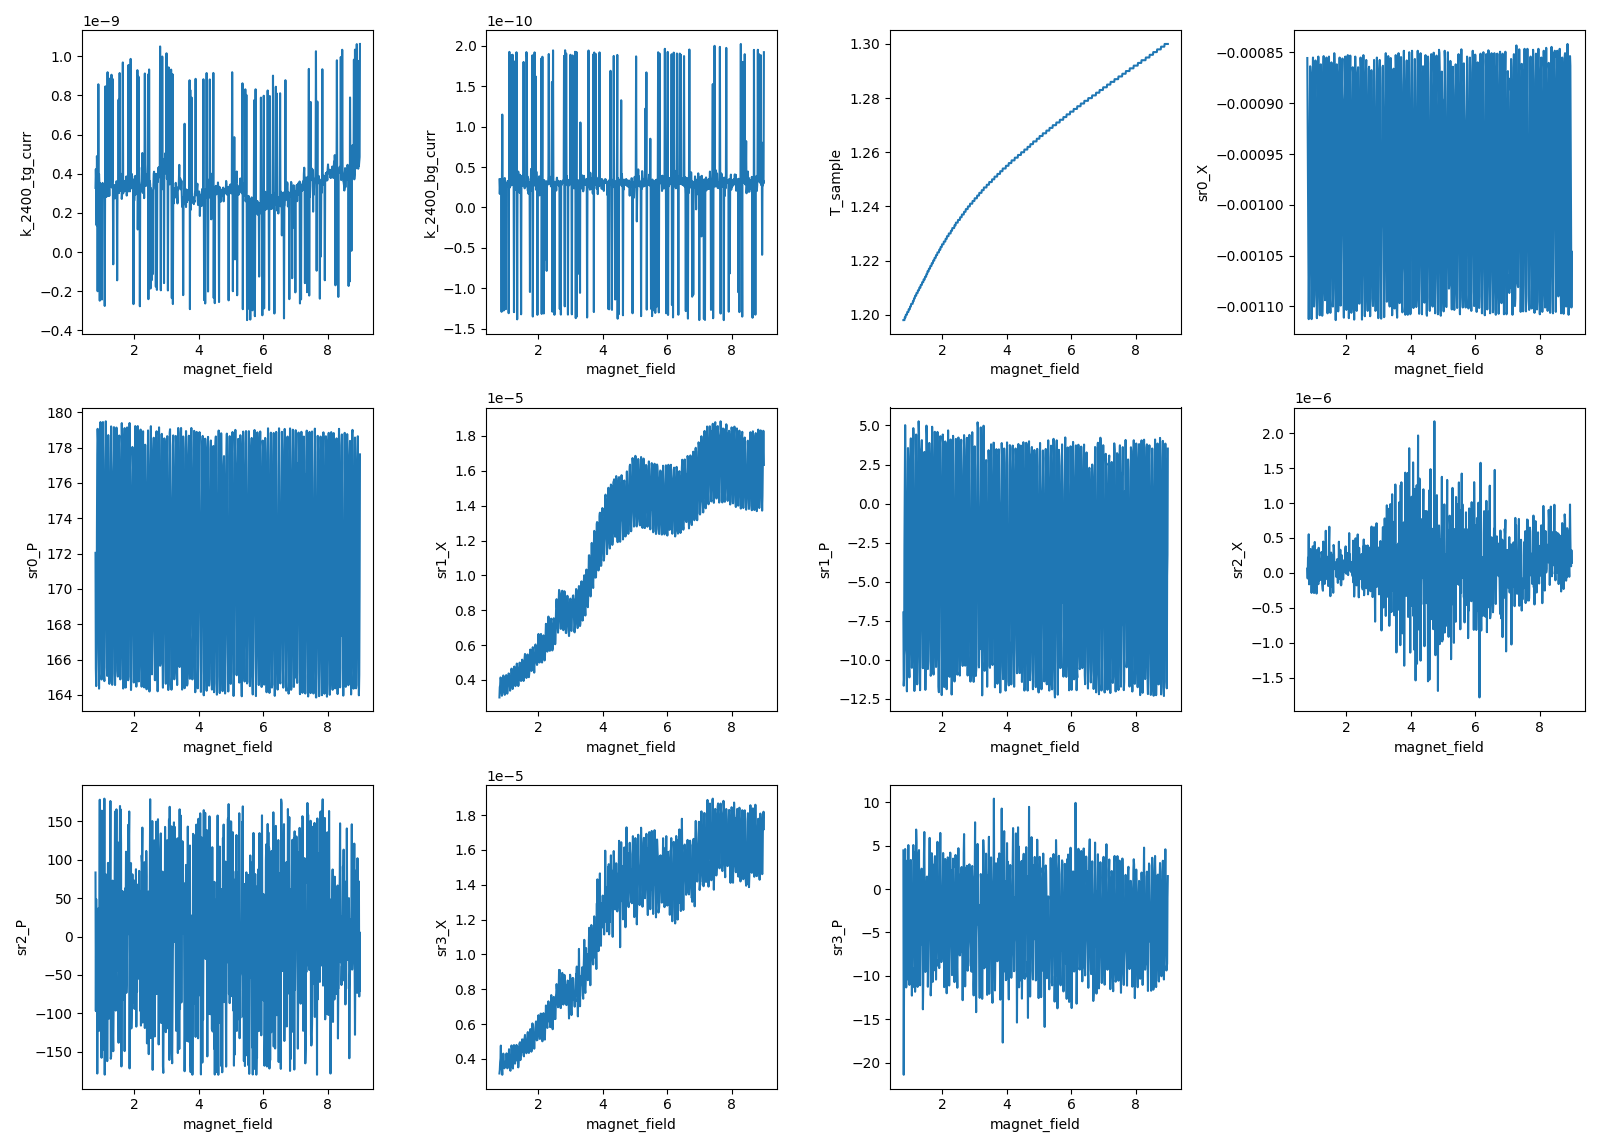

2026-08-19 18:32:48,322 [INFO] Completed in 1h 51m 0s


2026-08-19 18:32:48,323 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260818-vti-01\data\9\data.tsv.gz


electron spot check done; B at +0.804 T (0.8 hold — cheap onset extension or fan start decided from the reads)


In [27]:
# === SdH spot check, electron side: n = +1.7e12, D = 0, B 9 -> 0.8 T (E1 auto) ===
# Rides the magnet home from the hole check's 9 T endpoint — no re-traverse.
# F_L = 17.6 T; inherits the hole grid dB = 11 mT (Nyquist/3 holds: needs <= 12.1 mT).

# --- preconditions (magnet holding at 9 T from run 8; gates at the hole point) ---
_B, _T, _amp = magnet.field(), T_sample(), sr1.amplitude()
print(f"preconditions: B={_B:+.3f} T (expect ~9), T={_T:.3f} K, drive={_amp*1e3:.0f} mV, "
      f"Vtg={k_tg.volt():+.4f}, Vbg={k_bg.volt():+.4f} (hole point), Vsi={dc205.voltage():+.2f}")
assert abs(_B - 9.0) < 0.05, f"B={_B:+.3f}, expected 9 T hold — stop"
assert _T < 1.6 and abs(_amp - 0.100) < 0.005, "T/drive precondition failed — stop"

n_e, D_e = +1.7, 0.0
Vtg_e, Vbg_e = calc_gate_voltages(n_e, D_e, c_tg_cal, c_bg_cal, n_offset=n_off_e12)
print(f"target: n={n_e:+}e12, D=0 -> Vtg={Vtg_e:+.4f}, Vbg={Vbg_e:+.4f}")
assert abs(Vtg_e) <= 0.8 and abs(Vbg_e) <= 5.0

B_vec = np.linspace(9.0, 0.8, 746)        # dB = 11.0 mT, descending
mc = {**meas_config,
      "sample_temperature:": T_sample(),
      "Si (V)": 0.0,
      "comments": (f"sdh-spot-check electron side: n={n_e:+}e12 cm^-2, D=0 "
                   f"(Vtg={Vtg_e:+.4f}, Vbg={Vbg_e:+.4f}), B 9.0->0.8 T uniform-B "
                   f"dB=11 mT (Nyquist/3 on F_L=17.6 T at B_lo=0.8), delay 1 s, "
                   f"drive 100 mV; Rxx normalize by sr0 current per point; "
                   f"sens sr1/sr3 200uV sr2 50uV. Pairs with run 8 (hole side).")}
s = sweep.AsyncStation(mc)
s.add_comment('sdh-spot-check')
s.add_comment(f'electron side: n = {n_e:+}e12, D = 0, (Vtg, Vbg) = ({Vtg_e:+.4f}, {Vbg_e:+.4f})')

# gate move at 9 T crosses the CNP — routine; leakage watched live below
s.ramp(k_tg.volt, Vtg_e)
s.ramp(k_bg.volt, Vbg_e)
interruptible_sleep(5)

xp = magnet.field
s.fp(k_tg.curr).fp(k_bg.curr)
s.fp(T_sample)
s.plot(xp, k_tg.curr)
s.plot(xp, k_bg.curr)
s.plot(xp, T_sample)
for lia in [sr0, sr1, sr2, sr3]:
    s.fp(lia.X).fp(lia.P)
    s.plot(xp, lia.X)
    s.plot(xp, lia.P)

try:
    s.sweep(magnet.field, B_vec, delay=1)
finally:
    print(f"electron spot check done; B at {magnet.field():+.3f} T (0.8 hold — "
          f"cheap onset extension or fan start decided from the reads)")


## HERA — Landau fan, hole side, D = 0 (E1 auto, investigation step 4)

> **18:38** · landau-fan-vti: D=0(true) hole side, n -0.70..-1.84e12 (58) x B 1.6->5.0 T uniform-1/B (71 rows), fast\_delay 1s, drive 100 mV; ends at 5 T · **ETA ~21:08** (≈2h30m)

The fork from runs 8–9 (tones {f_a ≈ 6–8, f_b ≈ 17} T on both density signs; ABA pair strained, harmonic reading broken, ABC leaves f_a unexplained) is decided by F(n): a real pocket follows its own Onsager curve, a harmonic tracks k·f exactly, and the partition sum Σf vs F_L(n) is algebraic. Side: hole (cleaner SdH — run 8 snr 19 vs run 9's 9; lower onset).

**Floored design** (landau-fan + VTI variant, measurement-dominated regime): per-column SdH-FFT fan, uniform-1/B. B_lo = 1.6 T (measured onset 1.67 T, `sdh_onset` run 8); **B_hi = 5.0 T** — capped below the ≥3.7 T-onset 183–350 T LL-splitting content whose Nyquist would cost a ~14 h fan; within 1.6–5 T the fastest content is ~3·f_b ≈ 53 T → Δ(1/B) = 0.006 /T → **N_B = 71** (2.8× Nyquist on 53 T). n = −0.70 → −1.84×10¹² (58 pts, 0.02 steps; below 0.7 the window holds < 2 periods — dropped as uninformative; ray-Nyquist floor at 1.6 T is 0.124 → 6× margin). δF per column ≈ 2.5 T — the fan reads *n-dependence*; runs 8–9 (δF ≈ 2) stay the absolute-content anchors at the shared densities (Verify: acquisition-quality comparison at n = −1.8 vs run 8). fast_delay 1 s = spot-check settling parity. Fixed sensitivity: worst corner (n = −0.7, 5 T, ν ≈ 5.8) ≈ 30–50 kΩ ≪ the 218 kΩ soft-clip at 200 µV — headroom holds. Fan runs at **true D = 0**: D_offset = +0.009 V/nm committed from run 7's symmetric R_CNP minimum (both channels).

**Cost**: N_B·N_n = 4118 pts × 1.2 s ≈ 1.4 h grid + B-ramps (Σ steps = 3.4 T ≈ 25 min floor, ~37 min measured-rate) + turnarounds ≈ **2.4 h realistic**. Ends at 5 T with gates parked — the LK mass ladder window (2.5–5 T) starts where the magnet sits.


In [28]:
# === Landau fan, hole side, D = 0 (E1 auto, landau-fan-vti) ===
# Per-column SdH-FFT fan. Design in the proposal markdown; floored per the recipe.

# D_offset commit (run 7 locator: symmetric R_CNP minimum, both channels)
D_OFF = -0.009   # V/nm, nominal-D coordinate of true D=0; design lines at D_nom = D_OFF
cal = GateCalibration(c_tg_cal, c_bg_cal, n_offset=-5.934e14, D_offset=+0.009e9)  # SI update

# --- preconditions ---
_B, _T, _amp = magnet.field(), T_sample(), sr1.amplitude()
print(f"preconditions: B={_B:+.3f} T (expect 0.8 hold), T={_T:.3f} K, drive={_amp*1e3:.0f} mV, "
      f"Vsi={dc205.voltage():+.2f}, sens sr1={sr1.sensitivity()}, sr3={sr3.sensitivity()}")
assert abs(_B - 0.8) < 0.05, f"B={_B:+.3f}, expected 0.8 T hold — stop"
assert _T < 1.6 and abs(_amp - 0.100) < 0.005, "T/drive precondition failed — stop"
try:
    _ami = qcodes.Instrument.find_instrument("ami_he")
    print(f"He level: {_ami.He_level():.2f} in")
except Exception as e:
    print(f"He read unavailable: {e!r}")

# fast axis: n-line at true D=0 (design at nominal D = D_OFF)
ns = np.linspace(-0.70, -1.84, 58)                      # 1e12 cm^-2, 0.02 steps
Vtgs, Vbgs = calc_gate_voltages(ns, D_OFF * np.ones_like(ns),
                                c_tg_cal, c_bg_cal, n_offset=n_off_e12)
Vtgs, Vbgs = np.asarray(Vtgs), np.asarray(Vbgs)
assert np.all(np.abs(Vtgs) <= 0.8) and np.all(np.abs(Vbgs) <= 5.0), "n-line exits validators"
print(f"n-line: {ns[0]} .. {ns[-1]} e12 ({len(ns)} pts), Vtg {Vtgs[0]:+.3f}..{Vtgs[-1]:+.3f}, "
      f"Vbg {Vbgs[0]:+.3f}..{Vbgs[-1]:+.3f}")

# slow axis: uniform in 1/B, 1.6 -> 5.0 T, d(1/B) = 0.006 /T (Nyquist x2.8 on 3f_b ~ 53 T)
B_vec = field_invB(1.6, 5.0, 71)
print(f"B rows: {len(B_vec)}, steps {np.diff(B_vec).min()*1e3:.1f}..{np.diff(B_vec).max()*1e3:.1f} mT")

mc = {**meas_config,
      "sample_temperature:": T_sample(),
      "Si (V)": 0.0,
      "comments": ("landau-fan-vti: hole side D=0 (D_offset +0.009 V/nm, run-7 locator), "
                   "n -0.70..-1.84e12 (58 pts) fast paired-gate line x B 1.6->5.0 T "
                   "uniform-1/B (71 rows, d(1/B)=0.006/T), fast_delay 1 s (spot-check "
                   "settling parity), drive 100 mV, sens sr1/sr3 200uV sr2 50uV; "
                   "Rxx normalize by sr0 per point. Reads: per-column FFT vs F_L(n), "
                   "partition sum, tone n-dependence. Pairs with runs 8-9.")}
s = sweep.AsyncStation(mc)
s.add_comment('landau-fan-vti')
s.add_comment(f'D = 0 (true; D_offset +0.009), n = -0.70 to -1.84e12, B = 1.6 to 5.0 T uniform-1/B')

xp = magnet.field
s.fp(k_tg.curr).fp(k_bg.curr)
s.fp(T_sample)
s.plot(xp, k_tg.curr)
s.plot(xp, k_bg.curr)
s.plot(xp, T_sample)
for lia in [sr0, sr1, sr2, sr3]:
    s.fp(lia.X).fp(lia.P)
    s.plot(xp, lia.X)
    s.plot(xp, lia.P)

# position gates at the line start, field at B_lo (blocking ramp is the settle)
s.ramp(k_tg.volt, Vtgs[0])
s.ramp(k_bg.volt, Vbgs[0])
s.ramp(magnet.field, 1.6)
interruptible_sleep(5)

try:
    s.multimegasweep([magnet.field], [B_vec],
                     [k_tg.volt, k_bg.volt], [Vtgs, Vbgs],
                     slow_delay=1, fast_delay=1)
finally:
    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)
print(f"fan done; gates parked, B at {magnet.field():+.3f} T (5.0 hold — LK ladder or "
      f"follow-up decided from the per-column read)")


preconditions: B=+0.806 T (expect 0.8 hold), T=1.197 K, drive=100 mV, Vsi=+0.00, sens sr1=0.0002, sr3=0.0002
He level: 15.79 in


AssertionError: n-line exits validators

## HERA — fan cell v2 (override of cell 53)

> **18:39** · landau-fan-vti v2: n -0.70..-1.74e12 (53) x B 1.6->5.0 T (71 rows uniform-1/B); otherwise identical to cell 53 · **ETA ~20:59** (≈2h20m)

Cell 53's design assert stopped it before any hardware move (as intended): the D_offset commit shifts the hole-side V_tg by −45 mV, so the D = 0(true) line exits the TG validator at n = −1.84. Realized edge is n = −1.74×10¹² — this override runs the identical fan with n = −0.70 → −1.74 (53 pts, same 0.02 steps; F_L(n_max) drops to 18.0 T, all Nyquist margins hold). Everything else unchanged.

preconditions: B=+0.806 T (expect 0.8 hold), T=1.197 K, drive=100 mV, Vsi=+0.00, sens sr1=0.0002, sr3=0.0002
He level: 15.79 in
n-line: -0.7 .. -1.74 e12 (53 pts), Vtg -0.333..-0.800, Vbg -0.337..-0.984
B rows: 71, steps 15.7..147.3 mT
2026-08-19 18:39:46,966 [INFO] Ramping k_2400_tg_volt: 0.7896115 -> -0.33261063275767094


2026-08-19 18:39:48,503 [INFO] Ramping k_2400_bg_volt: 1.0945 -> -0.3367792406297187


2026-08-19 18:39:50,327 [INFO] Ramping magnet_field: 0.8060599726027398 -> 1.6


2026-08-19 18:45:47,601 [INFO] Starting multimegasweep with ID 10


2026-08-19 18:45:47,603 [INFO] Minimum duration 1h 3m 54s


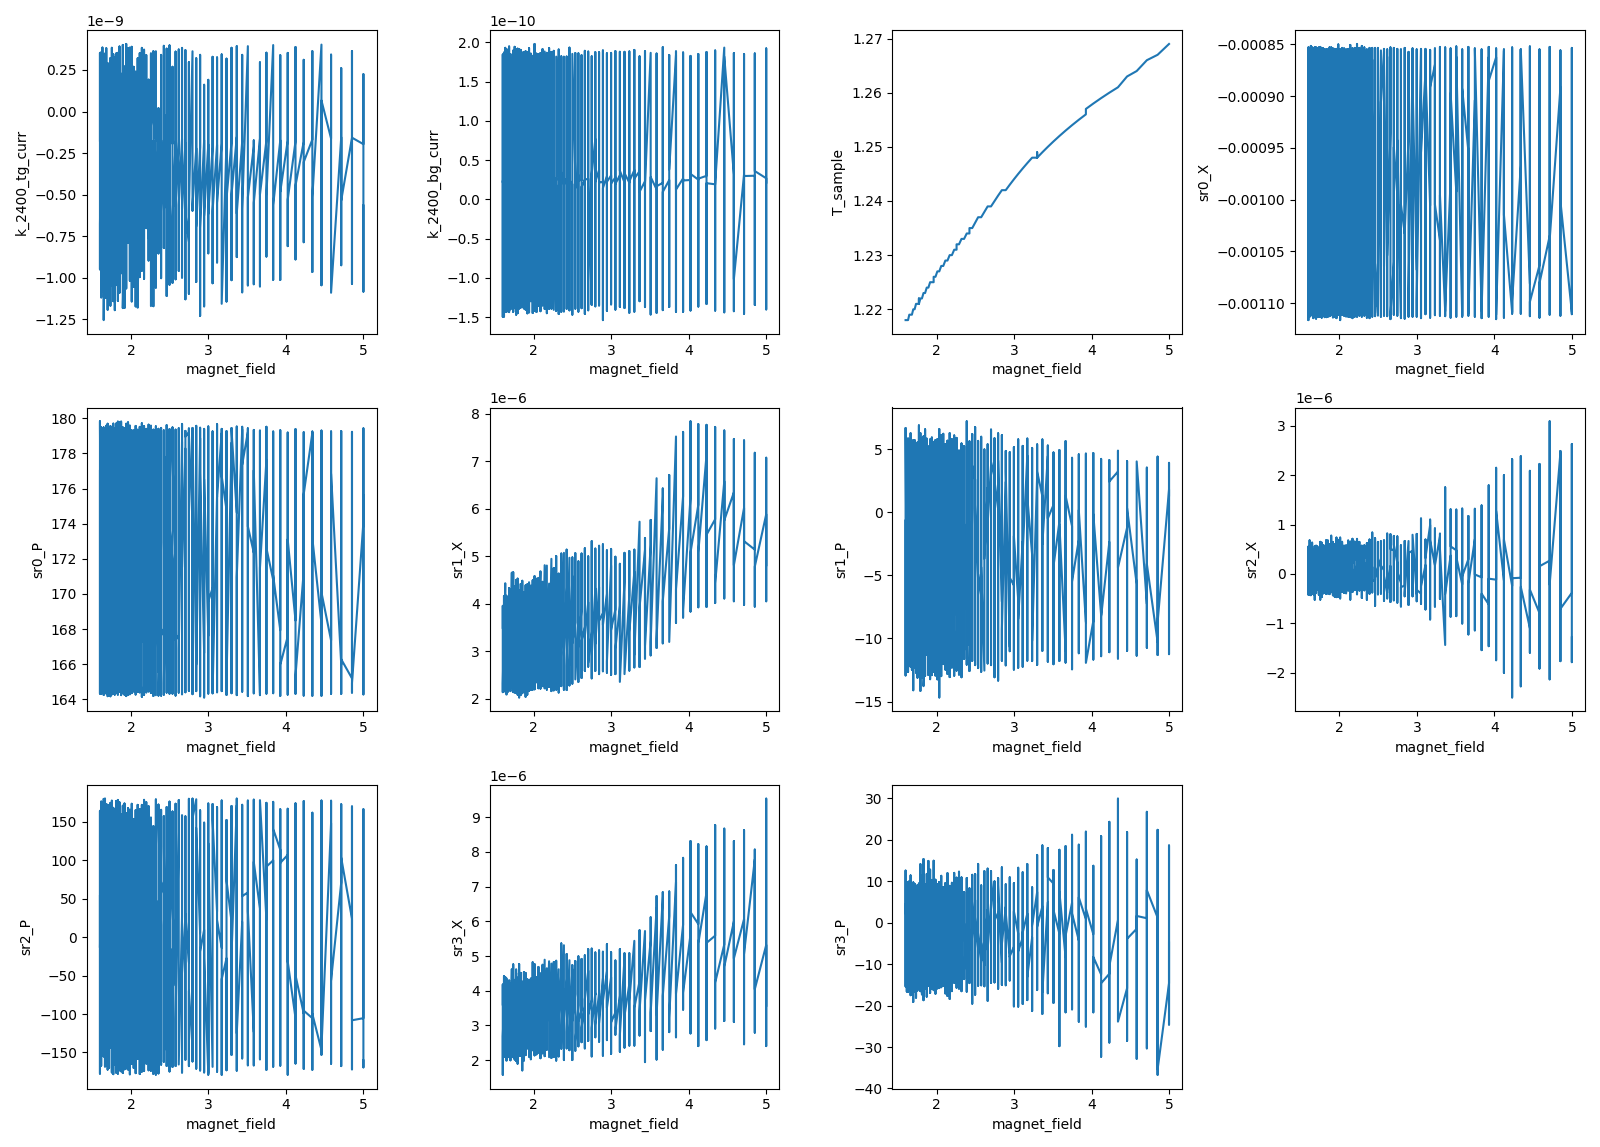

2026-08-19 20:28:24,973 [INFO] Completed in 1h 42m 35s


2026-08-19 20:28:24,975 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260818-vti-01\data\10\data.tsv.gz


2026-08-19 20:28:25,056 [INFO] Ramping k_2400_tg_volt: -0.7985955 -> 0


2026-08-19 20:28:26,160 [INFO] Ramping k_2400_bg_volt: -0.984 -> 0


fan done; gates parked, B at +5.006 T (5.0 hold — LK ladder or follow-up decided from the per-column read)


In [29]:
# === Landau fan, hole side, D = 0 (E1 auto, landau-fan-vti) ===
# Per-column SdH-FFT fan. Design in the proposal markdown; floored per the recipe.

# D_offset commit (run 7 locator: symmetric R_CNP minimum, both channels)
D_OFF = -0.009   # V/nm, nominal-D coordinate of true D=0; design lines at D_nom = D_OFF
cal = GateCalibration(c_tg_cal, c_bg_cal, n_offset=-5.934e14, D_offset=+0.009e9)  # SI update

# --- preconditions ---
_B, _T, _amp = magnet.field(), T_sample(), sr1.amplitude()
print(f"preconditions: B={_B:+.3f} T (expect 0.8 hold), T={_T:.3f} K, drive={_amp*1e3:.0f} mV, "
      f"Vsi={dc205.voltage():+.2f}, sens sr1={sr1.sensitivity()}, sr3={sr3.sensitivity()}")
assert abs(_B - 0.8) < 0.05, f"B={_B:+.3f}, expected 0.8 T hold — stop"
assert _T < 1.6 and abs(_amp - 0.100) < 0.005, "T/drive precondition failed — stop"
try:
    _ami = qcodes.Instrument.find_instrument("ami_he")
    print(f"He level: {_ami.He_level():.2f} in")
except Exception as e:
    print(f"He read unavailable: {e!r}")

# fast axis: n-line at true D=0 (design at nominal D = D_OFF)
ns = np.linspace(-0.70, -1.74, 53)                      # 1e12 cm^-2, 0.02 steps; edge -1.74: D_offset shifts Vtg by -45 mV
Vtgs, Vbgs = calc_gate_voltages(ns, D_OFF * np.ones_like(ns),
                                c_tg_cal, c_bg_cal, n_offset=n_off_e12)
Vtgs, Vbgs = np.asarray(Vtgs), np.asarray(Vbgs)
assert np.all(np.abs(Vtgs) <= 0.8) and np.all(np.abs(Vbgs) <= 5.0), "n-line exits validators"
print(f"n-line: {ns[0]} .. {ns[-1]} e12 ({len(ns)} pts), Vtg {Vtgs[0]:+.3f}..{Vtgs[-1]:+.3f}, "
      f"Vbg {Vbgs[0]:+.3f}..{Vbgs[-1]:+.3f}")

# slow axis: uniform in 1/B, 1.6 -> 5.0 T, d(1/B) = 0.006 /T (Nyquist x2.8 on 3f_b ~ 53 T)
B_vec = field_invB(1.6, 5.0, 71)
print(f"B rows: {len(B_vec)}, steps {np.diff(B_vec).min()*1e3:.1f}..{np.diff(B_vec).max()*1e3:.1f} mT")

mc = {**meas_config,
      "sample_temperature:": T_sample(),
      "Si (V)": 0.0,
      "comments": ("landau-fan-vti: hole side D=0 (D_offset +0.009 V/nm, run-7 locator), "
                   "n -0.70..-1.74e12 (53 pts) fast paired-gate line x B 1.6->5.0 T "
                   "uniform-1/B (71 rows, d(1/B)=0.006/T), fast_delay 1 s (spot-check "
                   "settling parity), drive 100 mV, sens sr1/sr3 200uV sr2 50uV; "
                   "Rxx normalize by sr0 per point. Reads: per-column FFT vs F_L(n), "
                   "partition sum, tone n-dependence. Pairs with runs 8-9.")}
s = sweep.AsyncStation(mc)
s.add_comment('landau-fan-vti')
s.add_comment(f'D = 0 (true; D_offset +0.009), n = -0.70 to -1.74e12, B = 1.6 to 5.0 T uniform-1/B')

xp = magnet.field
s.fp(k_tg.curr).fp(k_bg.curr)
s.fp(T_sample)
s.plot(xp, k_tg.curr)
s.plot(xp, k_bg.curr)
s.plot(xp, T_sample)
for lia in [sr0, sr1, sr2, sr3]:
    s.fp(lia.X).fp(lia.P)
    s.plot(xp, lia.X)
    s.plot(xp, lia.P)

# position gates at the line start, field at B_lo (blocking ramp is the settle)
s.ramp(k_tg.volt, Vtgs[0])
s.ramp(k_bg.volt, Vbgs[0])
s.ramp(magnet.field, 1.6)
interruptible_sleep(5)

try:
    s.multimegasweep([magnet.field], [B_vec],
                     [k_tg.volt, k_bg.volt], [Vtgs, Vbgs],
                     slow_delay=1, fast_delay=1)
finally:
    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)
print(f"fan done; gates parked, B at {magnet.field():+.3f} T (5.0 hold — LK ladder or "
      f"follow-up decided from the per-column read)")


## HERA — ML-pocket hunt: low-B spot check (E1 auto)

> **20:40** · sdh-spot-check ML hunt: n=-1.74 true-D0, B 2.5->0.5 T @ 5 mT (401 pts), delay 1s; target 2.4 T ML tone; then LK ladder · **ETA ~21:35** (≈55 min)

Fan verdict (ana cells 28–30): one real branch at (0.87–0.90)·F_L; the low tone is a locked F/2 modulation, not a pocket. Remaining degeneracy: ABA f_BL vs ABC singleton — decided by the ML pocket the fan could not resolve (~2.4 T, ≤1 period in its window). This check: n = −1.74 at true D = 0, B 2.5 → 0.5 T at 5 mT (Nyquist/3 on branch A at the low edge), 3.8 periods of a 2.4 T tone, δF ≈ 0.6 T; a 0.01 mₑ ML pocket is undamped at T_e ≈ 8 K down there, so a null is a real null. Rides the magnet down from the fan's 5 T hold. ~50 min (18 min bare 5→2.5 ramp + ~30 min measured 2.5→0.5). The LK mass ladder (temperature-dependence-vti Flavor B, rungs base→15 K, X-designed, extendable hot) follows regardless of outcome — mass is the independent decider.

preconditions: B=+5.006 T (expect ~5 hold), T=1.269 K, drive=100 mV, Vsi=+0.00, Vtg=+0.0015, Vbg=+0.0000
target: n=-1.74e12 at true D=0 -> Vtg=-0.8000, Vbg=-0.9839
2026-08-19 20:40:52,639 [INFO] Ramping k_2400_tg_volt: 0.001541075 -> -0.799953343073484


2026-08-19 20:40:53,766 [INFO] Ramping k_2400_bg_volt: 0.0 -> -0.9839222029413547


2026-08-19 20:40:55,029 [INFO] Ramping magnet_field: 5.0060753013698625 -> 2.5


2026-08-19 20:59:14,446 [INFO] Starting sweep with ID 11


2026-08-19 20:59:14,448 [INFO] Minimum duration 0h 6m 41s


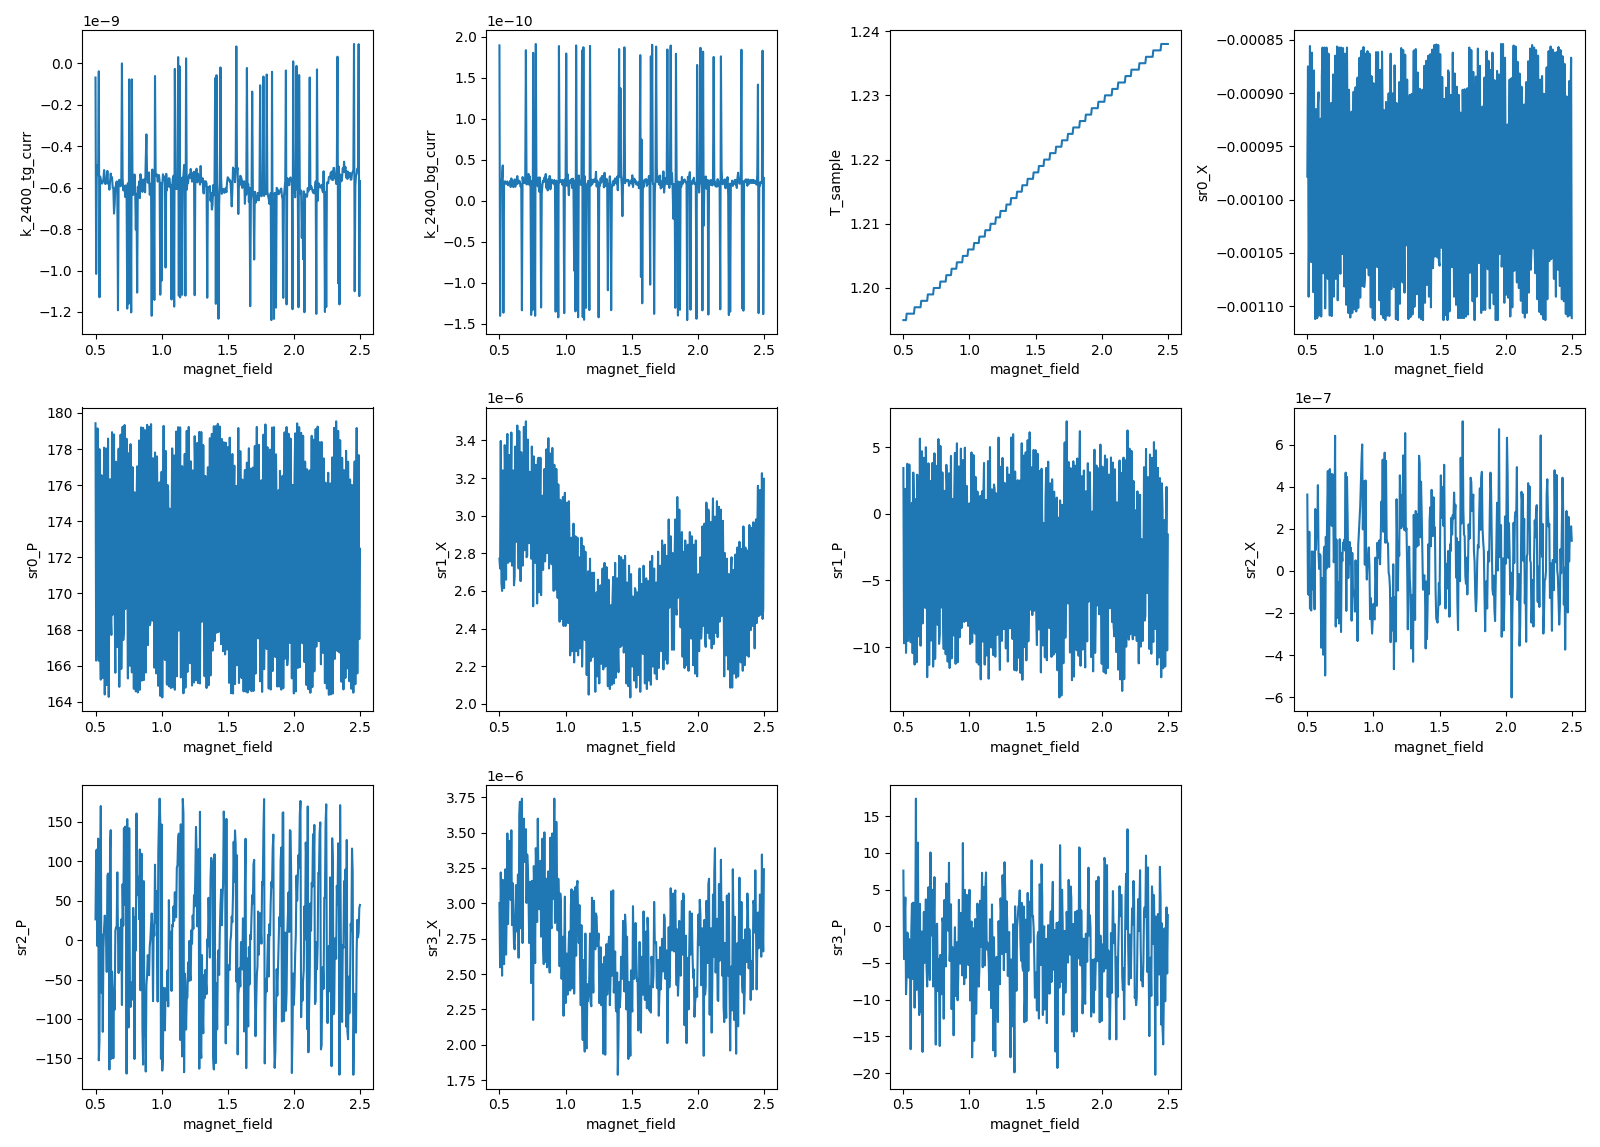

2026-08-19 21:41:25,121 [INFO] Completed in 0h 42m 9s


2026-08-19 21:41:25,122 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260818-vti-01\data\11\data.tsv.gz


ML hunt done; B at +0.505 T, gates at n=-1.74 — LK ladder repositions to its own window next


In [30]:
# === ML-pocket hunt: low-B spot check, n = -1.74, D = 0(true), B 2.5 -> 0.5 T ===
# The ABA-vs-ABC residual: ABA predicts a light ML pocket (model F ~ 2.3 T at
# this n, m* ~ 0.01 me — thermal damping negligible at T_e ~ 8 K even sub-tesla).
# Window 0.5-2.5 T holds ~3.8 periods of a 2.4 T tone; dF ~ 0.6 T. Absence here
# is informative (searched, resolvable, not found), unlike runs 8/10.

# --- preconditions ---
_B, _T, _amp = magnet.field(), T_sample(), sr1.amplitude()
print(f"preconditions: B={_B:+.3f} T (expect ~5 hold), T={_T:.3f} K, drive={_amp*1e3:.0f} mV, "
      f"Vsi={dc205.voltage():+.2f}, Vtg={k_tg.volt():+.4f}, Vbg={k_bg.volt():+.4f}")
assert abs(_B - 5.0) < 0.05, f"B={_B:+.3f}, expected 5 T hold — stop"
assert _T < 1.6 and abs(_amp - 0.100) < 0.005, "T/drive precondition failed — stop"

n_t, D_t = -1.74, -0.009   # nominal-D design coordinate of true D=0
Vtg_t, Vbg_t = calc_gate_voltages(n_t, D_t, c_tg_cal, c_bg_cal, n_offset=n_off_e12)
print(f"target: n={n_t}e12 at true D=0 -> Vtg={Vtg_t:+.4f}, Vbg={Vbg_t:+.4f}")
assert abs(Vtg_t) <= 0.8 and abs(Vbg_t) <= 5.0

B_vec = np.linspace(2.5, 0.5, 401)   # dB = 5 mT: Nyquist/3 on branch A (16 T) at B_lo 0.5
mc = {**meas_config,
      "sample_temperature:": T_sample(),
      "Si (V)": 0.0,
      "comments": (f"sdh-spot-check ML hunt: n={n_t}e12, true D=0 "
                   f"(Vtg={Vtg_t:+.4f}, Vbg={Vbg_t:+.4f}), B 2.5->0.5 T dB=5 mT, "
                   f"delay 1 s, drive 100 mV. Target: ABA ML pocket ~2.4 T "
                   f"(3.8 periods in window, dF~0.6 T); extends runs 8/10 record "
                   f"at this density down to 0.5 T.")}
s = sweep.AsyncStation(mc)
s.add_comment('sdh-spot-check')
s.add_comment(f'ML hunt, low-B: n = {n_t}e12, D = 0 true, B 2.5 -> 0.5 T')

s.ramp(k_tg.volt, Vtg_t)
s.ramp(k_bg.volt, Vbg_t)
s.ramp(magnet.field, 2.5)     # bare blocking ramp 5 -> 2.5 (~18 min)
interruptible_sleep(5)

xp = magnet.field
s.fp(k_tg.curr).fp(k_bg.curr)
s.fp(T_sample)
s.plot(xp, k_tg.curr)
s.plot(xp, k_bg.curr)
s.plot(xp, T_sample)
for lia in [sr0, sr1, sr2, sr3]:
    s.fp(lia.X).fp(lia.P)
    s.plot(xp, lia.X)
    s.plot(xp, lia.P)

try:
    s.sweep(magnet.field, B_vec, delay=1)
finally:
    print(f"ML hunt done; B at {magnet.field():+.3f} T, gates at n={n_t} — "
          f"LK ladder repositions to its own window next")


## HERA — LK mass ladder on branch A (E1 auto, temperature-dependence-vti Flavor B)

> **21:45** · LK ladder: n=-1.74 trueD0, rungs 1.2/2.5/4/6/8/11/15 K (hover-accept, ratio 0.95), per rung B 2<->5 T 151pts@20mT alt-direction; one file/rung · **ETA ~01:45 (+1d)** (≈4h)

The deciding measurement per the investigation's Verify: per-branch LK mass. State of the fork after runs 8–11: one reproducible Onsager branch A = (0.87–0.90)·F_L on both density signs; A/2 is a locked modulation component, not a pocket; the low-B ML hunt (run 11) found **no reproducible ML-band tone** (the candidate {6.2, 11.2} pair failed grid-change reproduction against run 8's independent record — artifact of short weak-signal low-B records; caveat: tones below ~1.5 T remain unresolvable, and an anomalously broadened ML would evade). Model masses on A: **ABA f_BL 0.060 mₑ vs ABC 0.108 mₑ** — factor 1.8, decisive; the A/2 component's damping mass rides along free (a Zeeman-type modulation damps with A's mass, an independent band shows its own).

Design: n = −1.74 at true D = 0 (in place); rungs **[1.2, 2.5, 4, 6, 8, 11, 15] K** ascending (VTI descents are passive-cooling-limited) — X = 5.14·m*·T at B_eff = 2.9 T spans 0.4→4.6 (m*=0.060) and 0.7→8.3 (0.108); if the 15 K rung still shows >50% amplitude the mass is lighter than ~0.03 and I extend hot while hot. Per rung: `set_both(T, ratio=0.95)`, hover acceptance (spread <0.1 K/90 s in [T−0.5, T+3]), logfile-freshness ≥2–3 periods per poll, direction-aware runaway guard on T_vap (fault only above both rung-start and target +2 K), then a 2↔5 T field sweep (151 pts @ 20 mT, direction alternated from the live field — never re-traverse), one file per rung, T_sample + T_vaporizer fp'd. Heaters off at the end (passive recool; close-out handles the rest). Elevated T ≤ 15 K ≪ the 100 K cap and below any field-interaction band.

Cost: 7 × (settle ~4 min + sweep ~26 min) ≈ **3.6 h, call 4 h**. Fit is ana-side (no automated LK fit in the corpus — the fit gets flagged for expert review per recipe).


preconditions: B=+0.506 T (expect ~0.5), T=1.195 K (base), Vtg=-0.7986, Vbg=-0.9840 (n=-1.74 point), drive=100 mV, heater ranges=0,0
He level: 15.79 in
T_sample: VTI_sample.txt live — age 2s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 2s, period 5s
rung 1.2 K accepted at T=1.195 K (ranges 0,0)
2026-08-19 21:45:47,342 [INFO] Ramping magnet_field: 0.5060761232876712 -> 2.0


2026-08-19 21:56:45,277 [INFO] Starting sweep with ID 12


2026-08-19 21:56:45,278 [INFO] Minimum duration 0h 2m 31s


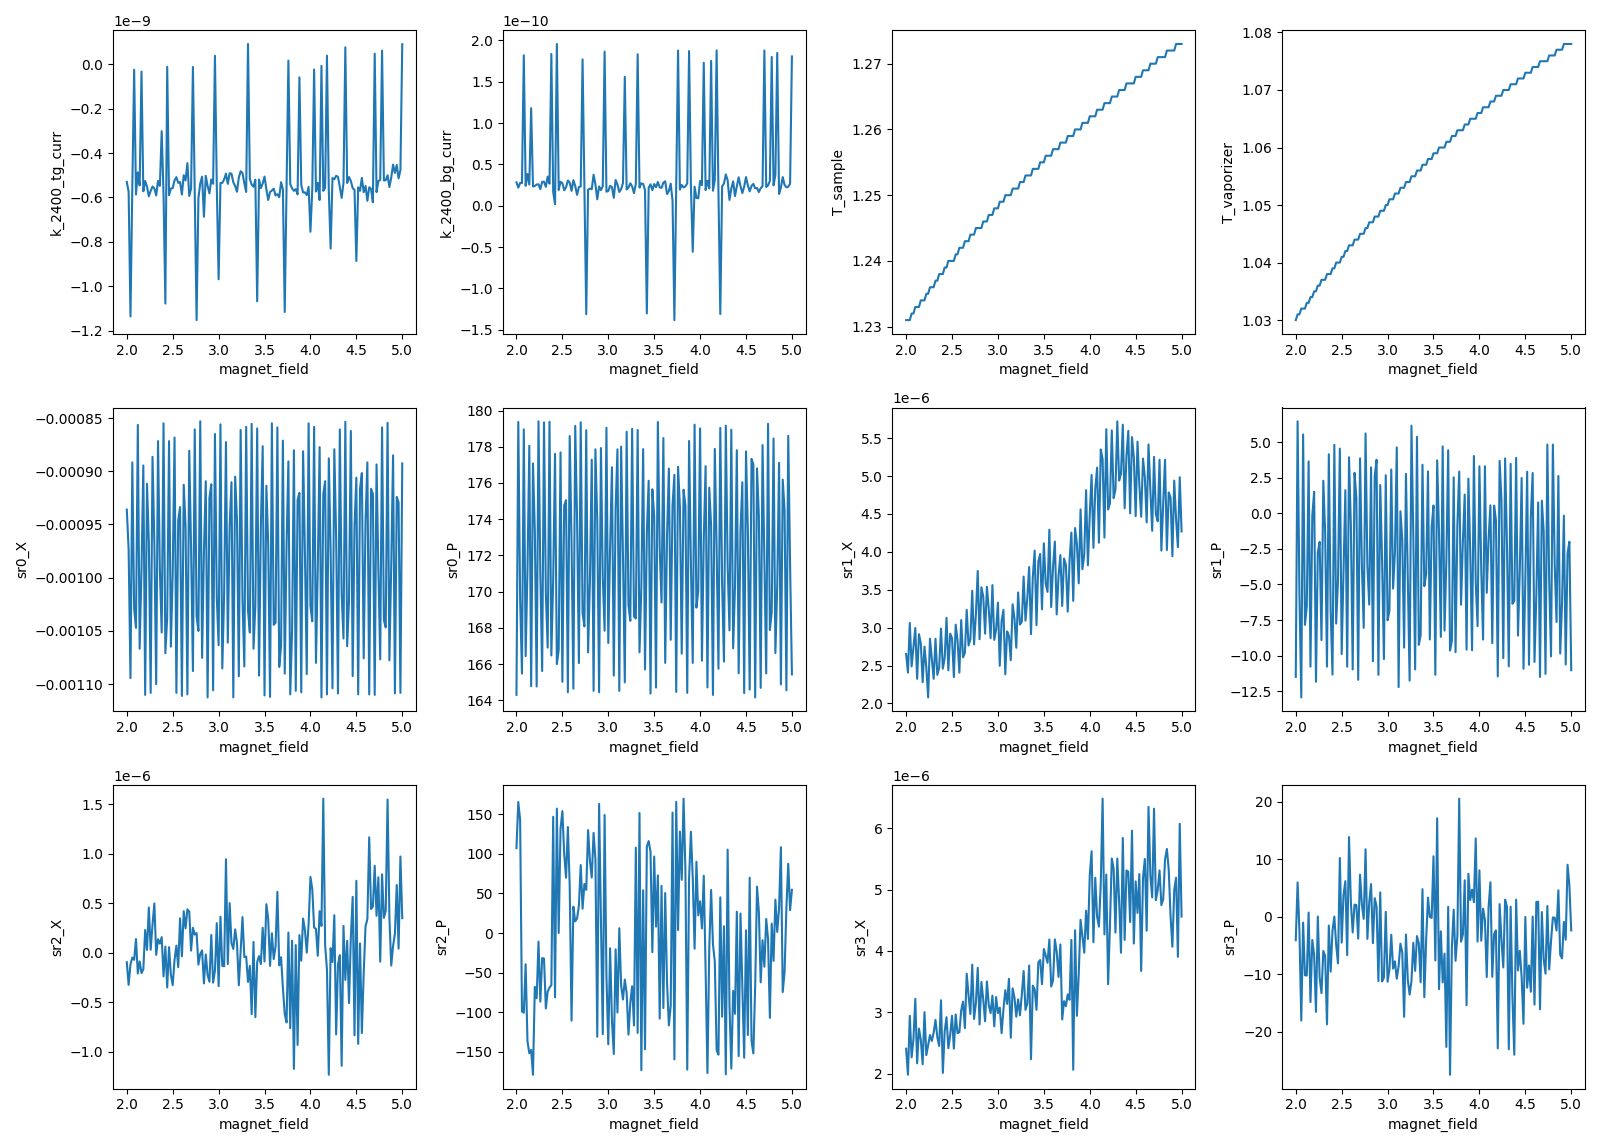

2026-08-19 22:29:00,142 [INFO] Completed in 0h 32m 13s


2026-08-19 22:29:00,142 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260818-vti-01\data\12\data.tsv.gz


rung 1.2 K sweep done; B at +5.01 T
T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s
T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s


T_sample: VTI_sample.txt live — age 4s, period 6s
T_vaporizer: VTI_vaporizer.txt live — age 4s, period 6s


T_sample: VTI_sample.txt live — age 4s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 4s, period 5s


...

T_sample: VTI_sample.txt live — age 2s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 2s, period 5s


T_sample: VTI_sample.txt live — age 2s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 2s, period 5s


T_sample: VTI_sample.txt live — age 2s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 2s, period 5s


T_sample: VTI_sample.txt live — age 2s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 2s, period 5s


RuntimeError: rung 2.5 K settle timeout (2400s), T=1.943

In [31]:
# === LK mass ladder (temperature-dependence-vti, Flavor B) — branch A mass ===
# n = -1.74e12 at true D=0; per rung: field sweep 2<->5 T (alternating, from the
# live field), 151 pts @ 20 mT, delay 1 s. Rungs [1.2(base), 2.5, 4, 6, 8, 11, 15] K.
# Guards: hover acceptance, freshness (>=2-3 write periods), direction-aware
# runaway on T_vap, set_both(T, ratio=0.95) only. One file per rung.

import time as _time

# --- preconditions ---
_B, _T = magnet.field(), T_sample()
print(f"preconditions: B={_B:+.3f} T (expect ~0.5), T={_T:.3f} K (base), "
      f"Vtg={k_tg.volt():+.4f}, Vbg={k_bg.volt():+.4f} (n=-1.74 point), "
      f"drive={sr1.amplitude()*1e3:.0f} mV, heater ranges={heater.sample_range()},{heater.vaporizer_range()}")
assert _T < 1.6, "not at base — stop"
assert heater.sample_range() == 0 and heater.vaporizer_range() == 0, "heaters not off at start — stop"
try:
    _ami = qcodes.Instrument.find_instrument("ami_he")
    print(f"He level: {_ami.He_level():.2f} in")
except Exception as e:
    print(f"He read unavailable: {e!r}")

n_t = -1.74
Vtg_t, Vbg_t = calc_gate_voltages(n_t, -0.009, c_tg_cal, c_bg_cal, n_offset=n_off_e12)
k_tg.volt(Vtg_t); k_bg.volt(Vbg_t)   # re-assert the point (already there)

RUNGS = [1.2, 2.5, 4.0, 6.0, 8.0, 11.0, 15.0]   # K; base first, ascend (VTI descents are slow)
N_PTS, DWELL = 151, 1

def _fresh():
    assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"], max_age=15, max_period=12)
    assert_thermometry_live("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"], max_age=15, max_period=12)

def wait_rung(target, t_max=2400):
    """Hover acceptance: stable (spread < 0.1 K over 90 s) within [target-0.5, target+3]."""
    t0 = _time.time(); _fresh()
    Tv0 = T_vaporizer()
    hist = []
    while True:
        _fresh()
        T, Tv = T_sample(), T_vaporizer()
        now = _time.time()
        hist.append((now, T)); hist = [(t, x) for t, x in hist if now - t <= 90]
        if Tv > max(Tv0, target) + 2.0:                    # true runaway only
            heater.off('both')
            raise RuntimeError(f"runaway: T_vap={Tv:.2f} K > start {Tv0:.2f} & target {target} + 2")
        w = [x for _, x in hist]
        if len(w) >= 8 and (max(w) - min(w)) < 0.1 and (target - 0.5) <= T <= (target + 3):
            return T
        if now - t0 > t_max:
            heater.off('both')
            raise RuntimeError(f"rung {target} K settle timeout ({t_max}s), T={T:.3f}")
        interruptible_sleep(10)

for rung in RUNGS:
    if rung > 1.5:
        heater.set_both(rung, ratio=0.95)     # sanctioned call, ratio fixed (consent-gated otherwise)
        T_acc = wait_rung(rung)
    else:
        _fresh(); T_acc = T_sample()          # base rung: no heating
    print(f"rung {rung} K accepted at T={T_acc:.3f} K (ranges {heater.sample_range()},{heater.vaporizer_range()})")

    B_now = magnet.field()                    # alternate direction from the LIVE field
    B_vec = (np.linspace(2.0, 5.0, N_PTS) if abs(B_now - 2.0) < abs(B_now - 5.0)
             else np.linspace(5.0, 2.0, N_PTS))
    mc = {**meas_config,
          "sample_temperature:": T_sample(),
          "Si (V)": 0.0,
          "comments": (f"temperature-dependence-vti Flavor B (LK mass, branch A): rung "
                       f"{rung} K (accepted {T_acc:.3f} K), n={n_t}e12 true D=0 "
                       f"(Vtg={Vtg_t:+.4f}, Vbg={Vbg_t:+.4f}), B {B_vec[0]:.1f}->{B_vec[-1]:.1f} T "
                       f"151 pts @ 20 mT, delay 1 s, drive 100 mV, sens sr1/sr3 200uV.")}
    s = sweep.AsyncStation(mc)
    s.add_comment('temperature-dependence-vti')
    s.add_comment(f'LK rung {rung} K: n = {n_t}e12, D = 0 true, B {B_vec[0]:.1f} -> {B_vec[-1]:.1f} T')
    xp = magnet.field
    s.fp(k_tg.curr).fp(k_bg.curr)
    s.fp(T_sample); s.fp(T_vaporizer)
    s.plot(xp, k_tg.curr); s.plot(xp, k_bg.curr)
    s.plot(xp, T_sample); s.plot(xp, T_vaporizer)
    for lia in [sr0, sr1, sr2, sr3]:
        s.fp(lia.X).fp(lia.P)
        s.plot(xp, lia.X); s.plot(xp, lia.P)
    s.ramp(magnet.field, B_vec[0])
    s.sweep(magnet.field, B_vec, delay=DWELL)
    print(f"rung {rung} K sweep done; B at {magnet.field():+.2f} T")

heater.off('both')
print(f"ladder complete; heaters off, cooling passively toward base. "
      f"B at {magnet.field():+.2f} T, gates at n={n_t}. T={T_sample():.2f} K")


## HERA — LK ladder v2 (rungs 2.5–15 K; override of cell 59)

> **23:10** · LK ladder v2: rungs 2.5-15 K, equilibrium-anchored hover acceptance; continues from run 12; ~3.2 h · **ETA ~02:25 (+1d)** (≈3h15m)

v1 completed the base rung (run 12) then faulted safe on rung 2.5 K: the loop equilibrated stably at 1.943 K — 0.06 K below the acceptance band's absolute lower edge — and the guard timed out and shut the heaters off (correct fail-safe, wrong acceptance rule). Per the base recipe (settle gates are stability criteria, never absolute targets; the fp'd T is the fit axis, rungs are labels), v2 accepts a stable equilibrium: spread < 0.1 K over 90 s, monotonic vs the previous rung (+0.3 K), ≥4 min on the rung, ±5 K sanity fence; off-nominal acceptance prints a note instead of faulting. Remaining rungs 2.5/4/6/8/11/15 K, base rung not repeated. B alternates from the live field (currently 5 T after run 12, so rung 2.5 sweeps 5→2).

preconditions: B=+5.006 T (expect ~5, run-12 end), T=1.774 K, Vtg=-0.7986, Vbg=-0.9840 (n=-1.74 point), drive=100 mV, heater ranges=0,0
He level: 15.82 in
T_sample: VTI_sample.txt live — age 4s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 4s, period 5s
T_sample: VTI_sample.txt live — age 4s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 4s, period 5s


T_sample: VTI_sample.txt live — age 4s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 4s, period 5s


T_sample: VTI_sample.txt live — age 4s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 4s, period 5s


T_sample: VTI_sample.txt live — age 4s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 4s, period 5s


T_sample: VTI_sample.txt live — age 3s, period 6s
T_vaporizer: VTI_vaporizer.txt live — age 3s, period 6s


...

T_sample: VTI_sample.txt live — age 2s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 2s, period 5s


T_sample: VTI_sample.txt live — age 2s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 2s, period 5s


T_sample: VTI_sample.txt live — age 1s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 1s, period 5s
rung 2.5 K accepted at T=1.914 K (ranges 1,1)
2026-08-19 23:14:54,400 [INFO] Ramping magnet_field: 5.006064849315068 -> 5.0


2026-08-19 23:14:57,512 [INFO] Starting sweep with ID 13


2026-08-19 23:14:57,512 [INFO] Minimum duration 0h 2m 31s


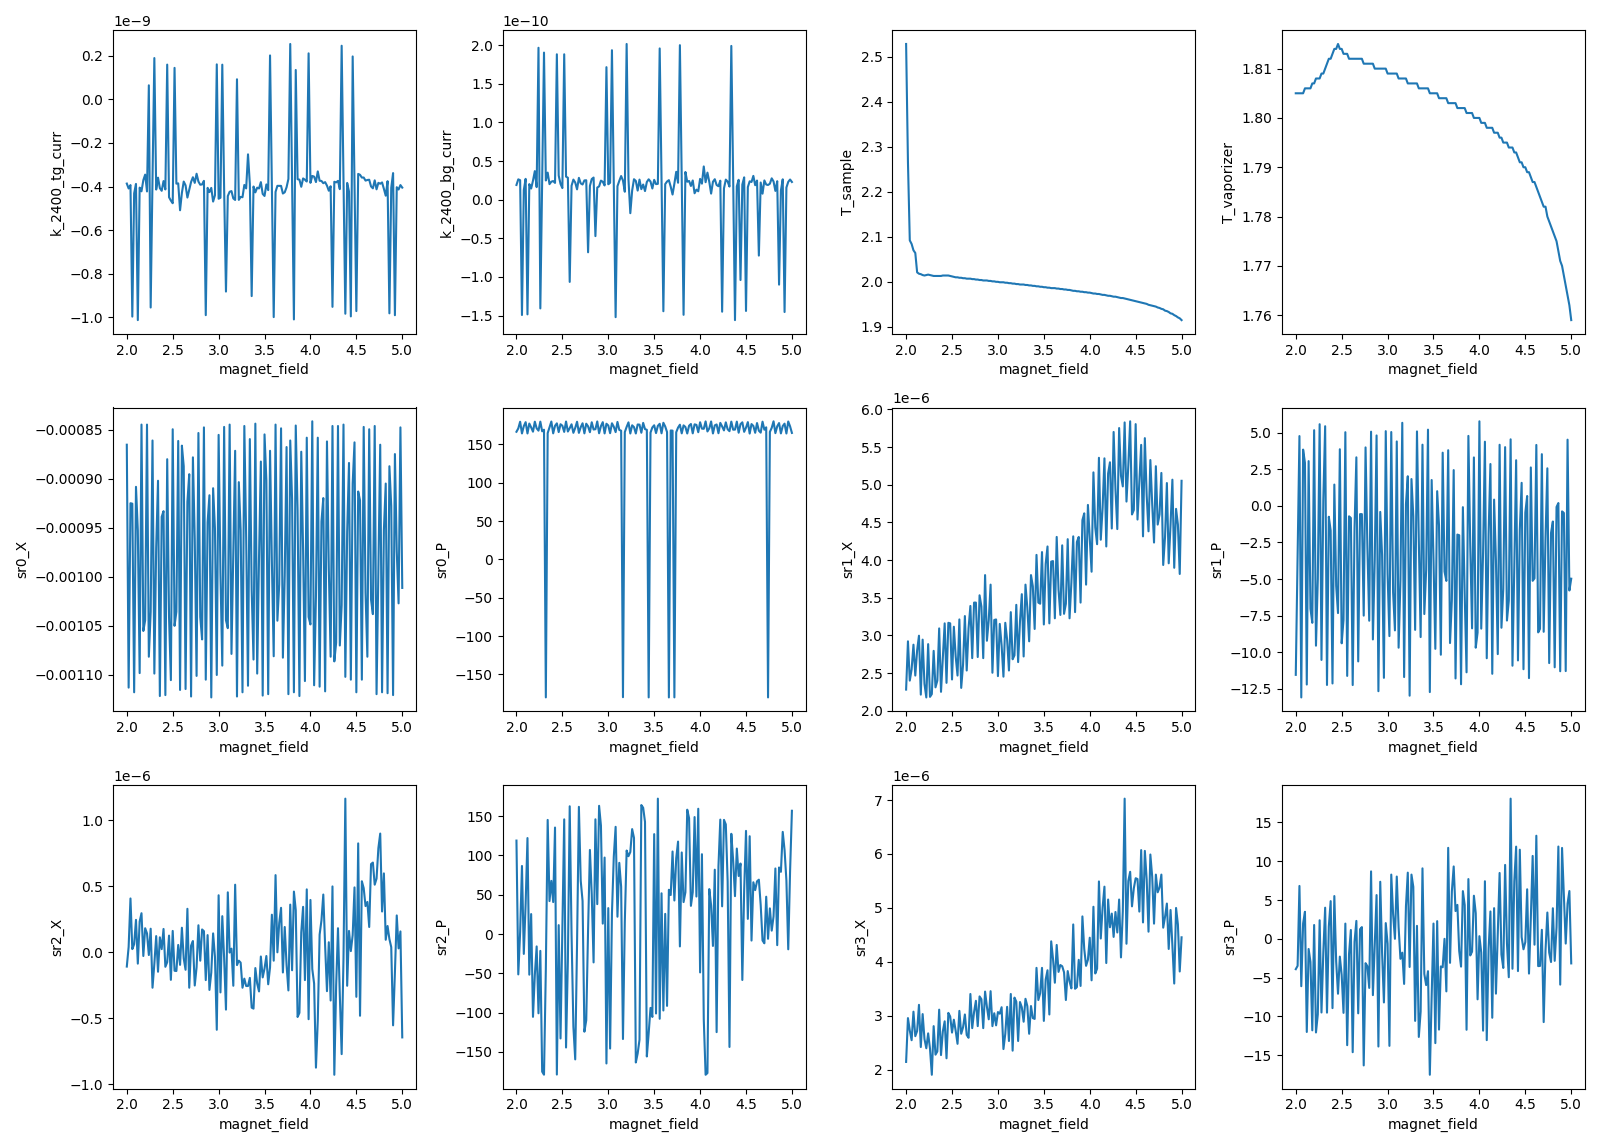

2026-08-19 23:47:11,787 [INFO] Completed in 0h 32m 13s


2026-08-19 23:47:11,787 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260818-vti-01\data\13\data.tsv.gz


rung 2.5 K sweep done; B at +2.00 T
T_sample: VTI_sample.txt live — age 6s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 6s, period 5s
T_sample: VTI_sample.txt live — age 6s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 6s, period 5s


T_sample: VTI_sample.txt live — age 6s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 6s, period 5s


T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s


...

T_sample: VTI_sample.txt live — age 2s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 2s, period 5s


T_sample: VTI_sample.txt live — age 2s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 2s, period 5s


T_sample: VTI_sample.txt live — age 2s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 2s, period 5s
rung 4.0 K accepted at T=3.985 K (ranges 1,1)
2026-08-19 23:53:31,944 [INFO] Ramping magnet_field: 2.006085931506849 -> 2.0


2026-08-19 23:53:35,068 [INFO] Starting sweep with ID 14


2026-08-19 23:53:35,069 [INFO] Minimum duration 0h 2m 31s


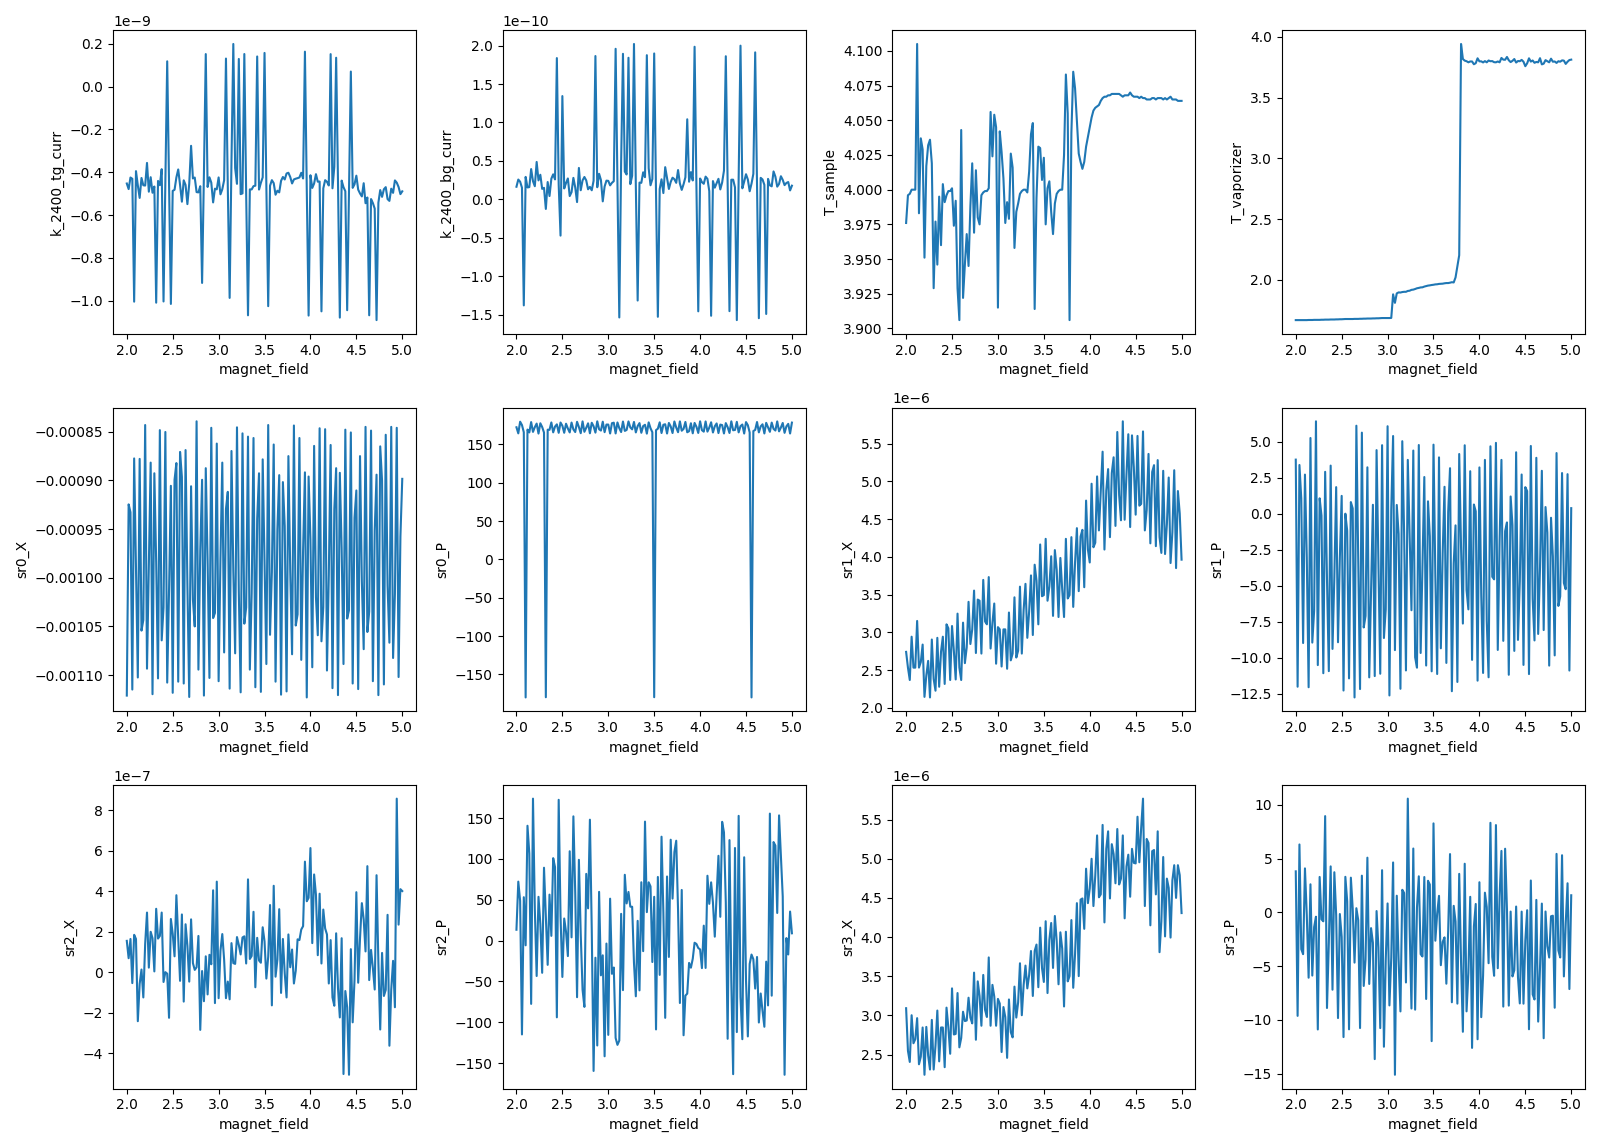

2026-08-20 00:25:49,259 [INFO] Completed in 0h 32m 13s


2026-08-20 00:25:49,260 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260818-vti-01\data\14\data.tsv.gz


rung 4.0 K sweep done; B at +5.01 T
T_sample: VTI_sample.txt live — age 0s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 0s, period 5s
T_sample: VTI_sample.txt live — age 0s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 0s, period 5s


T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s


T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s


...

T_sample: VTI_sample.txt live — age 3s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 3s, period 5s


T_sample: VTI_sample.txt live — age 3s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 3s, period 5s


T_sample: VTI_sample.txt live — age 3s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 3s, period 5s
rung 6.0 K accepted at T=6.001 K (ranges 1,1)
2026-08-20 00:29:49,343 [INFO] Ramping magnet_field: 5.006058575342466 -> 5.0


2026-08-20 00:29:52,469 [INFO] Starting sweep with ID 15


2026-08-20 00:29:52,479 [INFO] Minimum duration 0h 2m 31s


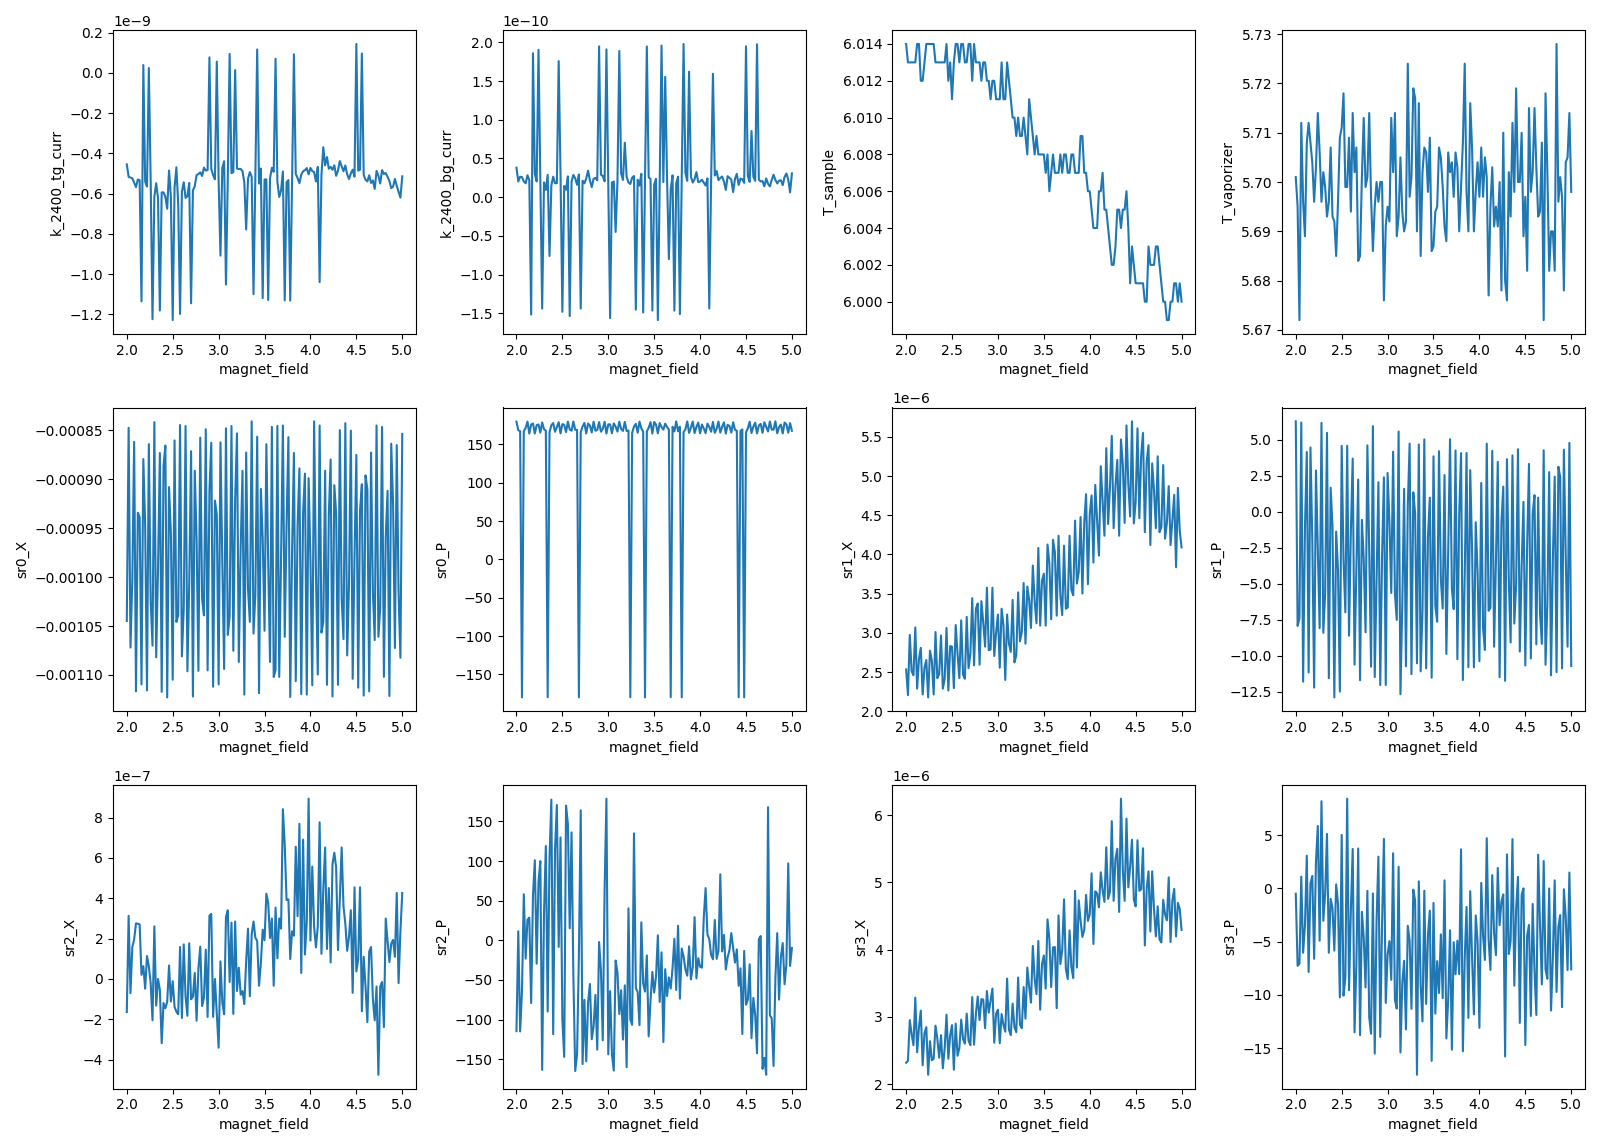

2026-08-20 01:02:07,014 [INFO] Completed in 0h 32m 13s


2026-08-20 01:02:07,015 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260818-vti-01\data\15\data.tsv.gz


rung 6.0 K sweep done; B at +2.00 T
T_sample: VTI_sample.txt live — age 3s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 3s, period 5s
T_sample: VTI_sample.txt live — age 3s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 3s, period 5s


T_sample: VTI_sample.txt live — age 2s, period 6s
T_vaporizer: VTI_vaporizer.txt live — age 2s, period 6s


T_sample: VTI_sample.txt live — age 2s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 2s, period 5s


...

T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s


T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s


T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s
rung 8.0 K accepted at T=8.001 K (ranges 1,1)
2026-08-20 01:06:07,145 [INFO] Ramping magnet_field: 2.0060864520547943 -> 2.0


2026-08-20 01:06:10,278 [INFO] Starting sweep with ID 16


2026-08-20 01:06:10,279 [INFO] Minimum duration 0h 2m 31s


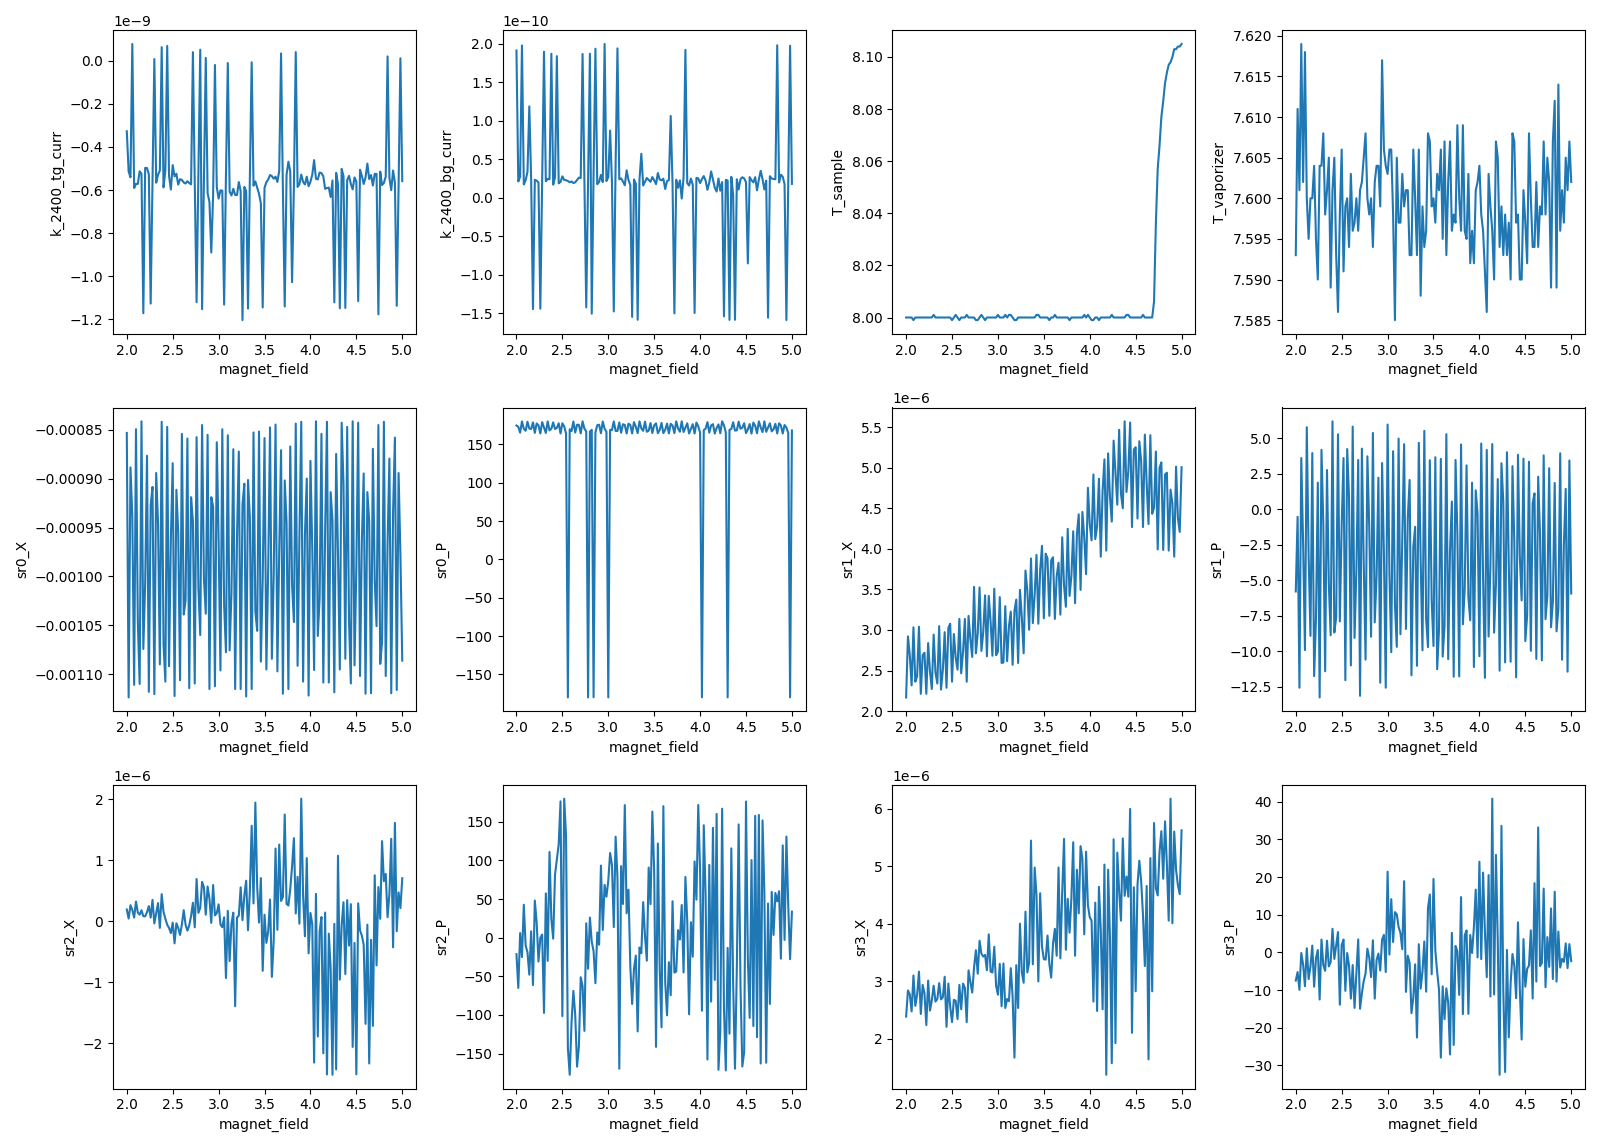

2026-08-20 01:38:24,471 [INFO] Completed in 0h 32m 13s


2026-08-20 01:38:24,472 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260818-vti-01\data\16\data.tsv.gz


rung 8.0 K sweep done; B at +5.01 T
T_sample: VTI_sample.txt live — age 3s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 3s, period 5s
T_sample: VTI_sample.txt live — age 3s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 3s, period 5s


T_sample: VTI_sample.txt live — age 3s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 3s, period 5s


T_sample: VTI_sample.txt live — age 3s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 3s, period 5s


...

T_sample: VTI_sample.txt live — age 2s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 2s, period 5s


T_sample: VTI_sample.txt live — age 2s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 2s, period 5s


T_sample: VTI_sample.txt live — age 2s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 2s, period 5s
rung 11.0 K accepted at T=11.047 K (ranges 1,1)
2026-08-20 01:42:24,555 [INFO] Ramping magnet_field: 5.006073726027397 -> 5.0


2026-08-20 01:42:27,690 [INFO] Starting sweep with ID 17


2026-08-20 01:42:27,691 [INFO] Minimum duration 0h 2m 31s


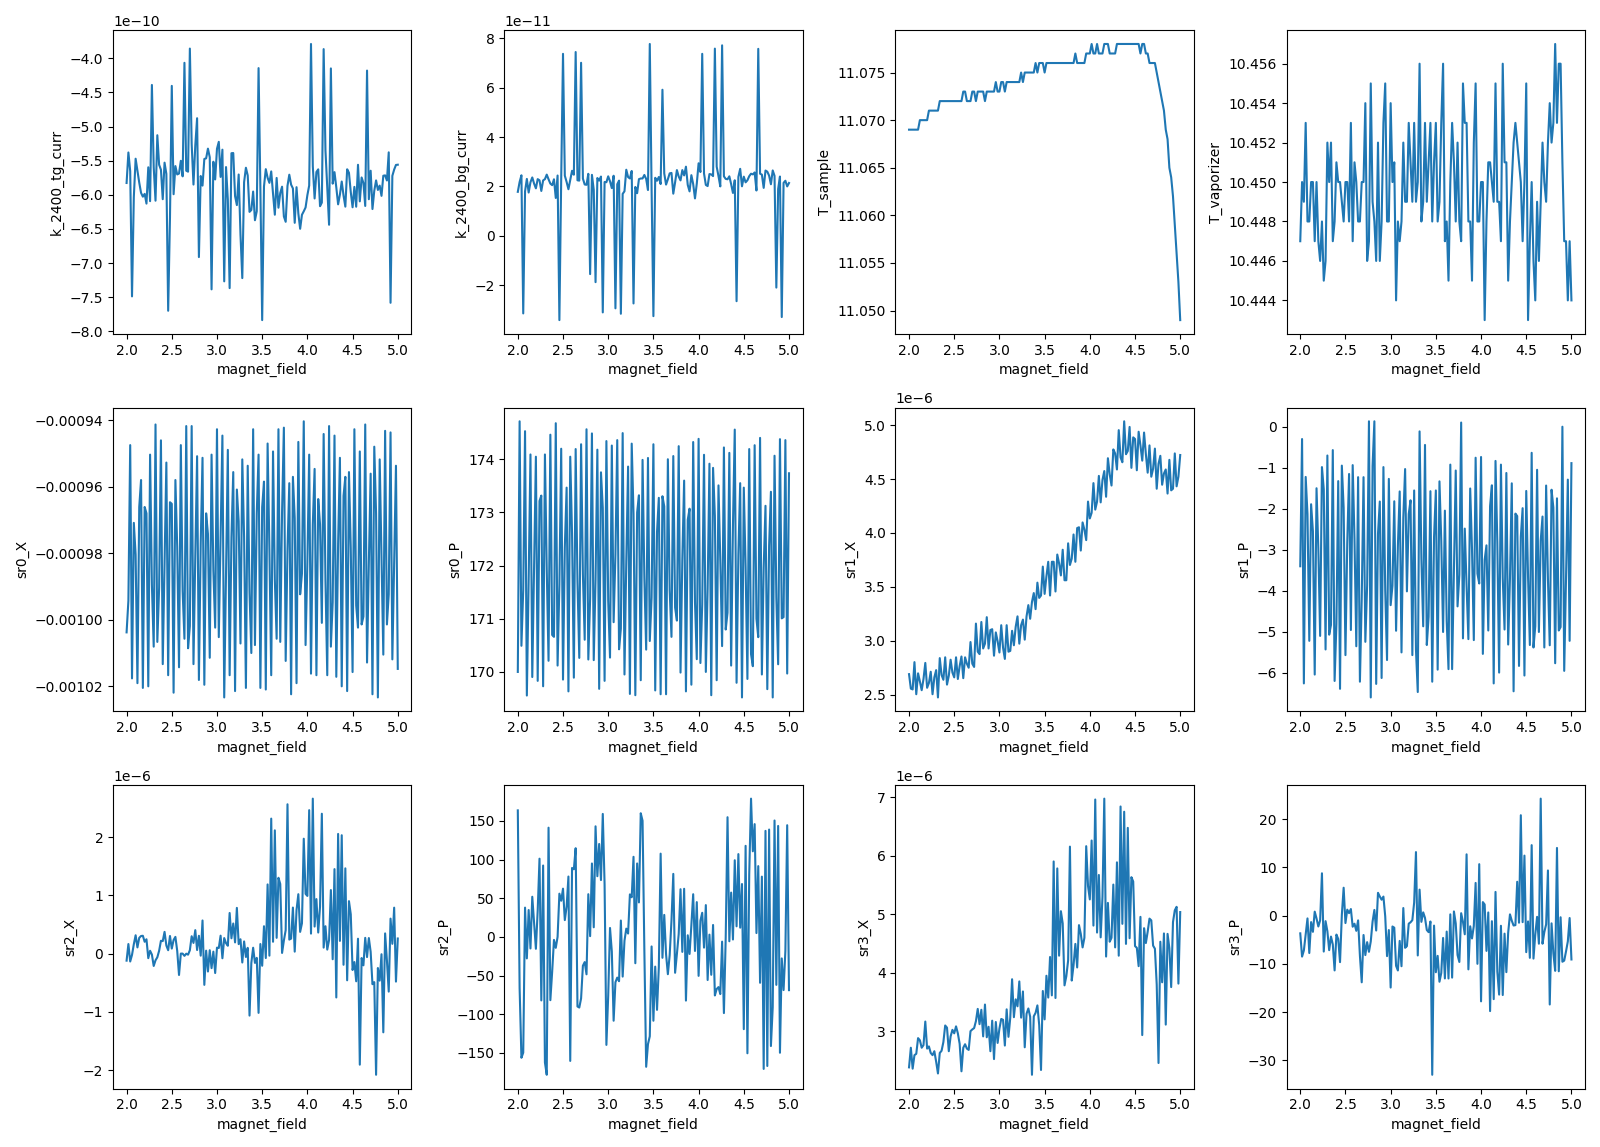

2026-08-20 02:14:42,228 [INFO] Completed in 0h 32m 13s


2026-08-20 02:14:42,229 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260818-vti-01\data\17\data.tsv.gz


rung 11.0 K sweep done; B at +2.00 T
T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s
T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s


T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s


T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5s, period 5s


...

T_sample: VTI_sample.txt live — age 3s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 3s, period 5s


T_sample: VTI_sample.txt live — age 3s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 3s, period 5s


T_sample: VTI_sample.txt live — age 3s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 3s, period 5s
rung 15.0 K accepted at T=15.006 K (ranges 1,1)
2026-08-20 02:18:42,269 [INFO] Ramping magnet_field: 2.0060726027397258 -> 2.0


2026-08-20 02:18:45,388 [INFO] Starting sweep with ID 18


2026-08-20 02:18:45,389 [INFO] Minimum duration 0h 2m 31s


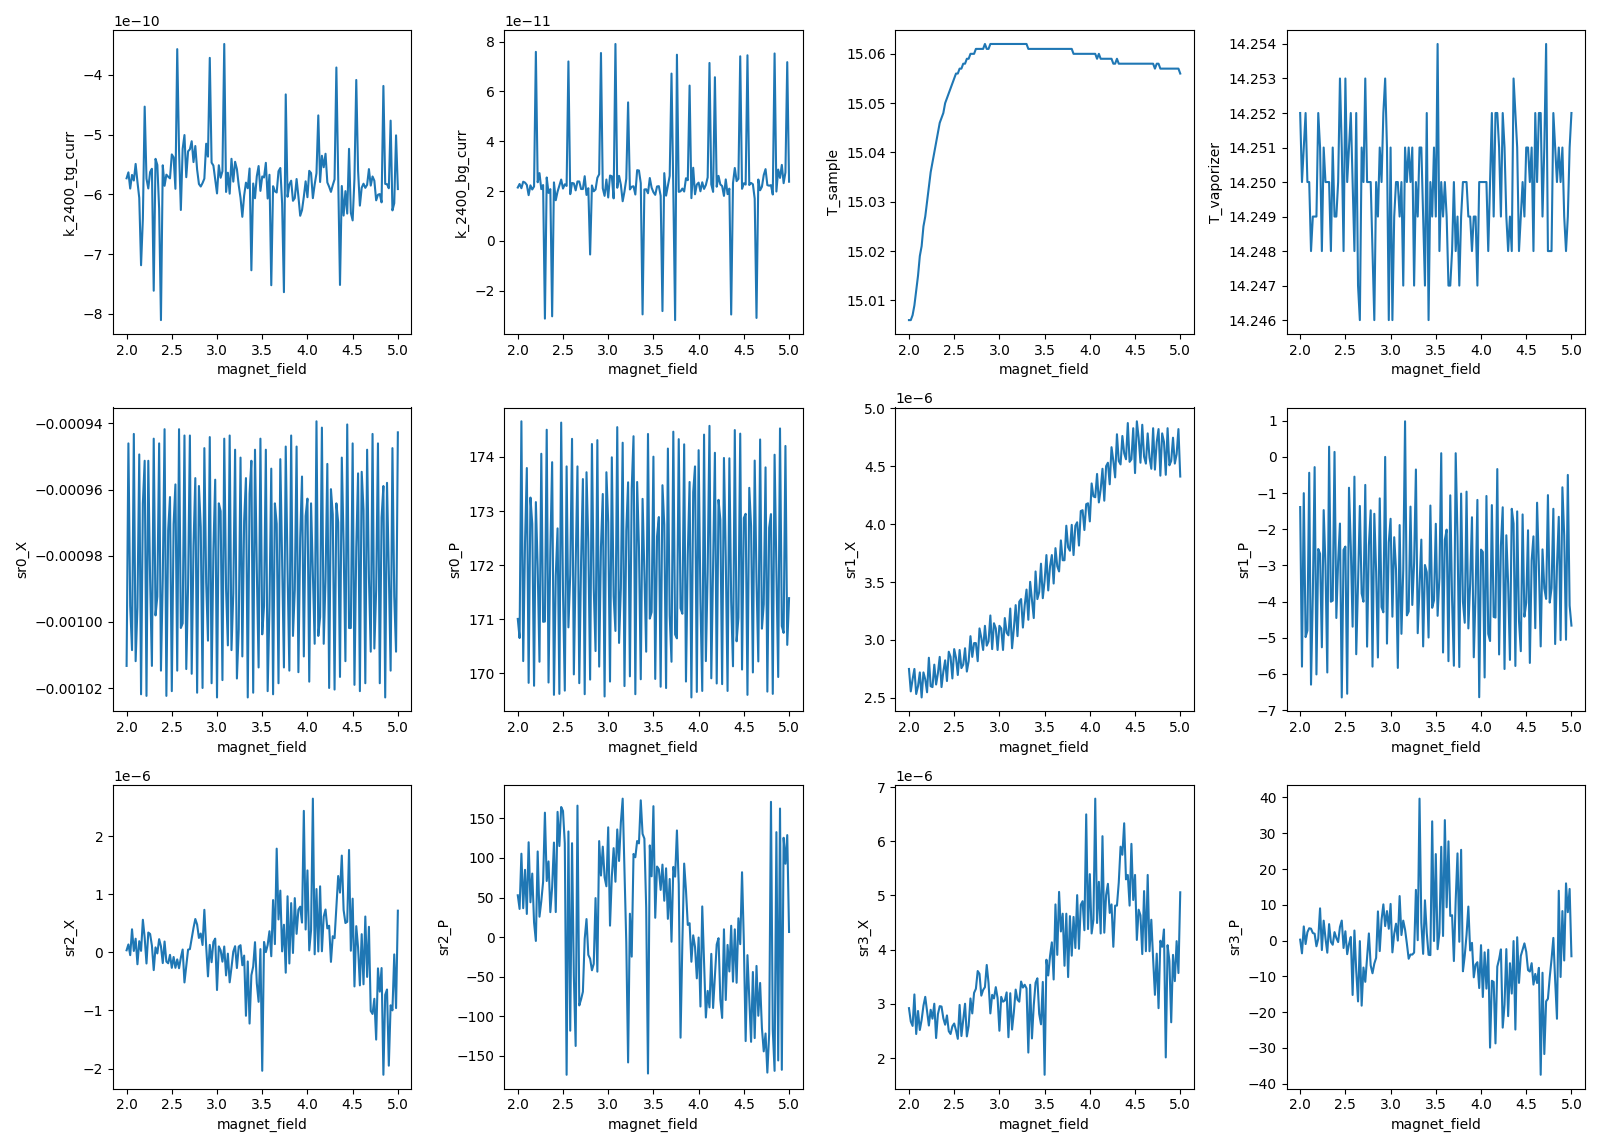

2026-08-20 02:50:59,727 [INFO] Completed in 0h 32m 13s


2026-08-20 02:50:59,728 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260818-vti-01\data\18\data.tsv.gz


rung 15.0 K sweep done; B at +5.01 T
ladder complete; heaters off, cooling passively toward base. B at +5.01 T, gates at n=-1.74. T=15.06 K


In [32]:
# === LK mass ladder (temperature-dependence-vti, Flavor B) — branch A mass ===
# n = -1.74e12 at true D=0; per rung: field sweep 2<->5 T (alternating, from the
# live field), 151 pts @ 20 mT, delay 1 s. Rungs [1.2(base), 2.5, 4, 6, 8, 11, 15] K.
# Guards: hover acceptance, freshness (>=2-3 write periods), direction-aware
# runaway on T_vap, set_both(T, ratio=0.95) only. One file per rung.

import time as _time

# --- preconditions ---
_B, _T = magnet.field(), T_sample()
print(f"preconditions: B={_B:+.3f} T (expect ~5, run-12 end), T={_T:.3f} K, "
      f"Vtg={k_tg.volt():+.4f}, Vbg={k_bg.volt():+.4f} (n=-1.74 point), "
      f"drive={sr1.amplitude()*1e3:.0f} mV, heater ranges={heater.sample_range()},{heater.vaporizer_range()}")
assert _T < 2.2, "T not near base band — stop"  # recovering from the v1 fault at 1.94 K
assert heater.sample_range() == 0 and heater.vaporizer_range() == 0, "heaters not off at start — stop"
try:
    _ami = qcodes.Instrument.find_instrument("ami_he")
    print(f"He level: {_ami.He_level():.2f} in")
except Exception as e:
    print(f"He read unavailable: {e!r}")

n_t = -1.74
Vtg_t, Vbg_t = calc_gate_voltages(n_t, -0.009, c_tg_cal, c_bg_cal, n_offset=n_off_e12)
k_tg.volt(Vtg_t); k_bg.volt(Vbg_t)   # re-assert the point (already there)

RUNGS = [2.5, 4.0, 6.0, 8.0, 11.0, 15.0]   # K; base rung done (run 12); ascend
N_PTS, DWELL = 151, 1
prev_T = 1.2   # run-12 base rung

def _fresh():
    assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"], max_age=15, max_period=12)
    assert_thermometry_live("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"], max_age=15, max_period=12)

def wait_rung(target, prev_T, t_max=2400):
    """Hover acceptance v2 (ladder v1 fault: loop equilibrated 0.06 K below the
    absolute band and timed out). Accept STABILITY at the achieved equilibrium:
    spread < 0.1 K over 90 s, T >= prev_T + 0.3 (monotonic ladder), minimum
    240 s on the rung. The fp'd T is the fit axis; nominal rungs are labels.
    Warn (never fault) outside [target-0.8, target+3]; sanity fence +/-5 K."""
    t0 = _time.time(); _fresh()
    Tv0 = T_vaporizer()
    hist = []
    while True:
        _fresh()
        T, Tv = T_sample(), T_vaporizer()
        now = _time.time()
        hist.append((now, T)); hist = [(t, x) for t, x in hist if now - t <= 90]
        if Tv > max(Tv0, target) + 2.0:                    # true runaway only
            heater.off('both')
            raise RuntimeError(f"runaway: T_vap={Tv:.2f} K > start {Tv0:.2f} & target {target} + 2")
        w = [x for _, x in hist]
        if (now - t0 > 240 and len(w) >= 8 and (max(w) - min(w)) < 0.1
                and T >= prev_T + 0.3 and abs(T - target) < 5.0):
            if not (target - 0.8) <= T <= (target + 3):
                print(f"  note: rung {target} K accepted off-nominal at {T:.3f} K (stable equilibrium)")
            return T
        if now - t0 > t_max:
            heater.off('both')
            raise RuntimeError(f"rung {target} K settle timeout ({t_max}s), T={T:.3f}")
        interruptible_sleep(10)

for rung in RUNGS:
    heater.set_both(rung, ratio=0.95)     # sanctioned call, ratio fixed (consent-gated otherwise)
    T_acc = wait_rung(rung, prev_T)
    prev_T = T_acc
    print(f"rung {rung} K accepted at T={T_acc:.3f} K (ranges {heater.sample_range()},{heater.vaporizer_range()})")

    B_now = magnet.field()                    # alternate direction from the LIVE field
    B_vec = (np.linspace(2.0, 5.0, N_PTS) if abs(B_now - 2.0) < abs(B_now - 5.0)
             else np.linspace(5.0, 2.0, N_PTS))
    mc = {**meas_config,
          "sample_temperature:": T_sample(),
          "Si (V)": 0.0,
          "comments": (f"temperature-dependence-vti Flavor B (LK mass, branch A): rung "
                       f"{rung} K (accepted {T_acc:.3f} K), n={n_t}e12 true D=0 "
                       f"(Vtg={Vtg_t:+.4f}, Vbg={Vbg_t:+.4f}), B {B_vec[0]:.1f}->{B_vec[-1]:.1f} T "
                       f"151 pts @ 20 mT, delay 1 s, drive 100 mV, sens sr1/sr3 200uV.")}
    s = sweep.AsyncStation(mc)
    s.add_comment('temperature-dependence-vti')
    s.add_comment(f'LK rung {rung} K: n = {n_t}e12, D = 0 true, B {B_vec[0]:.1f} -> {B_vec[-1]:.1f} T')
    xp = magnet.field
    s.fp(k_tg.curr).fp(k_bg.curr)
    s.fp(T_sample); s.fp(T_vaporizer)
    s.plot(xp, k_tg.curr); s.plot(xp, k_bg.curr)
    s.plot(xp, T_sample); s.plot(xp, T_vaporizer)
    for lia in [sr0, sr1, sr2, sr3]:
        s.fp(lia.X).fp(lia.P)
        s.plot(xp, lia.X); s.plot(xp, lia.P)
    s.ramp(magnet.field, B_vec[0])
    s.sweep(magnet.field, B_vec, delay=DWELL)
    print(f"rung {rung} K sweep done; B at {magnet.field():+.2f} T")

heater.off('both')
print(f"ladder complete; heaters off, cooling passively toward base. "
      f"B at {magnet.field():+.2f} T, gates at n={n_t}. T={T_sample():.2f} K")


## HERA — session close-out: return-to-initial (E1 auto, per brief)

> **02:54** · close\_out(return-to-initial): restore state0, heaters off, gates+Si to 0, B 5->0 T; full readback · **ETA ~03:39** (≈45 min)

Campaign arc complete: the call is landed in ana (cell 33) — sr1 region ABA/Bernal (strong), sr3 consistent-with, sr2 uninformative, ML-pocket hedge stated. Close-out per the brief's named ask (return-to-initial): replay state0 (drive back to 4 mV, sensitivities, τ, NPLC, gates), LS335 ranges off (idempotent — already off), gates and Si parked at 0 (Si through the ramped parameter), then the field endpoint = session-start 0 T (5→0, ~37 min blocking ramp). PS/output untouched. Readback lands below and goes to session_notes as the handoff record.

In [33]:
# === Session close-out: return-to-initial (brief's ask; session-closeout + VTI variant) ===
# Field endpoint per the ask = session-start field (0 T; VERIFY read 0.006 T).
# restore = state0 (bring-up capture): drive 4 mV, sensitivities, taus, NPLC, gates.
# Heaters: LS335 ranges off (VTI delta; already off after the ladder — idempotent).
# Si park through the ramped parameter (VTI delta) — k_si is in state0 (V_si = 0).
# No mux this cooldown (hardwired) — mux= omitted. PS/output untouched (operator-only).

_T = T_sample()
print(f"pre-closeout: B={magnet.field():+.3f} T, T={_T:.3f} K (recooling from ladder), "
      f"Vtg={k_tg.volt():+.4f}, Vbg={k_bg.volt():+.4f}, Vsi={dc205.voltage():+.2f}")

from sharpelab_nb.closeout import close_out
close_out(
    (magnet.field, 0.0),
    restore=state0,
    heaters=[("LS335 ranges off", lambda: heater.off("both"))],
    gates=[(k_tg.volt, 0.0), (k_bg.volt, 0.0), (dc205.smart_voltage, 0.0)],
    extra_readback={"T_sample": T_sample, "T_vaporizer": T_vaporizer},
)


pre-closeout: B=+5.006 T, T=1.783 K (recooling from ladder), Vtg=-0.7986, Vbg=-0.9840, Vsi=+0.00
-- restore (19 params)


-- heaters
   LS335 ranges off
-- gates
-- field -> 0.0



--- close-out readback ---
drive_V : 0.004  <Numbers 0.004<=v<=5.0>
drive_Hz : 13.777  <Numbers 0.001<=v<=102000.0>
sr0_sens : 0.1  <Enum: {0.2, 0.5, 2e-09, 1, 1e-08, 5e-05, 2e-08, 0.0001, 0.05, 0.0002, 5e-06, 5e-08, 1e-06, 0.1, 5e-09, 2e-05, 0.02, 5e-07, 1e-05, 0.01, 2e-07, 0.005, 1e-07, 2e-06, 0.002, 0.001, 0.0005}>
sr0_tau : 0.3  <Enum: {0.3, 1, 3, 10, 10000.0, 0.0001, 30, 300, 30000.0, 3000.0, 3e-05, 0.03, 0.1, 0.0003, 100, 1e-05, 1000.0, 0.01, 0.003, 0.001}>
sr0_slope : 24  <Enum: {24, 18, 12, 6}>
sr1_sens : 0.001  <Enum: {0.2, 0.5, 2e-09, 1, 1e-08, 5e-05, 2e-08, 0.0001, 0.05, 0.0002, 5e-06, 5e-08, 1e-06, 0.1, 5e-09, 2e-05, 0.02, 5e-07, 1e-05, 0.01, 2e-07, 0.005, 1e-07, 2e-06, 0.002, 0.001, 0.0005}>
sr1_tau : 0.1  <Enum: {0.3, 1, 3, 10, 10000.0, 0.0001, 30, 300, 30000.0, 3000.0, 3e-05, 0.03, 0.1, 0.0003, 100, 1e-05, 1000.0, 0.01, 0.003, 0.001}>
sr1_slope : 24  <Enum: {24, 18, 12, 6}>
sr2_sens : 0.0001  <Enum: {0.2, 0.5, 2e-09, 1, 1e-08, 5e-05, 2e-08, 0.0001, 0.05, 0.0002, 5e-06, 

V_tg : 0.001538031  <Numbers -0.8<=v<=0.8>
V_bg : 0.0  <Numbers -5.0<=v<=5.0>
V_si : 0.0  <Numbers -20.0<=v<=20.0>
field : 0.002611986301369863 T  <Numbers -10.0<=v<=10.0>
T_sample : 1.466
T_vaporizer : 1.226


## HERA — quality Landau fan, τ = 300 ms (operator-requested)

> **08:59** · QUALITY fan: tau=300ms all channels, dwell 2.5s, n -0.70..-1.74e12 (53) x B 0.9->5.0 T uniform-1/B (131 rows), drive 100 mV; ends 5 T, ML descent next · **ETA ~14:59** (≈6h)

Operator direction: a higher-quality fan at τ = 300 ms to firm the ABA call and yield a clean fan artifact, with the descent used for another τ = 300 ms measurement. Design: same D = 0(true) hole n-line as run 10 (−0.70→−1.74×10¹², 53 pts — direct comparability), B **0.9 → 5.0 T uniform-1/B, 131 rows** (Δ(1/B) = 0.007/T, ×2.9 Nyquist on 2F_A ≈ 33 T). Per-column δF ≈ 1.1 T (vs run 10's 2.5) — a ~2.4 T ML tone becomes per-column resolvable; B_lo sits below branch A's 1.67 T onset deliberately, because the light ML band lives there (sub-onset rows are background for A but signal for ML). τ = 0.3 s on all four lock-ins (×1.7 noise-bandwidth SNR), dwell 2.5 s = 8.3τ (24 dB floor); drive 100 mV, sensitivities as the campaign standard (headroom rule). Acquisition-quality note per the investigation: this fan settles *harder* than runs 8–11, so its columns may resolve what they didn't — the reverse never overturns.

**Cost**: 131 × (53 × 2.63 s + turnaround) + ~30 min B-ramps ≈ **6 h realistic**. Ends at 5 T; the descent then takes the τ = 300 ms ML spot check (5→0.5 T, 4 mT, ~55 min, δF ≈ 0.56 T) riding the magnet home, then B parks at 0. Checkpoints: first rows, 45-min progress, clip warnings.


preconditions: B=+0.0061 T (~0, close-out endpoint), T=1.238 K (base), Vtg=+0.0016, Vbg=+0.0000, Vsi=+0.00
He level: 15.92 in


config: drive 100 mV @ 13.777 Hz; taus [0.3, 0.3, 0.3, 0.3]; sens sr0 0.01, sr1/3 200 uV, sr2 50 uV; dwell 2.5 s = 8.3 tau
B rows: 131, steps 5.7..169.3 mT; n-line -0.7..-1.74 e12 (53 pts)
2026-08-20 08:59:30,699 [INFO] Ramping k_2400_tg_volt: 0.001549183 -> -0.33261063275767094


2026-08-20 08:59:31,200 [INFO] Ramping k_2400_bg_volt: 0.0 -> -0.3367792406297187


2026-08-20 08:59:31,629 [INFO] Ramping magnet_field: 0.006091068493150684 -> 0.9


2026-08-20 09:06:18,467 [INFO] Starting multimegasweep with ID 19


2026-08-20 09:06:18,470 [INFO] Minimum duration 4h 51m 28s


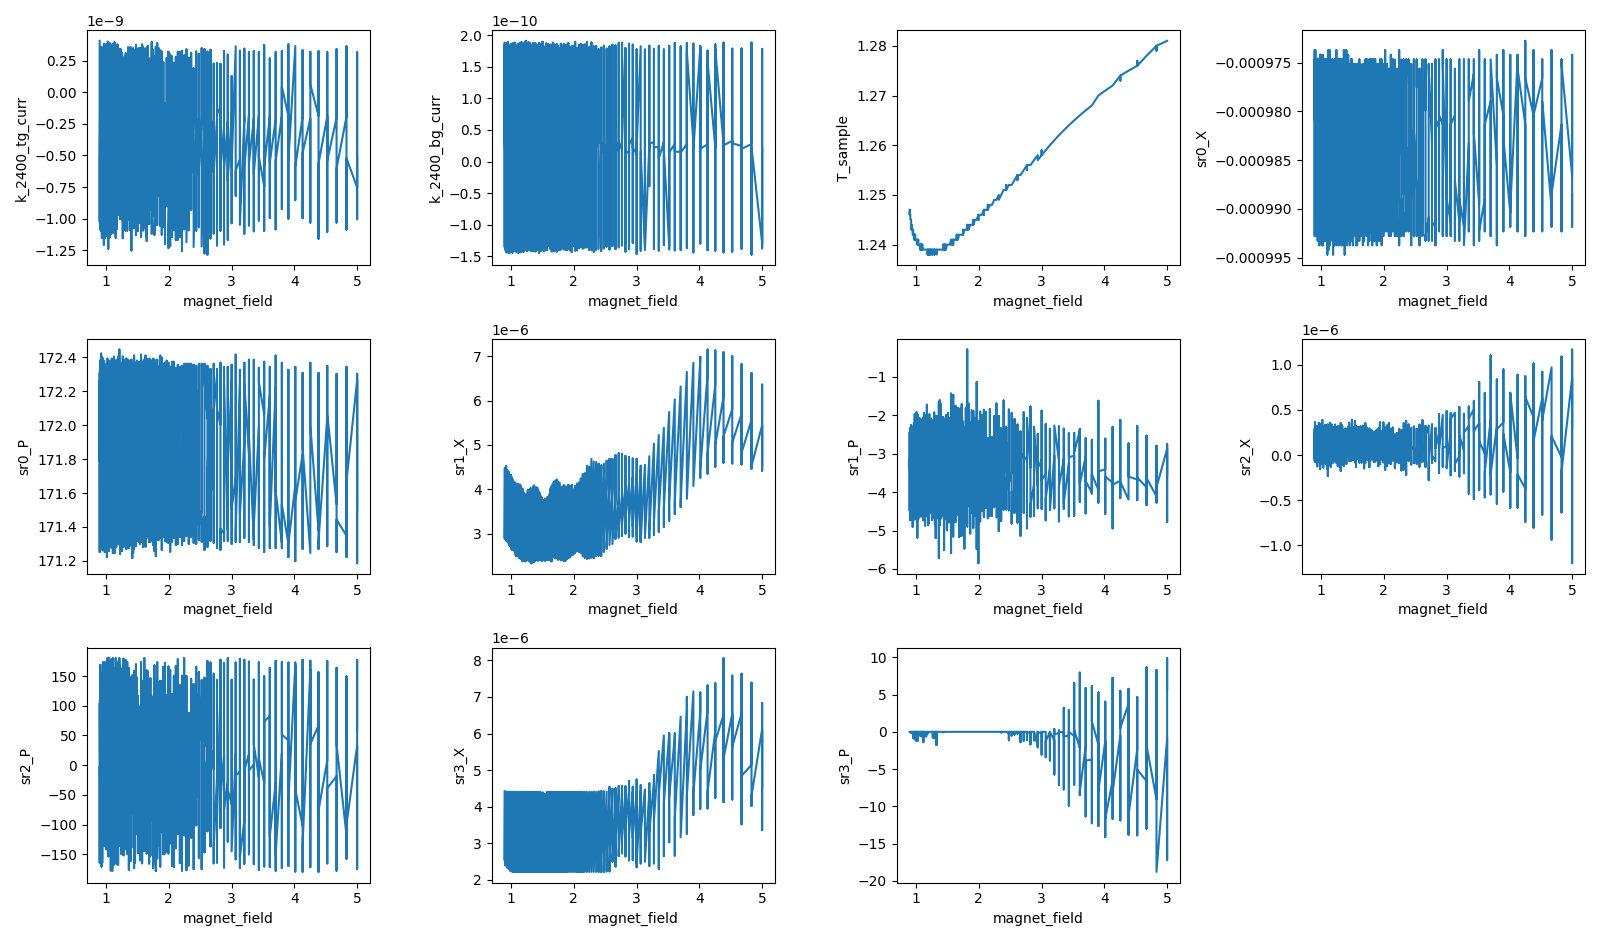

2026-08-20 14:53:00,016 [INFO] Completed in 5h 46m 40s


2026-08-20 14:53:00,016 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260818-vti-01\data\19\data.tsv.gz


quality fan done; B at +5.01 T — descent ML spot check next


In [34]:
# === Quality Landau fan (operator-requested): tau = 300 ms, D = 0 hole side ===
# Goals: firm the ABA call (ML band now per-column resolvable, dF ~ 1.1 T) and a
# publication-clean (n, B) fan. B extends below branch A's onset deliberately —
# the light ML band (~2-2.4 T, m* ~ 0.01 me) lives at low B.

# --- preconditions ---
_B, _T = magnet.field(), T_sample()
print(f"preconditions: B={_B:+.4f} T (~0, close-out endpoint), T={_T:.3f} K (base), "
      f"Vtg={k_tg.volt():+.4f}, Vbg={k_bg.volt():+.4f}, Vsi={dc205.voltage():+.2f}")
assert abs(_B) < 0.02 and _T < 1.5, "B/T precondition failed — stop"
assert abs(k_bg.volt()) < 0.01 and abs(dc205.voltage()) < 0.05, "gates not parked — stop"
try:
    _ami = qcodes.Instrument.find_instrument("ami_he")
    print(f"He level: {_ami.He_level():.2f} in")
except Exception as e:
    print(f"He read unavailable: {e!r}")

# --- campaign config (state0 was restored at close-out; re-establish + tau bump) ---
sr1.amplitude(0.100)                       # 100 mV drive (ohmic-verified; contact-limited ~1 nA)
sr0.sensitivity(0.01)
sr1.sensitivity(200e-6); sr3.sensitivity(200e-6); sr2.sensitivity(50e-6)
for _l in (sr0, sr1, sr2, sr3):
    _l.time_constant(0.3)                  # operator-requested tau = 300 ms
print(f"config: drive {sr1.amplitude()*1e3:.0f} mV @ {sr1.frequency():.3f} Hz; "
      f"taus {[l.time_constant() for l in (sr0, sr1, sr2, sr3)]}; "
      f"sens sr0 {sr0.sensitivity()}, sr1/3 200 uV, sr2 50 uV; dwell 2.5 s = 8.3 tau")

# fast axis: same D=0 n-line as run 10 (comparability)
ns = np.linspace(-0.70, -1.74, 53)
Vtgs, Vbgs = calc_gate_voltages(ns, -0.009 * np.ones_like(ns),
                                c_tg_cal, c_bg_cal, n_offset=n_off_e12)
Vtgs, Vbgs = np.asarray(Vtgs), np.asarray(Vbgs)
assert np.all(np.abs(Vtgs) <= 0.8) and np.all(np.abs(Vbgs) <= 5.0), "n-line exits validators"

# slow axis: uniform-1/B, 0.9 -> 5.0 T, d(1/B) = 0.007 /T (131 rows)
B_vec = field_invB(0.9, 5.0, 131)
print(f"B rows: {len(B_vec)}, steps {np.diff(B_vec).min()*1e3:.1f}..{np.diff(B_vec).max()*1e3:.1f} mT; "
      f"n-line {ns[0]}..{ns[-1]} e12 ({len(ns)} pts)")

mc = {**meas_config,
      "sample_temperature:": T_sample(),
      "Si (V)": 0.0,
      "comments": ("landau-fan-vti QUALITY (operator-requested, tau=300ms): hole side "
                   "D=0 true (D_offset +0.009), n -0.70..-1.74e12 (53 pts) x B 0.9->5.0 T "
                   "uniform-1/B (131 rows, d(1/B)=0.007/T), fast_delay 2.5 s (8.3 tau), "
                   "drive 100 mV, sens sr1/sr3 200uV sr2 50uV, all taus 0.3 s. "
                   "B_lo below branch-A onset deliberately: ML band target. "
                   "Firms runs 10/12-18 ABA call; artifact-grade map.")}
s = sweep.AsyncStation(mc)
s.add_comment('landau-fan-vti')
s.add_comment('quality fan tau=300ms: D = 0 true, n = -0.70 to -1.74e12, B = 0.9 to 5.0 T uniform-1/B')

xp = magnet.field
s.fp(k_tg.curr).fp(k_bg.curr)
s.fp(T_sample)
s.plot(xp, k_tg.curr)
s.plot(xp, k_bg.curr)
s.plot(xp, T_sample)
for lia in [sr0, sr1, sr2, sr3]:
    s.fp(lia.X).fp(lia.P)
    s.plot(xp, lia.X)
    s.plot(xp, lia.P)

s.ramp(k_tg.volt, Vtgs[0])
s.ramp(k_bg.volt, Vbgs[0])
s.ramp(magnet.field, 0.9)
interruptible_sleep(10)

try:
    s.multimegasweep([magnet.field], [B_vec],
                     [k_tg.volt, k_bg.volt], [Vtgs, Vbgs],
                     slow_delay=1, fast_delay=2.5)
finally:
    pass  # gates stay on the line; the descent spot check follows at n = -1.74
print(f"quality fan done; B at {magnet.field():+.2f} T — descent ML spot check next")


## HERA — descent ML spot check, τ = 300 ms (E1 auto; staged, fires at fan completion)

> **13:30** · ML descent: n=-1.74 trueD0, B 5->0.5 T @ 4 mT (1126 pts), dwell 2.5s, tau 300ms; then gates parked, B->0 · **ETA ~15:00** (≈1h30m)

The way down, per operator direction: definitive ML-band record at n = −1.74, true D = 0 — B 5 → 0.5 T at 4 mT (1126 pts), dwell 2.5 s = 8.3τ. δF = 0.56 T (best of the campaign), ×1.7 SNR over run 11; Nyquist ×2.5 on branch A to the low edge (2F_A aliases only below ~0.7 T where it is dead). Interim fan read at row 85 showed a bg-degree-sensitive hint at 2.0–2.2 T in the ML band — this record is what confirms or retires it. Ends: gates parked, B ramped to 0 (cooldown endpoint). Priced 1 h 30 m (4.5 s/pt at the τ = 300 ms dwell — the earlier 55 min figure used the τ = 0.1 rate).

In [36]:
# === Descent ML spot check, tau = 300 ms: n = -1.74, D = 0(true), B 5 -> 0.5 T ===
# The campaign's sharpest ML-band record: dF = 1/(1/0.5 - 1/5) = 0.56 T,
# x1.7 SNR over run 11, 4 mT uniform-B. Rides the magnet home from the fan.
# Then B parks at 0 (operator: "use the way down ... or simply cooldown").

# --- preconditions ---
_B, _T = magnet.field(), T_sample()
print(f"preconditions: B={_B:+.3f} T (expect ~5, fan end), T={_T:.3f} K, "
      f"drive={sr1.amplitude()*1e3:.0f} mV, taus={[l.time_constant() for l in (sr0,sr1,sr2,sr3)]}")
assert abs(_B - 5.0) < 0.05, f"B={_B:+.3f}, expected 5 T — stop"
assert _T < 1.5, "not at base — stop"
assert abs(sr1.amplitude() - 0.100) < 0.005 and abs(sr1.time_constant() - 0.3) < 0.01

n_t = -1.74
Vtg_t, Vbg_t = calc_gate_voltages(n_t, -0.009, c_tg_cal, c_bg_cal, n_offset=n_off_e12)
k_tg.volt(Vtg_t); k_bg.volt(Vbg_t)   # fan's line end is n=-1.74 — re-assert
print(f"point: n={n_t}e12 true D=0 -> Vtg={Vtg_t:+.4f}, Vbg={Vbg_t:+.4f}")

B_vec = np.linspace(5.0, 0.5, 1126)   # dB = 4 mT descending
mc = {**meas_config,
      "sample_temperature:": T_sample(),
      "Si (V)": 0.0,
      "comments": (f"sdh-spot-check ML descent, tau=300ms: n={n_t}e12 true D=0 "
                   f"(Vtg={Vtg_t:+.4f}, Vbg={Vbg_t:+.4f}), B 5.0->0.5 T uniform-B "
                   f"dB=4 mT (1126 pts), dwell 2.5 s = 8.3 tau, drive 100 mV, "
                   f"sens sr1/sr3 200uV sr2 50uV. dF=0.56 T; definitive ML-band "
                   f"record; pairs with runs 8/11/19.")}
s = sweep.AsyncStation(mc)
s.add_comment('sdh-spot-check')
s.add_comment(f'ML descent tau=300ms: n = {n_t}e12, D = 0 true, B 5.0 -> 0.5 T @ 4 mT')

xp = magnet.field
s.fp(k_tg.curr).fp(k_bg.curr)
s.fp(T_sample)
s.plot(xp, k_tg.curr)
s.plot(xp, k_bg.curr)
s.plot(xp, T_sample)
for lia in [sr0, sr1, sr2, sr3]:
    s.fp(lia.X).fp(lia.P)
    s.plot(xp, lia.X)
    s.plot(xp, lia.P)

try:
    s.sweep(magnet.field, B_vec, delay=2.5)
finally:
    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)
magnet.field(0.0)
print(f"descent done; gates parked, B ramped to {magnet.field():+.3f} T (cooldown endpoint)")


preconditions: B=+0.006 T (expect ~5, fan end), T=1.198 K, drive=100 mV, taus=[0.3, 0.3, 0.3, 0.3]


AssertionError: B=+0.006, expected 5 T — stop

## HERA — end-state probe after run 20 (client-orphaned cell; kernel completed it)

> **17:20** · read-only: confirm gates parked, B at 0, T base after descent + in-kernel parking · **ETA ~17:21** (≈1 min)


In [37]:
print(f'B={magnet.field():+.4f} T, T={T_sample():.3f} K, Vtg={k_tg.volt():+.4f}, Vbg={k_bg.volt():+.4f}, Vsi={dc205.voltage():+.2f}, drive={sr1.amplitude()*1e3:.0f} mV, taus={[l.time_constant() for l in (sr0,sr1,sr2,sr3)]}')

B=+0.0061 T, T=1.198 K, Vtg=+0.0015, Vbg=+0.0000, Vsi=+0.00, drive=100 mV, taus=[0.3, 0.3, 0.3, 0.3]


## HERA — final close-out repeat (extension left campaign config; ask remains return-to-initial)

> **17:21** · close\_out: restore state0 (drive 4 mV, sens, taus), field hold at ~0 (already parked), readback · **ETA ~17:23** (≈2 min)


In [38]:
from sharpelab_nb.closeout import close_out
close_out((magnet.field, 0.0), restore=state0,
          heaters=[('LS335 ranges off', lambda: heater.off('both'))],
          gates=[(k_tg.volt, 0.0), (k_bg.volt, 0.0), (dc205.smart_voltage, 0.0)],
          extra_readback={'T_sample': T_sample, 'T_vaporizer': T_vaporizer})

-- restore (19 params)
-- heaters
   LS335 ranges off
-- gates


-- field -> 0.0



--- close-out readback ---
drive_V : 0.004  <Numbers 0.004<=v<=5.0>
drive_Hz : 13.777  <Numbers 0.001<=v<=102000.0>
sr0_sens : 0.1  <Enum: {0.2, 0.5, 2e-09, 1, 1e-08, 5e-05, 2e-08, 0.0001, 0.05, 0.0002, 5e-06, 5e-08, 1e-06, 0.1, 5e-09, 2e-05, 0.02, 5e-07, 1e-05, 0.01, 2e-07, 0.005, 1e-07, 2e-06, 0.002, 0.001, 0.0005}>
sr0_tau : 0.3  <Enum: {0.3, 1, 3, 10, 10000.0, 0.0001, 30, 300, 30000.0, 3000.0, 3e-05, 0.03, 0.1, 0.0003, 100, 1e-05, 1000.0, 0.01, 0.003, 0.001}>
sr0_slope : 24  <Enum: {24, 18, 12, 6}>
sr1_sens : 0.001  <Enum: {0.2, 0.5, 2e-09, 1, 1e-08, 5e-05, 2e-08, 0.0001, 0.05, 0.0002, 5e-06, 5e-08, 1e-06, 0.1, 5e-09, 2e-05, 0.02, 5e-07, 1e-05, 0.01, 2e-07, 0.005, 1e-07, 2e-06, 0.002, 0.001, 0.0005}>
sr1_tau : 0.1  <Enum: {0.3, 1, 3, 10, 10000.0, 0.0001, 30, 300, 30000.0, 3000.0, 3e-05, 0.03, 0.1, 0.0003, 100, 1e-05, 1000.0, 0.01, 0.003, 0.001}>
sr1_slope : 24  <Enum: {24, 18, 12, 6}>
sr2_sens : 0.0001  <Enum: {0.2, 0.5, 2e-09, 1, 1e-08, 5e-05, 2e-08, 0.0001, 0.05, 0.0002, 5e-06, 

V_tg : 0.001555267  <Numbers -0.8<=v<=0.8>
V_bg : 0.0  <Numbers -5.0<=v<=5.0>
V_si : 0.0  <Numbers -20.0<=v<=20.0>
field : 0.00608045205479452 T  <Numbers -10.0<=v<=10.0>
T_sample : 1.198
T_vaporizer : 0.994
